# Proyecto 02 — Fine-Tuning de Transformers para NLP

## Objetivo general

Aplicar **transfer learning mediante fine-tuning supervisado** de modelos Transformer preentrenados para resolver tres problemas de procesamiento del lenguaje natural (NLP).

El proyecto comprende las siguientes tareas:

1. **Sequence Classification:** clasificación de reseñas de productos en cinco niveles de calificación, utilizando Amazon Reviews ES y BETO.
2. **Sequence Labeling:** reconocimiento de entidades nombradas (NER) en español, utilizando CoNLL-2002 ES y BETO.
3. **Sequence-to-Sequence:** traducción automática del chino al español, utilizando UN Parallel Corpus y M2M100.

Para cada problema se realizará análisis exploratorio, preprocesamiento, selección de hiperparámetros, fine-tuning y evaluación sobre datos de prueba. Finalmente, se implementarán demostraciones de inferencia con los modelos entrenados.

# 1. Sequence Classification: Clasificación de reseñas de productos utilizando Amazon Reviews ES y BETO

## Prepara entorno y dependencias

In [ ]:
%pip install -q datasets

In [ ]:
import sys
import platform
import importlib.metadata as metadata
import torch
import datasets
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from transformers import AutoTokenizer
import unicodedata
from pathlib import Path
import shutil
from datasets import DatasetDict
from sklearn.model_selection import train_test_split
from transformers import DataCollatorWithPadding
import gc
from transformers import (AutoModelForSequenceClassification, Trainer, TrainingArguments, set_seed)
from sklearn.metrics import accuracy_score, f1_score
from pathlib import Path
import transformers
from itertools import product
from transformers import (EarlyStoppingCallback)
from transformers.trainer_utils import get_last_checkpoint

## Descripción del problema y dataset — Amazon Reviews ES

**Dominio y utilidad:** clasificación de opiniones de clientes sobre productos comerciales. Permite analizar automáticamente las valoraciones de los usuarios y estimar su nivel de satisfacción a partir del texto de una reseña.

**Dataset:** `SetFit/amazon_reviews_multi_es`, compuesto por 210.000 reseñas en español, distribuidas originalmente en 200.000 registros de Train, 5.000 de Validation y 5.000 de Test.

**Datos de entrada:** texto de la reseña (`text`).

**Variable de salida:** etiqueta numérica (`label`) con cinco categorías, de 0 a 4, correspondientes a calificaciones de 1 a 5 estrellas. El dataset incluye también identificadores y etiquetas textuales.

**Tipo de problema:** *Sequence Classification*, específicamente clasificación multiclase.

**Arquitectura:** BETO uncased (`dccuchile/bert-base-spanish-wwm-uncased`), un modelo Transformer basado en BERT y preentrenado en español. Se utiliza su codificador junto con una capa de clasificación para producir cinco puntuaciones de salida.

**Estrategia de aprendizaje:** transfer learning mediante fine-tuning supervisado, actualizando los pesos del modelo preentrenado y de la capa de clasificación con las reseñas etiquetadas.

**Evaluación:** accuracy, F1 macro, matriz de confusión y análisis de errores.

In [ ]:
DATASET_ID = "SetFit/amazon_reviews_multi_es"
dataset = load_dataset(DATASET_ID)

print("PARTICIONES")
print(dataset)

print("\nCARACTERÍSTICAS")
print(dataset["train"].features)

print("\nPRIMEROS TRES EJEMPLOS")
for i in range(3):
    ejemplo = dataset["train"][i]

    print(f"\nejemplo {i + 1}")
    print(f"etiqueta numerica: {ejemplo['label']}")
    print(f"etiqueta textual: {ejemplo['label_text']}")
    print(f"reseña: {ejemplo['text'][:500]}")
    print("-" * 60)


README.md:   0%|          | 0.00/310 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 43.8MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

PARTICIONES
DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})

CARACTERÍSTICAS
{'id': Value('string'), 'text': Value('string'), 'label': Value('int64'), 'label_text': Value('string')}

PRIMEROS TRES EJEMPLOS

ejemplo 1
etiqueta numerica: 0
etiqueta textual: 0
reseña: Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta del fabricante
------------------------------------------------------------

ejemplo 2
etiqueta numerica: 0
etiqueta textual: 0
reseña: Horrible, nos tuvimos que comprar otro porque ni nosotros que sabemos inglés, ni un informático, después de una hora fue capaz de instalarlo
------------------------------------------------------------

ejemplo 3
etique

El dataset contiene id, text, label y label_text. Observamos que label_text contiene "0" en los primeros registros, no es una descripción semántica de la clase

## EDA Amazon Reviews ES

### Distribución de las clases

CALIDAD DE DATOS
Registros: 200,000
Valores nulos por columna:
id            0
text          0
label         0
label_text    0
dtype: int64
Textos vacios: 0
IDs duplicados: 0
Textos duplicados: 1736

ETIQUETAS
Valores unicos: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Relacion label / label_text:
label_text      0      1      2      3      4
label                                        
0           40000      0      0      0      0
1               0  40000      0      0      0
2               0      0  40000      0      0
3               0      0      0  40000      0
4               0      0      0      0  40000
DISTRIBUCION DE CLASES


,Frecuencia,Porcentaje
Clase,,
0,40000,20.0
1,40000,20.0
2,40000,20.0
3,40000,20.0
4,40000,20.0


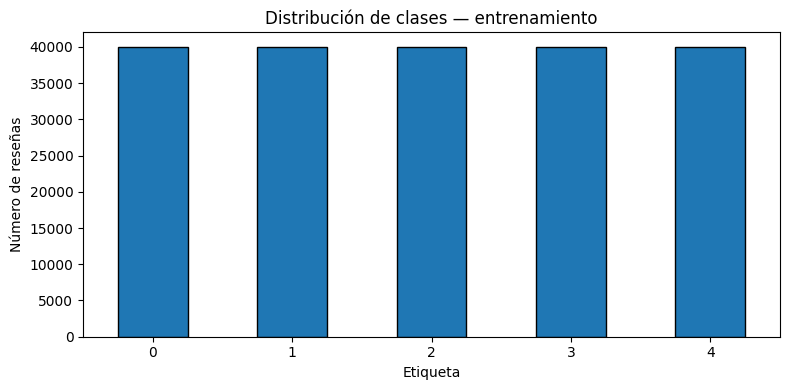

In [ ]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()

print("CALIDAD DE DATOS")
print(f"Registros: {len(train_df):,}")
print(f"Valores nulos por columna:\n{train_df.isna().sum()}")
print("Textos vacios:", train_df["text"].fillna("").str.strip().eq("").sum())
print("IDs duplicados:", train_df["id"].duplicated().sum())
print("Textos duplicados:", train_df["text"].duplicated().sum())

print("\nETIQUETAS")
print("Valores unicos:", sorted(train_df["label"].unique()))
print("\nRelacion label / label_text:")
print(pd.crosstab(train_df["label"], train_df["label_text"]))

print("DISTRIBUCION DE CLASES")
distribucion = (train_df["label"].value_counts().sort_index().rename_axis("Clase").to_frame("Frecuencia"))

distribucion["Porcentaje"] = (distribucion["Frecuencia"] / len(train_df) * 100)

display(distribucion)

ax = distribucion["Frecuencia"].plot(kind="bar", figsize=(8, 4), edgecolor="black")
ax.set_title("Distribución de clases — entrenamiento")
ax.set_xlabel("Etiqueta")
ax.set_ylabel("Número de reseñas")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

No necesitaremos técnicas para el problema de balanceo de clases, encontramos 1736 textos duplicados, estos pueden ser que varios usuarios esciben reseñas como "Muy bueno" y poner valoraciones diferentes

### Longitud de las cadenas

ESTADISTICAS DE LONGITUD
count    200000.000000
mean         27.799670
std          24.173565
min           2.000000
25%          13.000000
50%          22.000000
75%          34.000000
90%          54.000000
95%          72.000000
99%         121.000000
max         551.000000
Name: n_words, dtype: float64

LONGITUD POR CLASE


,mean,median,max
label,,,
0,28.47,22.0,407
1,31.29,24.0,506
2,28.82,23.0,458
3,25.88,21.0,394
4,24.53,20.0,551


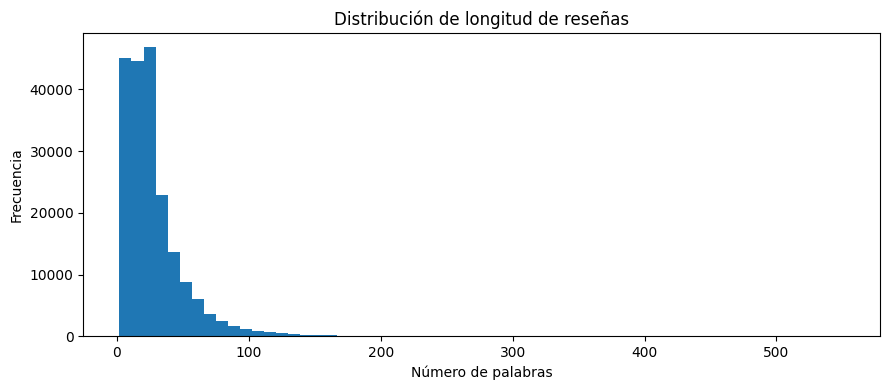

In [ ]:
train_df["n_words"] = (train_df["text"].fillna("").str.count(r"\S+"))

print("ESTADISTICAS DE LONGITUD")
print(train_df["n_words"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

print("\nLONGITUD POR CLASE")
display(train_df.groupby("label")["n_words"].agg(["mean", "median", "max"]).round(2))

plt.figure(figsize=(9, 4))
plt.hist(train_df["n_words"], bins=60)
plt.title("Distribución de longitud de reseñas")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Ejemplos representativos por clase

In [ ]:
print("EJEMPLOS POR CLASE")

for clase in sorted(train_df["label"].unique()):
    ejemplos = train_df.loc[train_df["label"] == clase].sample(n=2, random_state=42)
    print(f"\n{'=' * 55}")
    print(f"CLASE {clase}")

    for _, fila in ejemplos.iterrows():
        print(f"\nReseña: {fila['text'][:350]}")
        print(f"Etiqueta: {fila['label']}")

EJEMPLOS POR CLASE

CLASE 0

Reseña: Pedí la botella por comodidad al salir a pasear con Sherlock... Pero ha sido una decepción. Cuando llegó tenia el plástico que ancla la botella con el bebedero roto. Me he puesto en contacto con el vendedor y estoy a la espera de noticias...
Etiqueta: 0

Reseña: lo compré por ser SONY, pero la calidad de sonido me parece pésima. Ni siquiera se oyen los graves ... solo agudos y medios. A los 10min acabé harto
Etiqueta: 0

CLASE 1

Reseña: Necesitaba un reposapiés para mi hijo pero este lo tuve que devolver. No sube tengo como esperaba y no le llegan los pies de forma cómoda. Tampoco se puede fijar la plataforma que se balancea siempre
Etiqueta: 1

Reseña: Embalaje correcto. Presenta un fallo de diseño en el sistema de sujeción al no ir montado sobre un riel, sino en un listón que se suelta. Solucionado taladrando la pizarra y sujetándolo con alcayatas. Calidad media baja.
Etiqueta: 1

CLASE 2

Reseña: Funciona pero me ha llegado sucio y parece usado.

Las etiquetas parecen a lo que apuntaban: 0 corresponde a un descontento total por parte del cliente; 1 hace referencia a un descontento donde describen algunas falencias técnicas y estas parecen ser las razones del disgusto; 2 parece ser que el comprador no muestra unaa inconformidad a nivel de solicitar un reembolso pero si puede destacar aspectos negativos de lo que ha llegado a sus manos; 3 podemos ver reseñas un poco más conformes con lo recibido, aunque no una satifacción completa; finalmente 4 es lo que relacionariamos con "5 estrellas" donde se nota contento y totalmente satisfecho.

### Duplicados y etiquetas contradictorias

este análisis inspecciona también el conjunto de prueba para detectar contaminación estructural, pero no utiliza sus etiquetas para seleccionar hiperparámetros ni calcular resultados de modelos. Lo mantendremos separado de cualquier decisión sobre desempeño

In [ ]:
# Normalizacion conservadora: Unicode y espacios, conserva mayusculas y puntuacin
def normalizar_texto(texto):
    texto = unicodedata.normalize("NFC", texto)
    return re.sub(r"\s+", " ", texto).strip()

dfs = {
    split: dataset[split].to_pandas()
    for split in ["train", "validation", "test"]
}

for df in dfs.values():
    df["text_key"] = df["text"].map(normalizar_texto)

# Duplicados y conflictos internos de entrenamiento
train = dfs["train"]

grupos = train.groupby("text_key")["label"].agg(registros="size", etiquetas_distintas="nunique")
repetidos = grupos[grupos["registros"] > 1]
conflictivos = grupos[grupos["etiquetas_distintas"] > 1]

print("DUPLICADOS EN TRAIN")
print("Grupos repetidos:", len(repetidos))
print("Registros adicionales repetidos:", int((repetidos["registros"] - 1).sum()))
print("CONFLICTOS DE ETIQUETAS")
print("Grupos conflictivos:", len(conflictivos))
print("Registros involucrados:", int(conflictivos["registros"].sum()))
print("EJEMPLOS DE CONFLICTOS")
for texto in conflictivos.head(5).index:
    registros = train.loc[train["text_key"] == texto]
    print("\nTexto:", repr(texto[:250]))
    print("Etiquetas:", registros["label"].value_counts().sort_index().to_dict())

# Solapamiento entre particiones
print("\nSOLAPAMIENTO ENTRE PARTICIONES")

pares = [("train", "validation"), ("train", "test"), ("validation", "test")]

for a, b in pares:
    claves_a = set(dfs[a]["text_key"])
    claves_b = set(dfs[b]["text_key"])
    compartidos = claves_a & claves_b
    registros_a = dfs[a]["text_key"].isin(compartidos).sum()
    registros_b = dfs[b]["text_key"].isin(compartidos).sum()

    ids_compartidos = (set(dfs[a]["id"]) & set(dfs[b]["id"]))

    print(f"\n{a} vs {b}")
    print("Textos unicos compartidos:", len(compartidos))
    print(f"Registros involucrados en {a}: {registros_a}")
    print(f"Registros involucrados en {b}: {registros_b}")
    print("IDs compartidos:", len(ids_compartidos))

DUPLICADOS EN TRAIN
Grupos repetidos: 747
Registros adicionales repetidos: 1736
CONFLICTOS DE ETIQUETAS
Grupos conflictivos: 398
Registros involucrados: 1654
EJEMPLOS DE CONFLICTOS

Texto: 'A mi hija le encanta'
Etiquetas: {2: 1, 3: 1, 4: 1}

Texto: 'A mi hija le encanto'
Etiquetas: {3: 1, 4: 1}

Texto: 'A mi hija le ha encantado'
Etiquetas: {3: 1, 4: 4}

Texto: 'A mi hijo le encanta'
Etiquetas: {3: 1, 4: 3}

Texto: 'A mi hijo le encantó'
Etiquetas: {3: 2, 4: 1}

SOLAPAMIENTO ENTRE PARTICIONES

train vs validation
Textos unicos compartidos: 66
Registros involucrados en train: 384
Registros involucrados en validation: 71
IDs compartidos: 0

train vs test
Textos unicos compartidos: 57
Registros involucrados en train: 419
Registros involucrados en test: 63
IDs compartidos: 0

validation vs test
Textos unicos compartidos: 9
Registros involucrados en validation: 14
Registros involucrados en test: 12
IDs compartidos: 0


In [ ]:
print(f"{int((repetidos["registros"] - 1).sum())*100/len(train)}%")

0.868%


**DECISIÓN**

**Para TRAIN:** conservar los registros originales, incluidos los duplicados y las etiquetas contradictorias. Su proporción es relativamente baja (0.868%)

**Para VALIDATION:** excluir registros cuyo texto normalizado aparezca en Train

**Para TEST:** Excluir registros cuyo texto normalizado aparezca en Train o Validation

Esta estrategia conserva el conjunto de entrenamiento completo, evita usar Test para modificar el entrenamiento y establece particiones de evaluación sin coincidencias exactas entre ellas

### Construcción de las particiones sin solapamiento

In [ ]:
# Claves obtenidas en la celda 8
train_keys = set(dfs["train"]["text_key"])
validation_keys = set(dfs["validation"]["text_key"])

# La validacion no debe contener textos presentes en Train
validation_clean = dataset["validation"].filter(lambda ejemplo: normalizar_texto(ejemplo["text"]) not in train_keys)

# Test no debe contener textos presentes en Train ni en la validacion original
test_clean = dataset["test"].filter(lambda ejemplo: normalizar_texto(ejemplo["text"]) not in (train_keys | validation_keys))

dataset_clean = DatasetDict({
    "train": dataset["train"],
    "validation": validation_clean,
    "test": test_clean
})

print("COMPARACION DE PARTICIONES")

for split in dataset.keys():
    original = len(dataset[split])
    limpio = len(dataset_clean[split])

    print(f"{split}: {original:,} -> {limpio:,}\n(excluidos: {original - limpio:,})")

# Verificar independencia por coincidencia exacta normalizada
claves_limpias = {
    split: {
        normalizar_texto(texto)
        for texto in dataset_clean[split]["text"]
    }
    for split in dataset_clean.keys()
}

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    interseccion = claves_limpias[a] & claves_limpias[b]

print("\nVerificacion completada:")
print("No hay textos normalizados compartidos entre particiones.")

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

COMPARACION DE PARTICIONES
train: 200,000 -> 200,000
(excluidos: 0)
validation: 5,000 -> 4,929
(excluidos: 71)
test: 5,000 -> 4,934
(excluidos: 66)

Verificacion completada:
No hay textos normalizados compartidos entre particiones.


``dataset`` datos originales descargados

``dataset_clean`` datos preparados para los experimentos, conservando Train y filtrando Validation y Test.

### Prearacion de los datos para BETO

### Instalar y cargar el tokenizador

In [ ]:
%pip install -q transformers

In [ ]:
MODEL_ID = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
texto = "El producto es excelente, pero llegó tarde"
tokens = tokenizer.tokenize(texto)
ids = tokenizer(texto, add_special_tokens=True )["input_ids"]

print("Texto original:", texto)
print("Tokens:", tokens)
print("IDs:", ids)
print("Longitud:", len(ids))
print("Vocabulario:", tokenizer.vocab_size)
print("Longitud maxima del modelo:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/310 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/486k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Texto original: El producto es excelente, pero llegó tarde
Tokens: ['el', 'producto', 'es', 'excelente', ',', 'pero', 'llegó', 'tarde']
IDs: [4, 1039, 4525, 1028, 5556, 1019, 1195, 3665, 2324, 5]
Longitud: 10
Vocabulario: 31002
Longitud maxima del modelo: 512


In [ ]:
SEED = 42
MAX_LENGTH = 128

def normalizar_texto(texto):
    texto = unicodedata.normalize("NFC", texto)
    return re.sub(r"\s+", " ", texto).strip()

train_keys = {
    normalizar_texto(t)
    for t in dataset["train"]["text"]
}

validation_keys = {
    normalizar_texto(t)
    for t in dataset["validation"]["text"]
}

blocked_test_keys = train_keys | validation_keys

dataset_clean = DatasetDict({
    "train": dataset["train"],
    "validation": dataset["validation"].filter(lambda x: normalizar_texto(x["text"]) not in train_keys),
    "test": dataset["test"].filter(lambda x: normalizar_texto(x["text"]) not in blocked_test_keys)
})

def tokenizar(batch):
    resultado = tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)
    resultado["labels"] = batch["label"]
    return resultado

data_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        )
    }

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

### Longitudes tokenizadas

Ahora sí mediremos las longitudes utilizando el tokenizador real, no contando palabras

LONGITUDES TOKENIZADAS
Mediana: 28.0
P90: 68.0
P95: 90.0
P99: 156.0
Máximo: 413

PORCENTAJE QUE EXCEDE CADA LIMITE
64 tokens: 11.22%
128 tokens: 1.79%
256 tokens: 0.13%
512 tokens: 0.00%


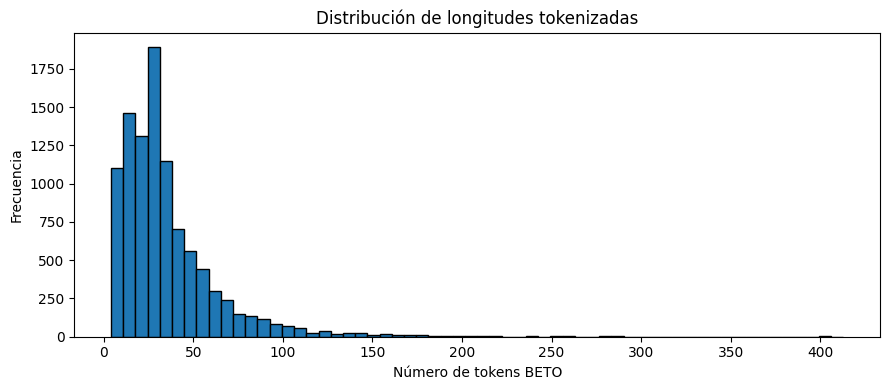

In [ ]:
#muestra aleatoria reproducible del entrenamiento
muestra = (dataset_clean["train"].shuffle(seed=42).select(range(10_000)))
codificacion = tokenizer(muestra[:]["text"], truncation=False, padding=False, add_special_tokens=True)
longitudes = np.array([len(ids) for ids in codificacion["input_ids"]])

print("LONGITUDES TOKENIZADAS")
print("Mediana:", np.median(longitudes))
print("P90:", np.percentile(longitudes, 90))
print("P95:", np.percentile(longitudes, 95))
print("P99:", np.percentile(longitudes, 99))
print("Máximo:", longitudes.max())

print("\nPORCENTAJE QUE EXCEDE CADA LIMITE")
for limite in [64, 128, 256, 512]:
    porcentaje = np.mean(longitudes > limite) * 100
    print(f"{limite} tokens: {porcentaje:.2f}%")

plt.figure(figsize=(9, 4))
plt.hist(longitudes, bins=60, edgecolor="black")
plt.xlabel("Número de tokens BETO")
plt.ylabel("Frecuencia")
plt.title("Distribución de longitudes tokenizadas")
plt.tight_layout()
plt.show()

Se identificó que el 98,21 % de las reseñas contiene 128 tokens o menos, mientras que el 99,87 % no supera los 256 tokens.

A partir de estos resultados, se estableció una longitud máxima de 128 tokens para el fine-tuning de BETO, buscando un equilibrio entre conservación de información y eficiencia computacional.

## Busqueda de Hiperparametros

### Muestreo estratificado

In [ ]:
SEED = 42
MAX_LENGTH = 128
N_EXPERIMENT = 20_000
train_original = dataset_clean["train"]
indices = np.arange(len(train_original))
etiquetas = np.asarray(train_original[:]["label"])

# Seleccion aleatoria estratificada
indices_piloto, _ = train_test_split(indices, train_size=N_EXPERIMENT, stratify=etiquetas, random_state=SEED)

#dataset para los experimentos
dataset_piloto = DatasetDict({
    "train": train_original.select(indices_piloto.tolist()),
    "validation": dataset_clean["validation"]
})

print("PARTICIONES EXPERIMENTALES")
print(dataset_piloto)

print("\nDISTRIBUCIÓN DE CLASES")
print(pd.Series(dataset_piloto["train"][:]["label"]).value_counts().sort_index())

PARTICIONES EXPERIMENTALES
DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 4929
    })
})

DISTRIBUCIÓN DE CLASES
0    4000
1    4000
2    4000
3    4000
4    4000
Name: count, dtype: int64


### Tokenización del dataset Experimental

transformar las reseñas en representaciones numéricas que BETO pueda procesar, utilizando MAX_LENGTH = 128

Ejecuta tres operaciones fundamentales:

1. Tokenización: convierte las reseñas en input_ids (identificadores de tokens), attention_mask (máscara que diferencia tokens reales del padding) y labels (clase correcta).

2. Truncamiento: limita las entradas a 128 tokens

3. Padding dinámico: no rellenamos todas las reseñas hasta 128 tokens. DataCollatorWithPadding igualará las longitudes únicamente dentro de cada batch, reduciendo el procesamiento innecesario.

Por ejemplo, si un batch contiene secuencias de 20, 35, 48 y 60 tokens, el collator las rellenará hasta 60, no hasta 128.

In [ ]:
# Funcion de tokenizacion
def tokenizar(batch):
    resultado = tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)
    resultado["labels"] = batch["label"]
    return resultado

# Tokenizacin de entrenamiento y validacion
dataset_tokenizado = dataset_piloto.map(tokenizar, batched=True, remove_columns=dataset_piloto["train"].column_names, desc="Tokenizando reseñas")

#pdding dinamico durante el entrenamiento
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")
print("DATASET TOKENIZADO")
print(dataset_tokenizado)
print("\nPRIMER EJEMPLO")
ejemplo = dataset_tokenizado["train"][0]
print("input_ids:", ejemplo["input_ids"][:20])
print("attention_mask:", ejemplo["attention_mask"][:20])
print("labels:", ejemplo["labels"])
print("Longitud:", len(ejemplo["input_ids"]))

# Construir un batch de prueba
batch = data_collator([
    dataset_tokenizado["train"][i]
    for i in range(4)
])

print("\nDIMENSIONES DEL BATCH")
for nombre, tensor in batch.items():
    print(f"{nombre}: {tuple(tensor.shape)}")

Tokenizando reseñas:   0%|          | 0/20000 [00:00<?, ? examples/s]

Tokenizando reseñas:   0%|          | 0/4929 [00:00<?, ? examples/s]

DATASET TOKENIZADO
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 4929
    })
})

PRIMER EJEMPLO
input_ids: [4, 1440, 13162, 1048, 1411, 9310, 1019, 5529, 1041, 1039, 1098, 10463, 21347, 13417, 1040, 1086, 20716, 1076, 1811, 2401]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
labels: 0
Longitud: 47

DIMENSIONES DEL BATCH
input_ids: (4, 47)
token_type_ids: (4, 47)
attention_mask: (4, 47)
labels: (4,)


### Ejecución de la busqueda de hiperparametros

In [ ]:
%pip install -q accelerate

In [ ]:
LEARNING_RATES = [2e-5, 3e-5, 5e-5]
WEIGHT_DECAYS = [0.0, 0.05]
EPOCHS = 3
BATCH_SIZE = 16
OUTPUT_DIR = Path("./experimentos_beto")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = OUTPUT_DIR / "resultados.csv"

# Liberar referencias del entrenamiento anterior, si existen
globals().pop("trainer", None)
globals().pop("model", None)
gc.collect()
torch.cuda.empty_cache()

# METRICAS

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro", zero_division=0)
    }

# Recuperar resultados de ejecuciones anteriores
if RESULTS_PATH.exists():
    resultados = pd.read_csv(RESULTS_PATH).to_dict("records")
else:
    resultados = []

combinaciones = list(product(
    LEARNING_RATES,
    WEIGHT_DECAYS
))

print(f"Experimentos planificados: {len(combinaciones)}")
print(f"Evaluaciones previstas: {len(combinaciones) * EPOCHS}")

# GRID SEARCH

for numero, (lr, wd) in enumerate(combinaciones, start=1):
    run_id = f"lr_{lr:.0e}_wd_{wd:.2f}"
    # No repetir experimentos ya completados
    registros_previos = [
        r for r in resultados
        if r["run_id"] == run_id
    ]

    if len(registros_previos) == EPOCHS:
        print(f"\nOmitiendo experimento completado: {run_id}")
        continue

    print(f"\n{'=' * 60}")
    print(f"EXPERIMENTO {numero}/{len(combinaciones)}")
    print(f"Learning rate: {lr}")
    print(f"Weight decay: {wd}")
    print(f"{'=' * 60}")

    #inicializacion independiente y reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, num_labels=5)

    args = TrainingArguments(output_dir=str(OUTPUT_DIR / run_id), learning_rate=lr, weight_decay=wd, num_train_epochs=EPOCHS,
                             per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=32, optim="adamw_torch",
                             lr_scheduler_type="linear", warmup_steps=0.1, eval_strategy="epoch", logging_strategy="epoch",
                             save_strategy="no", fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(),
                             seed=SEED, data_seed=SEED, report_to="none")

    trainer = Trainer(model=model, args=args, train_dataset=dataset_tokenizado["train"], eval_dataset=dataset_tokenizado["validation"], processing_class=tokenizer, data_collator=data_collator, compute_metrics=compute_metrics)
    entrenamiento = trainer.train()

    # REGISTRAR RESULTADOS DE CADA EPOCA
    registros_actuales = []
    for registro in trainer.state.log_history:
        if "eval_f1_macro" not in registro:
            continue
        registros_actuales.append({
            "run_id": run_id,
            "learning_rate": lr,
            "weight_decay": wd,
            "epoca": int(round(registro["epoch"])),
            "val_loss": registro["eval_loss"],
            "accuracy": registro["eval_accuracy"],
            "f1_macro": registro["eval_f1_macro"],
            "tiempo_total_s": entrenamiento.metrics["train_runtime"]
        })

    if len(registros_actuales) != EPOCHS:
        raise RuntimeError(f"{run_id}: se esperaban {EPOCHS} evaluaciones, pero se encontraron {len(registros_actuales)}")

    resultados = [r for r in resultados if r["run_id"] != run_id]
    resultados.extend(registros_actuales)

    #guardar resultados al finalizar cada experimento
    pd.DataFrame(resultados).to_csv(RESULTS_PATH, index=False)

    print("\nResultados del experimento:")
    display(pd.DataFrame(registros_actuales))
    # Liberar memoria GPU
    del trainer, model, entrenamiento
    gc.collect()
    torch.cuda.empty_cache()


# COMPARACION FINAl
resultados_df = pd.DataFrame(resultados)
if resultados_df.empty:
    raise RuntimeError("No hay resultados experimentales.")

# Mejor epoca de cada combinación
mejores_por_config = (resultados_df.sort_values(["f1_macro", "val_loss"], ascending=[False, True]).drop_duplicates("run_id").reset_index(drop=True))

print("\nMEJORES RESULTADOS POR CONFIGURACION")
display(mejores_por_config)

print("\nMEJOR CONFIGURACION GLOBAL")
display(mejores_por_config.head(1))
mejores_por_config.to_csv(OUTPUT_DIR / "mejores_configuraciones.csv", index=False)
print(f"\nResultados guardados en: {OUTPUT_DIR}")


Experimentos planificados: 6
Evaluaciones previstas: 18

EXPERIMENTO 1/6
Learning rate: 2e-05
Weight decay: 0.0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.161254,1.056633,0.527287,0.526023
2,0.914693,1.039192,0.544127,0.543695
3,0.727100,1.142836,0.544735,0.544391



Resultados del experimento:


,run_id,learning_rate,weight_decay,epoca,val_loss,accuracy,f1_macro,tiempo_total_s
0,lr_2e-05_wd_0.00,0.00002,0.0,1,1.056633,0.527287,0.526023,1574.8553
1,lr_2e-05_wd_0.00,0.00002,0.0,2,1.039192,0.544127,0.543695,1574.8553
2,lr_2e-05_wd_0.00,0.00002,0.0,3,1.142836,0.544735,0.544391,1574.8553


... (31 outputs left out)

,run_id,learning_rate,weight_decay,epoca,val_loss,accuracy,f1_macro,tiempo_total_s
0,lr_3e-05_wd_0.00,0.00003,0.00,2,1.038984,0.547373,0.548061,1590.1317
1,lr_3e-05_wd_0.05,0.00003,0.05,2,1.038639,0.546561,0.546553,1603.3158
2,lr_2e-05_wd_0.05,0.00002,0.05,2,1.039554,0.546155,0.545671,1603.9038
3,lr_2e-05_wd_0.00,0.00002,0.00,3,1.142836,0.544735,0.544391,1574.8553
4,lr_5e-05_wd_0.05,0.00005,0.05,2,1.052673,0.545750,0.544203,1603.0144
5,lr_5e-05_wd_0.00,0.00005,0.00,3,1.241245,0.536823,0.538551,1589.2548



MEJOR CONFIGURACION GLOBAL


,run_id,learning_rate,weight_decay,epoca,val_loss,accuracy,f1_macro,tiempo_total_s
0,lr_3e-05_wd_0.00,0.00003,0.0,2,1.038984,0.547373,0.548061,1590.1317



Resultados guardados en: experimentos_beto


### Validación de experimentos

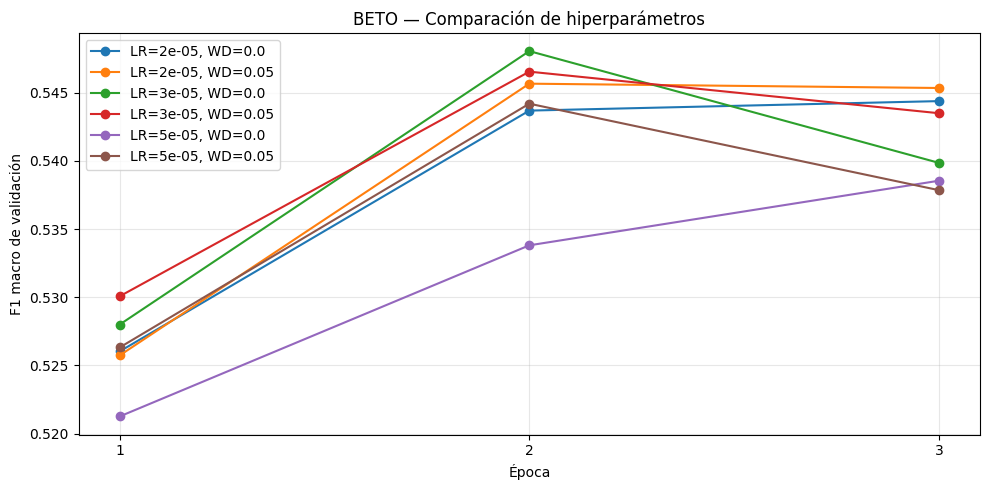

In [ ]:
resultados_df = pd.read_csv("experimentos_beto/resultados.csv")
plt.figure(figsize=(10, 5))
for (lr, wd), grupo in resultados_df.groupby(["learning_rate", "weight_decay"]):
    grupo = grupo.sort_values("epoca")
    plt.plot(grupo["epoca"], grupo["f1_macro"], marker="o", label=f"LR={lr:.0e}, WD={wd}")

plt.title("BETO — Comparación de hiperparámetros")
plt.xlabel("Época")
plt.ylabel("F1 macro de validación")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Resultados de la búsqueda de hiperparámetros

Se evaluaron seis configuraciones de fine-tuning de BETO mediante combinaciones de tres learning rates (2e-5, 3e-5 y 5e-5) y dos valores de weight decay (0,0 y 0,05), utilizando 20.000 reseñas de entrenamiento y 4.929 de validación.

La mejor configuración obtuvo un F1 macro de **0,5481** y una exactitud del **54,74 %**, con un learning rate de 3e-5, weight decay de 0,0 y dos épocas de entrenamiento.

Se observó que, en varias configuraciones, la pérdida de validación aumentó durante la tercera época y que el F1 macro dejó de mejorar o disminuyó. Este comportamiento es compatible con sobreajuste.

Se seleccionó la configuración de mayor F1 macro para el entrenamiento definitivo. Las diferencias pequeñas entre algunas configuraciones no permiten afirmar que una sea universalmente superior; los resultados corresponden a una muestra experimental y una semilla específica.

### Almacenamiento persistente

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP")

EXPERIMENT_DIR = PROJECT_DIR / "experimentos"
CHECKPOINT_DIR = PROJECT_DIR / "beto_checkpoints"
FINAL_MODEL_DIR = PROJECT_DIR / "beto_final"

# Buscar el último checkpoint guardado
ultimo_checkpoint = get_last_checkpoint(str(CHECKPOINT_DIR))

if ultimo_checkpoint is None:
    raise RuntimeError("No se encontró ningún checkpoint. No inicies el entrenamiento desde cero")

print("Checkpoint encontrado:", ultimo_checkpoint)

Mounted at /content/drive
Checkpoint encontrado: /content/drive/MyDrive/Proyecto_02_NLP/beto_checkpoints/checkpoint-30000


### Tokenización del dataset completo

Hasta ahora hemos entrenado utilizando 20.000 reseñas. Para el entrenamiento definitivo utilizaremos las 200.000 reseñas de Train y las 4.929 de Validation.

In [ ]:
dataset_final = DatasetDict({
    "train": dataset_clean["train"],
    "validation": dataset_clean["validation"]
})

dataset_final_tokenizado = dataset_final.map(tokenizar, batched=True, remove_columns=dataset_final["train"].column_names, desc="Tokenizando dataset completo")
print("DATASET FINAL TOKENIZADO")
print(dataset_final_tokenizado)


Tokenizando dataset completo:   0%|          | 0/200000 [00:00<?, ? examples/s]

Tokenizando dataset completo:   0%|          | 0/4929 [00:00<?, ? examples/s]

DATASET FINAL TOKENIZADO
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 4929
    })
})


### Fine-Tuning de BETO

In [ ]:
BEST_LR = 3e-5
BEST_WD = 0.0
MAX_EPOCHS = 8
BATCH_SIZE = 16
EVAL_STEPS = 5000

set_seed(SEED)
model_final = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, num_labels=5)
args_final = TrainingArguments(output_dir=str(CHECKPOINT_DIR), learning_rate=BEST_LR, weight_decay=BEST_WD,
                               num_train_epochs=MAX_EPOCHS, per_device_train_batch_size=BATCH_SIZE,
                               per_device_eval_batch_size=32, optim="adamw_torch", lr_scheduler_type="linear",
                               warmup_steps=0.1, eval_strategy="steps", eval_steps=EVAL_STEPS, logging_strategy="steps",
                               logging_steps=500, save_strategy="steps", save_steps=EVAL_STEPS, save_total_limit=2,
                               save_only_model=False, load_best_model_at_end=True, metric_for_best_model="f1_macro",
                               greater_is_better=True, restore_callback_states_from_checkpoint=True,
                               fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(), seed=SEED,
                               data_seed=SEED, report_to="none" )

trainer_final = Trainer(model=model_final, args=args_final, train_dataset=dataset_final_tokenizado["train"],
                        eval_dataset=dataset_final_tokenizado["validation"], processing_class=tokenizer,
                        data_collator=data_collator, compute_metrics=compute_metrics,
                        callbacks=[EarlyStoppingCallback(early_stopping_patience=3, early_stopping_threshold=0.001)])

#Buscar checkpoint anterior para reanudar si es necesario
ultimo_checkpoint = get_last_checkpoint(str(CHECKPOINT_DIR))

if ultimo_checkpoint:
    print("Reanudando desde:", ultimo_checkpoint)
else:
    raise RuntimeError("No hay checkpoint para reanudar")

resultado_final = trainer_final.train(resume_from_checkpoint=ultimo_checkpoint)

#Guardar los mejores pesos cargados al finalizar
trainer_final.save_model(str(FINAL_MODEL_DIR))
tokenizer.save_pretrained(str(FINAL_MODEL_DIR))

#guardar historial de metricas
historial = pd.DataFrame(trainer_final.state.log_history)

historial.to_csv(EXPERIMENT_DIR / "historial_entrenamiento_final.csv", index=False)

print("\nENTRENAMIENTO FINALIZADO")
print("Mejor checkpoint:", trainer_final.state.best_model_checkpoint)
print("Mejor F1 macro:", trainer_final.state.best_metric)
print("Modelo guardado en:", FINAL_MODEL_DIR)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

Step,Training Loss,Validation Loss,Accuracy,F1 Macro
35000,0.846620,0.989076,0.567458,0.565418


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


ENTRENAMIENTO FINALIZADO
Mejor checkpoint: /content/drive/MyDrive/Proyecto_02_NLP/beto_checkpoints/checkpoint-20000
Mejor F1 macro: 0.5677377425905653
Modelo guardado en: /content/drive/MyDrive/Proyecto_02_NLP/beto_final


## Evaluación final — Sequence Classification

### Evaluacion del modelo sobre test

In [ ]:
#crgar el mejor modelo guardado
modelo_evaluacion = AutoModelForSequenceClassification.from_pretrained(str(FINAL_MODEL_DIR))

#tokenizar Test con la misma configuracio ndel entrenamiento
test_tokenizado = dataset_clean["test"].map(tokenizar, batched=True, remove_columns=dataset_clean["test"].column_names, desc="Tokenizando Test")

# Configurar evaluacion
args_evaluacion = TrainingArguments(output_dir=str(PROJECT_DIR / "evaluacion_test"), per_device_eval_batch_size=32, report_to="none")

trainer_evaluacion = Trainer(model=modelo_evaluacion, args=args_evaluacion, processing_class=tokenizer, data_collator=data_collator, compute_metrics=compute_metrics)
# Evaluacion y predicciones
resultado_test = trainer_evaluacion.predict(test_tokenizado)
y_real = resultado_test.label_ids
y_pred = np.argmax(resultado_test.predictions, axis=-1)
print("RESULTADOS FINALES — TEST")
print(f"Ejemplos evaluados: {len(y_real):,}")
print(f"Accuracy: {resultado_test.metrics['test_accuracy']:.4f}")
print(f"F1 macro: {resultado_test.metrics['test_f1_macro']:.4f}")
print(f"Test loss: {resultado_test.metrics['test_loss']:.4f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizando Test:   0%|          | 0/4934 [00:00<?, ? examples/s]

RESULTADOS FINALES — TEST
Ejemplos evaluados: 4,934
Accuracy: 0.5898
F1 macro: 0.5928
Test loss: 0.9381


### Metricas

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  1 estrella     0.7964    0.5796    0.6709       992
 2 estrellas     0.4920    0.6831    0.5720       991
 3 estrellas     0.5167    0.4975    0.5069       993
 4 estrellas     0.5376    0.5163    0.5267       984
 5 estrellas     0.7016    0.6735    0.6873       974

    accuracy                         0.5898      4934
   macro avg     0.6089    0.5900    0.5928      4934
weighted avg     0.6086    0.5898    0.5925      4934



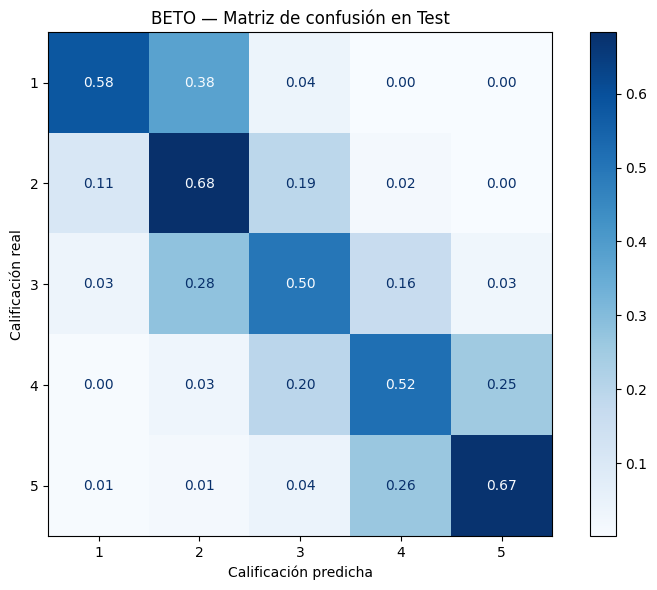

In [ ]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay)

nombres_clases = ["1 estrella", "2 estrellas", "3 estrellas", "4 estrellas", "5 estrellas"]

#precision, recall y F1 para cada clase
print("REPORTE DE CLASIFICACIÓN")
print(classification_report(y_real, y_pred, labels=[0, 1, 2, 3, 4], target_names=nombres_clases, digits=4, zero_division=0))

# Matriz de confusion normalizada por clase real
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_real, y_pred, labels=[0, 1, 2, 3, 4], display_labels=["1", "2", "3", "4", "5"], normalize="true", values_format=".2f", cmap="Blues", ax=ax)

ax.set_title("BETO — Matriz de confusión en Test")
ax.set_xlabel("Calificación predicha")
ax.set_ylabel("Calificación real")
plt.tight_layout()
plt.savefig(EXPERIMENT_DIR / "matriz_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Rendimiento por calificación

Se compara el F1-score de las cinco categorías de clasificación para identificar cuáles presentan mayor dificultad

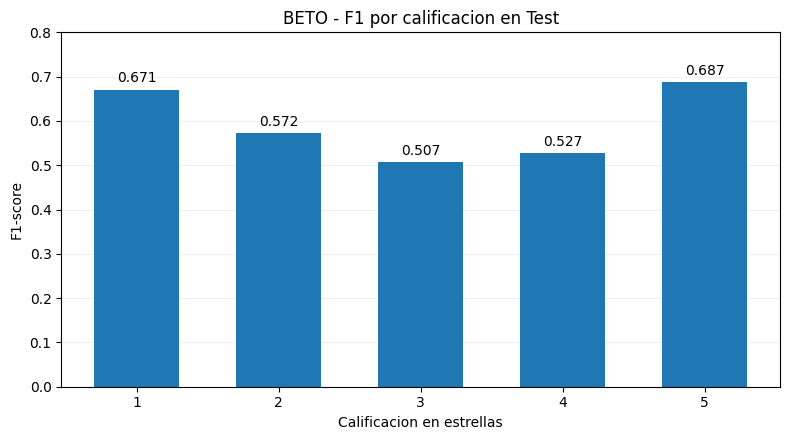

In [6]:
import matplotlib.pyplot as plt
from pathlib import Path

clases = ["1", "2", "3", "4", "5"]
f1 = [0.6709, 0.5720, 0.5069, 0.5267, 0.6873]
fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(clases, f1, width=0.6)
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set(title="BETO - F1 por calificacion en Test", xlabel="Calificacion en estrellas", ylabel="F1-score", ylim=(0, 0.8))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()

ruta = Path("/content/drive/MyDrive/Proyecto_02_NLP/experimentos")
if ruta.is_dir():
    plt.savefig(ruta / "f1_por_calificacion_test.png", dpi=160, bbox_inches="tight")

plt.show()

### Analisis de errores

In [ ]:
#analizar 3 errores por cada calificacion real
rng = np.random.default_rng(SEED)
ejemplos_error = []

for clase in range(5):
    indices = np.flatnonzero((y_real == clase) & (y_pred != clase))
    seleccion = rng.choice(indices, size=min(3, len(indices)), replace=False)

    for idx in seleccion:
        ejemplos_error.append({
            "Real": f"{y_real[idx] + 1} estrellas",
            "Predicción": f"{y_pred[idx] + 1} estrellas",
            "Reseña": dataset_clean["test"][int(idx)]["text"]
        })

errores_df = pd.DataFrame(ejemplos_error)
display(errores_df)

,Real,Predicción,Reseña
0,1 estrellas,3 estrellas,"El producto venía perfecto , pero mi carro est..."
1,1 estrellas,2 estrellas,El cristal es medio centimetro mas corto que l...
2,1 estrellas,2 estrellas,No tiene la medida para matriculas de motos es...
3,2 estrellas,3 estrellas,Calidad mejorable de video
4,2 estrellas,1 estrellas,No se parece a la foto.. Sublimación pésima......
5,2 estrellas,3 estrellas,"La medida está bien en su tamaño. Sin embargo,..."
6,3 estrellas,4 estrellas,Entrega rapida y producto correcto
7,3 estrellas,4 estrellas,Todo como esperaba. Según especificaciones
8,3 estrellas,2 estrellas,"No corrige nada la postura. Es un cojín, sin m..."
9,4 estrellas,5 estrellas,"Facil de montar, suena muy bien. Muy buena cal..."


### Conclusiones — Sequence Classification

Se realizó el fine-tuning del modelo BETO para clasificar reseñas en español según cinco niveles de calificación. Se evaluaron seis combinaciones de hiperparámetros y se seleccionó la mejor configuración mediante F1 macro de validación.

El entrenamiento definitivo utilizó 200.000 reseñas y un mecanismo de parada temprana, recuperando el checkpoint con mejor rendimiento de validación.

En el conjunto Test, compuesto por 4.934 reseñas, el modelo obtuvo una **accuracy del 58,98 % y un F1 macro de 0,5928**.

La matriz de confusión evidenció que los errores se concentran principalmente entre calificaciones cercanas. Las categorías intermedias, especialmente 3 y 4 estrellas, presentan mayores dificultades de clasificación.

Estos resultados muestran que BETO aprendió representaciones útiles para distinguir grados de satisfacción, aunque la clasificación precisa de opiniones ambiguas o mixtas continúa siendo una limitación.

# 2. Sequence Labeling — Reconocimiento de entidades nombradas

**Dominio y utilidad:** identificación automática de nombres de personas, organizaciones, lugares y otras entidades en textos periodísticos en español. Esta tarea resulta útil para la extracción de información y el análisis de documentos.

**Dataset:** CoNLL-2002 en español, cargado desde `BramVanroy/conll2002`. Contiene secuencias de palabras anotadas con etiquetas gramaticales y de entidades nombradas. Su estructura y particiones se describen a continuación.

**Datos de entrada:** secuencias de tokens (`tokens`).

**Variable de salida:** secuencia de etiquetas (`ner_tags`) en formato BIO, con nueve clases que representan los límites y tipos de entidades. Las etiquetas `pos_tags` están disponibles, pero no constituyen la variable objetivo del proyecto.

**Tipo de problema:** *Sequence Labeling*, específicamente Named Entity Recognition (NER).

**Arquitectura:** BETO cased (`dccuchile/bert-base-spanish-wwm-cased`), basado en el codificador Transformer BERT, con una capa de clasificación por token.

**Estrategia de aprendizaje:** transfer learning mediante fine-tuning supervisado, actualizando los pesos del modelo preentrenado para predecir etiquetas BIO.

**Evaluación:** precisión, recall y F1 a nivel de entidad completa, junto con análisis de errores y matrices de confusión.

In [ ]:
from datasets import load_dataset

DATASET_NER_ID = "BramVanroy/conll2002"
dataset_ner = load_dataset(DATASET_NER_ID, "es")

print(dataset_ner)
print("\nCaracterísticas:")
print(dataset_ner["train"].features)
print("\nPrimer ejemplo:")
print(dataset_ner["train"][0])

README.md:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.20MB            

es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  250kB            

es/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  237kB            

es/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8324 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1916 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1518 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 8324
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1916
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1518
    })
})

Características:
{'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(ClassLabel(names=['AO', 'AQ', 'CC', 'CS', 'DA', 'DE', 'DD', 'DI', 'DN', 'DP', 'DT', 'Faa', 'Fat', 'Fc', 'Fd', 'Fe', 'Fg', 'Fh', 'Fia', 'Fit', 'Fp', 'Fpa', 'Fpt', 'Fs', 'Ft', 'Fx', 'Fz', 'I', 'NC', 'NP', 'P0', 'PD', 'PI', 'PN', 'PP', 'PR', 'PT', 'PX', 'RG', 'RN', 'SP', 'VAI', 'VAM', 'VAN', 'VAP', 'VAS', 'VMG', 'VMI', 'VMM', 'VMN', 'VMP', 'VMS', 'VSG', 'VSI', 'VSM', 'VSN', 'VSP', 'VSS', 'Y', 'Z'])), 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']))}

Primer ejemplo:
{'id': '0', 'tokens

### Descripción del dataset — CoNLL-2002 (español)

Se utilizará el dataset **CoNLL-2002**, en su versión en español, para desarrollar una tarea de *Named Entity Recognition* (NER), perteneciente a **Sequence Labeling**.

#### Particiones del dataset

El dataset contiene **11.758 secuencias**, distribuidas en tres particiones:

| Partición | Secuencias | Propósito |
|---|---:|---|
| Train | 8.324 | Entrenamiento y ajuste de los parámetros del modelo |
| Validation | 1.916 | Evaluación durante el entrenamiento y selección de hiperparámetros |
| Test | 1.518 | Evaluación final sobre datos no utilizados en el ajuste del modelo |

Cada registro representa una secuencia de tokens y sus correspondientes anotaciones lingüísticas.

#### Estructura de los registros

Cada registro contiene cuatro campos:

| Campo | Tipo | Descripción |
|---|---|---|
| `id` | String | Identificador del registro |
| `tokens` | Lista de strings | Palabras y signos de puntuación que componen la secuencia |
| `pos_tags` | Lista de enteros | Etiquetas gramaticales (*Part-of-Speech Tagging*) |
| `ner_tags` | Lista de enteros | Etiquetas de entidades nombradas |

Las columnas `pos_tags` y `ner_tags` almacenan **índices enteros**, cuyos significados se encuentran definidos mediante `ClassLabel` en las características del dataset.

**`pos_tags`:** identifica la categoría gramatical de cada token, por ejemplo, sustantivos, verbos o signos de puntuación. Estas anotaciones forman parte del corpus, pero no serán nuestras etiquetas objetivo para NER.

**`ner_tags`:** indica si un token pertenece a una entidad nombrada y, en caso afirmativo, su categoría y posición dentro de ella. Será la variable objetivo de nuestro modelo.

Para cada registro, se cumple que el número de tokens coincide con el número de etiquetas POS y NER.

#### Categorías de entidades nombradas

El dataset contempla cuatro categorías:

| Categoría | Significado | Ejemplos |
|---|---|---|
| PER | Persona | Gabriel García Márquez |
| ORG | Organización | Naciones Unidas |
| LOC | Lugar o ubicación | Colombia, Medellín |
| MISC | Entidad miscelánea | Nombres propios que no pertenecen a las categorías anteriores, según los criterios de anotación del corpus |

Además, utiliza la etiqueta **O** (*Outside*) para los tokens que no forman parte de ninguna entidad nombrada.

#### 4. Esquema de etiquetado BIO

CoNLL-2002 utiliza el esquema **BIO**, que identifica la posición de un token dentro de una entidad.

- **B (Beginning):** primer token de una entidad.
- **I (Inside):** token que continúa una entidad.
- **O (Outside):** token que no pertenece a ninguna entidad.

Por tanto, las nueve etiquetas NER disponibles son:

| Índice | Etiqueta | Significado |
|---:|---|---|
| 0 | O | Fuera de una entidad |
| 1 | B-PER | Inicio de una persona |
| 2 | I-PER | Continuación de una persona |
| 3 | B-ORG | Inicio de una organización |
| 4 | I-ORG | Continuación de una organización |
| 5 | B-LOC | Inicio de un lugar |
| 6 | I-LOC | Continuación de un lugar |
| 7 | B-MISC | Inicio de una entidad miscelánea |
| 8 | I-MISC | Continuación de una entidad miscelánea |

Por ejemplo, la secuencia «Gabriel García Márquez nació en Colombia» podría etiquetarse como:

| Token | Etiqueta |
|---|---|
| Gabriel | B-PER |
| García | I-PER |
| Márquez | I-PER |
| nació | O |
| en | O |
| Colombia | B-LOC |

Este esquema permite representar entidades formadas por uno o varios tokens y distinguir entidades consecutivas.

## Analisis Exploratorio

In [ ]:
from collections import Counter, defaultdict
from itertools import combinations
import unicodedata
import re
import pandas as pd

label_names = dataset_ner["train"].features["ner_tags"].feature.names
pos_names = dataset_ner["train"].features["pos_tags"].feature.names

resumen_calidad = []

for split, ds in dataset_ner.items():
    registros = list(ds)

    nulos = sum(
        any(e[c] is None for c in ["id", "tokens", "pos_tags", "ner_tags"])
        for e in registros
    )

    nulos_internos = sum(
        any(x is None for c in ["tokens", "pos_tags", "ner_tags"] for x in (e[c] or [])) for e in registros)

    vacios = sum(
        e["tokens"] is not None and len(e["tokens"]) == 0
        for e in registros
    )

    tokens_invalidos = sum(
        e["tokens"] is not None
        and any(
            not isinstance(t, str) or not t.strip()
            for t in e["tokens"]
        )
        for e in registros
    )

    longitudes_inconsistentes = sum(all(e[c] is not None for c in ["tokens", "pos_tags", "ner_tags"]) and len({len(e["tokens"]), len(e["pos_tags"]), len(e["ner_tags"])}) != 1 for e in registros)

    ner_invalidas = sum(
        e["ner_tags"] is not None
        and any(
            not isinstance(tag, int) or not 0 <= tag < len(label_names)
            for tag in e["ner_tags"]
        )
        for e in registros
    )

    pos_invalidas = sum(
        e["pos_tags"] is not None
        and any(
            not isinstance(tag, int) or not 0 <= tag < len(pos_names)
            for tag in e["pos_tags"]
        )
        for e in registros
    )

    ids = [e["id"] for e in registros if e["id"] is not None]

    resumen_calidad.append({
        "Partición": split,
        "Registros": len(ds),
        "Registros con nulos": nulos,
        "Nulos dentro de listas": nulos_internos,
        "Secuencias vacías": vacios,
        "Tokens inválidos": tokens_invalidos,
        "Longitudes inconsistentes": longitudes_inconsistentes,
        "Etiquetas NER inválidas": ner_invalidas,
        "Etiquetas POS inválidas": pos_invalidas,
        "IDs duplicados adicionales": len(ids) - len(set(ids))
    })

calidad_df = pd.DataFrame(resumen_calidad)
display(calidad_df)


,Partición,Registros,Registros con nulos,Nulos dentro de listas,Secuencias vacías,Tokens inválidos,Longitudes inconsistentes,Etiquetas NER inválidas,Etiquetas POS inválidas,IDs duplicados adicionales
0,train,8324,0,0,1,0,0,0,0,0
1,validation,1916,0,0,1,0,0,0,0,0
2,test,1518,0,0,1,0,0,0,0,0


No se identificó valores nulos, tokens inválidos, inconsistencias entre las longitudes de las listas ni etiquetas NER o POS fuera de sus respectivos vocabularios. Tampoco se encontraron identificadores duplicados dentro de cada partición.

Sin embargo, se detectó **una secuencia vacía en Train, Validation y Test**, respectivamente. Aunque su presencia es marginal, estos registros deben considerarse durante el preprocesamiento, ya que no aportan tokens originales para la tarea de reconocimiento de entidades, en general, el dataset presenta una estructura consistente y adecuada para el entrenamiento supervisado

In [ ]:
def clave_texto(ejemplo):
    texto = " ".join(ejemplo["tokens"])
    texto = unicodedata.normalize("NFC", texto)
    return re.sub(r"\s+", " ", texto).strip()

claves_por_split = {}
resumen_duplicados = []

for split, ds in dataset_ner.items():
    grupos = defaultdict(list)
    registros_exactos = Counter()
    for indice, ejemplo in enumerate(ds):
        clave = clave_texto(ejemplo)
        grupos[clave].append((indice, tuple(ejemplo["ner_tags"])))
        registro_exacto = (tuple(ejemplo["tokens"]), tuple(ejemplo["pos_tags"]), tuple(ejemplo["ner_tags"]))
        registros_exactos[registro_exacto] += 1

    claves_por_split[split] = [clave_texto(e) for e in ds]
    grupos_repetidos = [grupo for grupo in grupos.values() if len(grupo) > 1]
    grupos_discrepantes = sum(len({etiquetas for _, etiquetas in grupo}) > 1 for grupo in grupos_repetidos)
    resumen_duplicados.append({
        "Partición": split,
        "Grupos de textos repetidos": len(grupos_repetidos),
        "Registros repetidos adicionales": sum(
            len(g) - 1 for g in grupos_repetidos
        ),
        "Duplicados exactos adicionales": sum(
            n - 1 for n in registros_exactos.values()
        ),
        "Grupos con etiquetas distintas": grupos_discrepantes
    })

print("DUPLICADOS POR PARTICIÓN")
display(pd.DataFrame(resumen_duplicados))

# Comparar las particiones entre s
solapamientos = []

for a, b in combinations(dataset_ner.keys(), 2):
    claves_a = claves_por_split[a]
    claves_b = claves_por_split[b]
    comunes = set(claves_a) & set(claves_b)

    #distinguir textos informativos de secuencias triviales
    comunes_largos = {
        texto for texto in comunes
        if len(texto.split()) >= 5
    }

    solapamientos.append({
        "Particiones": f"{a} / {b}",
        "Textos compartidos": len(comunes),
        "Textos compartidos (>= 5 tokens)": len(comunes_largos),
        "Registros afectados en " + a: sum(clave in comunes for clave in claves_a),
        "Registros afectados en " + b: sum(clave in comunes for clave in claves_b)
    })

print("\nSOLAPAMIENTOS ENTRE PARTICIONES")
display(pd.DataFrame(solapamientos))

DUPLICADOS POR PARTICIÓN


,Partición,Grupos de textos repetidos,Registros repetidos adicionales,Duplicados exactos adicionales,Grupos con etiquetas distintas
0,train,451,1871,1816,54
1,validation,96,422,419,3
2,test,57,240,238,2



SOLAPAMIENTOS ENTRE PARTICIONES


,Particiones,Textos compartidos,Textos compartidos (>= 5 tokens),Registros afectados en train,Registros afectados en validation,Registros afectados en test
0,train / validation,186,172,1463.0,531.0,NaN
1,train / test,112,106,1429.0,NaN,310.0
2,validation / test,22,19,NaN,337.0,204.0


Se identificaron **451 grupos de textos repetidos en Train, 96 en Validation y 57 en Test**. Adicionalmente, se encontraron 54, 3 y 2 grupos, respectivamente, en los cuales un mismo texto normalizado presenta diferentes secuencias de etiquetas NER.

Estas diferencias no necesariamente representan errores de anotación, pero requieren revisión.

El análisis entre particiones también identificó solapamientos:

- Train–Validation: 186 textos compartidos, de los cuales 172 tienen al menos cinco tokens.
- Train–Test: 112 textos compartidos, de los cuales 106 tienen al menos cinco tokens.
- Validation–Test: 22 textos compartidos, de los cuales 19 tienen al menos cinco tokens.

Estos resultados evidencian un **riesgo de fuga de información (*data leakage*)**, especialmente porque existen textos compartidos entre entrenamiento y evaluación. Sin embargo, la repetición de una secuencia no implica automáticamente que se trate de un error, puede responder a características del corpus original

In [ ]:
from collections import defaultdict
from itertools import combinations

indice_textos = {} #indexar cada texto con sus anotaciones e índices originales

for split, ds in dataset_ner.items():
    grupos = defaultdict(list)
    for i, ejemplo in enumerate(ds):
        grupos[clave_texto(ejemplo)].append((i, tuple(ejemplo["ner_tags"])))

    indice_textos[split] = grupos


#analizar solapamientos entre particiones
resumen_cruces = []
ejemplos_cruces = []

for a, b in combinations(dataset_ner.keys(), 2):
    comunes = set(indice_textos[a]) & set(indice_textos[b])
    relevantes = [t for t in comunes if len(t.split()) >= 5]
    discrepantes = 0
    for texto in relevantes:
        registros_a = indice_textos[a][texto]
        registros_b = indice_textos[b][texto]
        anotaciones = {
            etiquetas
            for _, etiquetas in registros_a + registros_b
        }

        hay_diferencias = len(anotaciones) > 1
        discrepantes += hay_diferencias
        ejemplos_cruces.append({
            "Particiones": f"{a} / {b}",
            "Texto": texto,
            f"Registros {a}": len(registros_a),
            f"Registros {b}": len(registros_b),
            "Anotaciones distintas": hay_diferencias,
            "Repeticiones totales": len(registros_a) + len(registros_b)
        })

    resumen_cruces.append({
        "Particiones": f"{a} / {b}",
        "Textos compartidos (>=5 tokens)": len(relevantes),
        "Textos con anotaciones distintas": discrepantes
    })

print("RESUMEN DE SOLAPAMIENTOS")
display(pd.DataFrame(resumen_cruces))
print("\nEJEMPLOS DE TEXTOS COMPARTIDOS")
cruces_df = pd.DataFrame(ejemplos_cruces)
display(cruces_df.sort_values( ["Anotaciones distintas", "Repeticiones totales"], ascending=[False, False] ).head(10))

print("\nEJEMPLOS DE ANOTACIONES CONTRADICTORIAS EN TRAIN")
conflictos_train = [(texto, registros) for texto, registros in indice_textos["train"].items() if len({tags for _, tags in registros}) > 1 and len(texto.split()) >= 5]

for texto, registros in conflictos_train[:3]:
    print("\nTexto:", texto[:350])
    vistos = set()
    for indice, tags in registros:
        if tags in vistos:
            continue
        vistos.add(tags)
        ejemplo = dataset_ner["train"][indice]
        entidades = [(token, label_names[tag]) for token, tag in zip( ejemplo["tokens"], ejemplo["ner_tags"] ) if tag != 0]

        print(f"Registro {indice}:", entidades[:20])
        if len(vistos) == 2:
            break

RESUMEN DE SOLAPAMIENTOS


,Particiones,Textos compartidos (>=5 tokens),Textos con anotaciones distintas
0,train / validation,172,33
1,train / test,106,19
2,validation / test,19,4



EJEMPLOS DE TEXTOS COMPARTIDOS


,Particiones,Texto,Registros train,Registros validation,Anotaciones distintas,Repeticiones totales,Registros test
80,train / validation,"París , 23 may ( EFE ) .",13.0,4.0,True,17,NaN
232,train / test,"San Sebastián , 23 may ( EFE ) .",10.0,NaN,True,11,1.0
200,train / test,"Málaga , 23 may ( EFE ) .",8.0,NaN,True,9,1.0
11,train / validation,La Fundación Española del Corazón llevará a ca...,2.0,1.0,True,3,NaN
52,train / validation,"El gerente del servicio 061 , Miguel Angel Rui...",2.0,1.0,True,3,NaN
58,train / validation,"El arzobispo de Mérida-Badajoz , Antonio Monte...",2.0,1.0,True,3,NaN
93,train / validation,El miembro de la Comisión Regional de UCE Emil...,2.0,1.0,True,3,NaN
171,train / validation,"El portavoz del Grupo Parlamentario del PP , C...",2.0,1.0,True,3,NaN
188,train / test,Huguet se ha mostrado hoy convencido de que su...,2.0,NaN,True,3,1.0
210,train / test,"Por tercera vez , el diputado de ERC Josep Hug...",2.0,NaN,True,3,1.0



EJEMPLOS DE ANOTACIONES CONTRADICTORIAS EN TRAIN

Texto: Así consta en una nota aclaratoria del grupo Telefónica a la Comisión Nacional del Mercado de Valores sobre las ampliaciones de capital que serán sometidas a aprobación de la Junta General de Accionistas de junio para llevar a cabo la operación de su filial Terra Network sobre la compra de Lycos , portal estadounidense de Internet .
Registro 121: [('Telefónica', 'B-ORG'), ('Comisión', 'B-ORG'), ('Nacional', 'I-ORG'), ('del', 'I-ORG'), ('Mercado', 'I-ORG'), ('de', 'I-ORG'), ('Valores', 'I-ORG'), ('Junta', 'B-MISC'), ('General', 'I-MISC'), ('de', 'I-MISC'), ('Accionistas', 'I-MISC'), ('Terra', 'B-ORG'), ('Network', 'I-ORG'), ('Lycos', 'B-ORG'), ('Internet', 'B-MISC')]
Registro 133: [('Telefónica', 'B-ORG'), ('Comisión', 'B-ORG'), ('Nacional', 'I-ORG'), ('del', 'I-ORG'), ('Mercado', 'I-ORG'), ('de', 'I-ORG'), ('Valores', 'I-ORG'), ('Junta', 'B-ORG'), ('General', 'I-ORG'), ('de', 'I-ORG'), ('Accionistas', 'I-ORG'), ('Terra', 'B-ORG'

In [ ]:
resumen_bio = []

for split, ds in dataset_ner.items():
    transiciones_invalidas = 0
    secuencias_afectadas = 0

    for ejemplo in ds:
        etiquetas = ejemplo["ner_tags"]
        errores_secuencia = 0
        for i, tag in enumerate(etiquetas):
            etiqueta = label_names[tag]

            if not etiqueta.startswith("I-"):
                continue

            tipo = etiqueta[2:]
            etiqueta_anterior = (label_names[etiquetas[i - 1]] if i > 0 else "O")

            if etiqueta_anterior not in (f"B-{tipo}", f"I-{tipo}"):
                errores_secuencia += 1

        transiciones_invalidas += errores_secuencia
        secuencias_afectadas += (errores_secuencia > 0)

    longitudes_split = [len(e["tokens"]) for e in ds]

    resumen_bio.append({
        "Partición": split,
        "Transiciones BIO inválidas": transiciones_invalidas,
        "Secuencias BIO afectadas": secuencias_afectadas,
        "Secuencias > 128 tokens": sum(n > 128 for n in longitudes_split),
        "Secuencias > 512 tokens": sum(n > 512 for n in longitudes_split),
        "Longitud máxima": max(longitudes_split)
    })

display(pd.DataFrame(resumen_bio))

,Partición,Transiciones BIO inválidas,Secuencias BIO afectadas,Secuencias > 128 tokens,Secuencias > 512 tokens,Longitud máxima
0,train,1,1,7,1,1238
1,validation,1,1,2,0,141
2,test,1,1,1,0,202


La validación del esquema BIO identificó **una transición inválida en cada partición**, afectando una secuencia de Train, una de Validation y una de Test, estas inconsistencias aparecen cuando una etiqueta `I-TIPO` no está precedida por `B-TIPO` o `I-TIPO` de la misma categoría, según el criterio de validación utilizado.

También se identificaron secuencias que superan los 128 tokens originales: siete en Train, dos en Validation y una en Test. Una secuencia de entrenamiento supera los 512 tokens originales.

Aunque las anomalías BIO son poco frecuentes, deben inspeccionarse antes de definir su tratamiento. Las secuencias largas también requieren atención, porque el truncamiento podría eliminar tokens y entidades anotadas.

In [ ]:
for split, ds in dataset_ner.items():
    print(f"\n{'=' * 55}")
    print(f"PARTICIÓN: {split.upper()}")
    print(f"{'=' * 55}")

    #secuencias vacia
    vacios = [i for i, e in enumerate(ds) if len(e["tokens"]) == 0]

    print("\nSecuencias vacías:")
    print([
        {"indice": i, "id": ds[i]["id"]}
        for i in vacios
    ])

    # Transiciones BIO invaldias
    print("\nTransiciones BIO inválidas:")

    for indice, ejemplo in enumerate(ds):
        etiquetas = ejemplo["ner_tags"]
        for j, tag in enumerate(etiquetas):
            actual = label_names[tag]

            if not actual.startswith("I-"):
                continue
            tipo = actual[2:]
            anterior = (label_names[etiquetas[j - 1]] if j > 0 else "O")

            if anterior not in (f"B-{tipo}", f"I-{tipo}"):
                inicio = max(0, j - 4)
                fin = min(len(etiquetas), j + 5)
                print({
                    "indice": indice,
                    "id": ejemplo["id"],
                    "token": ejemplo["tokens"][j],
                    "etiqueta": actual,
                    "etiqueta_anterior": anterior,
                    "contexto": list(zip(
                        ejemplo["tokens"][inicio:fin],
                        [label_names[t] for t in etiquetas[inicio:fin]]
                    ))
                })

    # Secuencias demasiado largas
    largos = sorted(enumerate(ds), key=lambda x: len(x[1]["tokens"]), reverse=True)[:3]
    print("\nTres secuencias mas largas:")
    for indice, ejemplo in largos:
        tokens = ejemplo["tokens"]
        print({
            "indice": indice,
            "id": ejemplo["id"],
            "longitud": len(tokens),
            "primeros_tokens": " ".join(tokens[:25]),
            "ultimos_tokens": " ".join(tokens[-15:])
        })


PARTICIÓN: TRAIN

Secuencias vacías:
[{'indice': 8323, 'id': '8323'}]

Transiciones BIO inválidas:
{'indice': 6731, 'id': '6731', 'token': 'San', 'etiqueta': 'I-LOC', 'etiqueta_anterior': 'O', 'contexto': [('San', 'I-LOC'), ('Sebastián', 'I-LOC'), (',', 'O'), ('23', 'O'), ('may', 'O')]}

Tres secuencias mas largas:
{'indice': 4161, 'id': '4161', 'longitud': 1238, 'primeros_tokens': 'VALOR ANTER. MAX. MIN. ULTIMO % VAR VOLUMEN ULT PTA - ALIMENTACION ALTADIS 16.44 16.35 15.76 16.00 -2.68 2997037 2662 AZ.EBRO AGR. 13.25 13.59 13.01', 'ultimos_tokens': '2.61 2.62 -3.32 1270 436 EFECOM finz.fch Harare , 23 may ( EFE ) .'}
{'indice': 4423, 'id': '4423', 'longitud': 314, 'primeros_tokens': 'Los valores que componen este indicador registraron hoy los siguientes resultados : VALOR ANTER. MAX. MIN. ULTIMO %VAR VOLUMEN ULT PTA - ACESA 9.87 9.90', 'ultimos_tokens': '7.23 7.30 7.13 7.13 -1.38 573710 1186 Asunción , 23 may ( EFE ) .'}
{'indice': 1294, 'id': '1294', 'longitud': 261, 'primeros_tokens

,Etiqueta,Train,Validation,Train (%)
0,O,231920,45356,87.61
1,B-PER,4321,1222,1.63
2,I-PER,3903,859,1.47
3,B-ORG,7390,1700,2.79
4,I-ORG,4992,1366,1.89
5,B-LOC,4913,984,1.86
6,I-LOC,1891,337,0.71
7,B-MISC,2173,445,0.82
8,I-MISC,3212,654,1.21


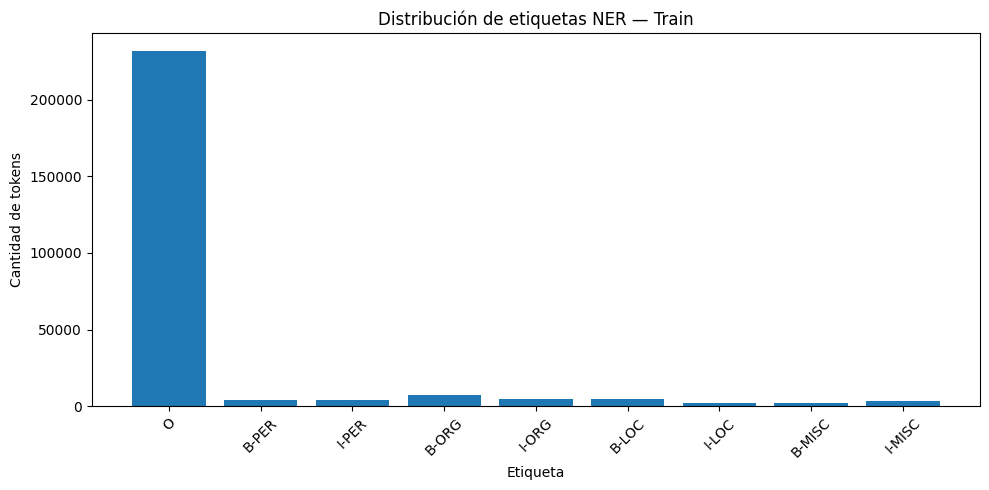

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

label_names = dataset_ner["train"].features["ner_tags"].feature.names #etiquetas NER originales
conteos = {} # Contar etiquetas por particio

for split in ["train", "validation"]:
    conteo = Counter(
        etiqueta
        for ejemplo in dataset_ner[split]
        for etiqueta in ejemplo["ner_tags"]
    )
    conteos[split] = conteo

distribucion_ner = pd.DataFrame({
    "Etiqueta": label_names,
    "Train": [
        conteos["train"][i]
        for i in range(len(label_names))
    ],
    "Validation": [
        conteos["validation"][i]
        for i in range(len(label_names))
    ]
})

distribucion_ner["Train (%)"] = (distribucion_ner["Train"] / distribucion_ner["Train"].sum() * 100).round(2)
display(distribucion_ner)
plt.figure(figsize=(10, 5))
plt.bar(distribucion_ner["Etiqueta"], distribucion_ner["Train"])
plt.title("Distribución de etiquetas NER — Train")
plt.xlabel("Etiqueta")
plt.ylabel("Cantidad de tokens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

El conjunto de entrenamiento presenta un marcado desbalance: **el 87,61 % de los tokens pertenece a la clase `O`**, mientras que el 12,39 % restante corresponde a etiquetas de entidades nombradas, entre las etiquetas de entidades, `B-ORG` presenta la mayor frecuencia (7.390 tokens), mientras que `I-LOC` es la menos frecuente (1.891 tokens).

Este desbalance implica que la accuracy por token puede resultar engañosa, pues un modelo que favorezca sistemáticamente la etiqueta `O` podría alcanzar una exactitud elevada sin identificar correctamente las entidades.

Por esta razón, la evaluación priorizará precision, recall y F1-score a nivel de entidad completa, considerando tanto la categoría como los límites de cada entidad

ESTADISTICAS DE LONGITUD — TRAIN
Secuencias: 8,324
Media: 31.80
Mediana: 34
Percentil 90: 57
Percentil 95: 62
Percentil 99: 76
Máximo: 1238


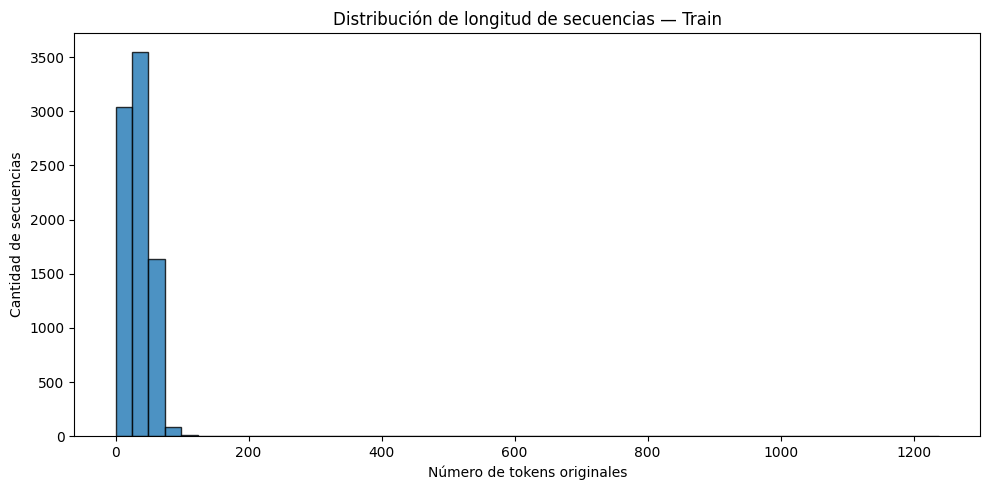

In [ ]:
longitudes = np.array([len(ejemplo["tokens"]) for ejemplo in dataset_ner["train"]])

print("ESTADISTICAS DE LONGITUD — TRAIN")
print(f"Secuencias: {len(longitudes):,}")
print(f"Media: {longitudes.mean():.2f}")
print(f"Mediana: {np.median(longitudes):.0f}")
print(f"Percentil 90: {np.percentile(longitudes, 90):.0f}")
print(f"Percentil 95: {np.percentile(longitudes, 95):.0f}")
print(f"Percentil 99: {np.percentile(longitudes, 99):.0f}")
print(f"Máximo: {longitudes.max()}")

plt.figure(figsize=(10, 5))
plt.hist(longitudes, bins=50, edgecolor="black", alpha=0.8)
plt.title("Distribución de longitud de secuencias — Train")
plt.xlabel("Número de tokens originales")
plt.ylabel("Cantidad de secuencias")
plt.tight_layout()
plt.show()

Las 8.324 secuencias de entrenamiento presentan una longitud media de 31,80 tokens originales y una mediana de 34. Los percentiles 95 y 99 corresponden a 62 y 76 tokens, respectivamente, la distribución muestra que la mayoría de las secuencias son relativamente cortas. Sin embargo, se identificó un valor extremo de **1.238 tokens**, considerablemente superior al resto.

Esta diferencia puede afectar la elección de la longitud máxima de entrada del modelo. Además, los tokens originales del dataset no equivalen necesariamente a los subtokens generados por BETO, por tanto, la selección de `max_length` se realizará después de analizar las longitudes obtenidas mediante el tokenizador del modelo, considerando el riesgo de truncar entidades.

In [ ]:
#mostrar tres secuencias anotadas
for indice in [0, 1, 2]:
    ejemplo = dataset_ner["train"][indice]

    print(f"\nSECUENCIA {indice}")
    print("Texto:", " ".join(ejemplo["tokens"]))
    tabla = pd.DataFrame({
        "Token": ejemplo["tokens"],
        "Etiqueta NER": [
            label_names[tag]
            for tag in ejemplo["ner_tags"]
        ]
    })

    display(tabla)


SECUENCIA 0
Texto: Melbourne ( Australia ) , 25 may ( EFE ) .


,Token,Etiqueta NER
0,Melbourne,B-LOC
1,(,O
2,Australia,B-LOC
3,),O
4,",",O
5,25,O
6,may,O
7,(,O
8,EFE,B-ORG
9,),O



SECUENCIA 1
Texto: -


,Token,Etiqueta NER
0,-,O



SECUENCIA 2
Texto: El Abogado General del Estado , Daryl Williams , subrayó hoy la necesidad de tomar medidas para proteger al sistema judicial australiano frente a una página de internet que imposibilita el cumplimiento de los principios básicos de la Ley .


,Token,Etiqueta NER
0,El,O
1,Abogado,B-PER
2,General,I-PER
3,del,I-PER
4,Estado,I-PER
5,",",O
6,Daryl,B-PER
7,Williams,I-PER
8,",",O
9,subrayó,O


La inspección de los primeros registros permite verificar cómo se representan las entidades mediante el esquema BIO, en la primera secuencia, `Melbourne` y `Australia` aparecen como entidades de ubicación independientes (`B-LOC`), mientras que `EFE` se identifica como una organización (`B-ORG`).

La segunda secuencia contiene únicamente un guion etiquetado como `O`, evidenciando la presencia de registros muy cortos.

La tercera secuencia muestra entidades formadas por múltiples tokens, como `Daryl Williams`, etiquetada mediante `B-PER` e `I-PER`. También se observa que `Abogado General del Estado` aparece etiquetado como persona, lo que refleja una convención particular de anotación del corpus.

Estos ejemplos confirman la necesidad de respetar las etiquetas originales y mantener su correspondencia con los tokens durante el preprocesamiento.

## Preprocesamiento

A partir de los hallazgos del EDA, se preparará una versión procesada de CoNLL-2002 para el fine-tuning de BETO.

Se excluirán las secuencias vacías y se normalizarán las transiciones BIO que no cumplen las reglas de IOB2, sin modificar las categorías semánticas originales.

Además, se crearán nuevas particiones de entrenamiento, validación y prueba, evitando que aparezcan simultáneamente en diferentes particiones.

**Limpieza y preparación del dataset**

Se excluyeron tres secuencias vacías y se normalizaron tres etiquetas BIO incompatibles con IOB2 mediante una regla estructural, sin modificar los tipos de entidad.

Se reunieron las particiones originales y se creó una nueva división utilizando `GroupShuffleSplit` con semilla 42. Los textos completos idénticos se mantuvieron dentro de una misma partición, conservando sus repeticiones y anotaciones.

La distribución obtenida fue:

| Partición | Registros | Porcentaje |
|---|---:|---:|
| Train | 7.200 | 61,25 % |
| Validation | 3.028 | 25,76 % |
| Test | 1.527 | 12,99 % |
| **Total** | **11.755** | **100 %** |

Se verificó que no existen textos completos idénticos compartidos entre las tres particiones, según la normalización utilizada.

In [ ]:
%pip install -q datasets
%pip install -q transformers
%pip install -q accelerate
%pip install -q seqeval
import sys
import platform
import importlib.metadata as metadata
import torch
from seqeval.scheme import IOB2
import datasets
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from transformers import AutoTokenizer
import unicodedata
from pathlib import Path
import shutil
from transformers import AutoTokenizer
import numpy as np
import matplotlib.pyplot as plt
from transformers import DataCollatorForTokenClassification
from seqeval.metrics import precision_score, recall_score, f1_score
from seqeval.scheme import IOB2
from datasets import DatasetDict
from datasets import DatasetDict
from sklearn.model_selection import train_test_split
from transformers import DataCollatorWithPadding
import torch
from pathlib import Path
import gc
from itertools import product
from transformers import (AutoModelForSequenceClassification,AutoModelForTokenClassification, Trainer, TrainingArguments, set_seed)
from sklearn.metrics import accuracy_score, f1_score
from pathlib import Path
import transformers
from itertools import product
import numpy as np
import unicodedata
import re
from datasets import DatasetDict, concatenate_datasets
from sklearn.model_selection import GroupShuffleSplit
from transformers import (EarlyStoppingCallback)
from transformers.trainer_utils import get_last_checkpoint
from datasets import load_dataset

DATASET_NER_ID = "BramVanroy/conll2002"
dataset_ner = load_dataset(DATASET_NER_ID, "es")

print(dataset_ner)
print("\nCaracterísticas:")
print(dataset_ner["train"].features)
print("\nPrimer ejemplo:")
print(dataset_ner["train"][0])

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 8324
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1916
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags'],
        num_rows: 1518
    })
})

Características:
{'id': Value('string'), 'tokens': List(Value('string')), 'pos_tags': List(ClassLabel(names=['AO', 'AQ', 'CC', 'CS', 'DA', 'DE', 'DD', 'DI', 'DN', 'DP', 'DT', 'Faa', 'Fat', 'Fc', 'Fd', 'Fe', 'Fg', 'Fh', 'Fia', 'Fit', 'Fp', 'Fpa', 'Fpt', 'Fs', 'Ft', 'Fx', 'Fz', 'I', 'NC', 'NP', 'P0', 'PD', 'PI', 'PN', 'PP', 'PR', 'PT', 'PX', 'RG', 'RN', 'SP', 'VAI', 'VAM', 'VAN', 'VAP', 'VAS', 'VMG', 'VMI', 'VMM', 'VMN', 'VMP', 'VMS', 'VSG', 'VSI', 'VSM', 'VSN', 'VSP', 'VSS', 'Y', 'Z'])), 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']))}

Primer ejemplo:
{'id': '0', 'tokens

In [ ]:
SEED_NER = 42
nombres_ner = dataset_ner["train"].features["ner_tags"].feature.names
id_ner = {
    nombre: i for i, nombre in enumerate(nombres_ner)
}

# nrmalizar unicamente transiciones BIO incompatibles con el esquema IOB2
def normalizar_bio(ejemplo):
    etiquetas = ejemplo["ner_tags"].copy()

    for i, etiqueta_id in enumerate(etiquetas):
        actual = nombres_ner[etiqueta_id]

        if not actual.startswith("I-"):
            continue

        tipo = actual[2:]
        anterior = (nombres_ner[etiquetas[i - 1]] if i > 0 else "O")
        if anterior not in (f"B-{tipo}", f"I-{tipo}"):
            etiquetas[i] = id_ner[f"B-{tipo}"]

    return {"ner_tags": etiquetas}


# excluir secuencias vacias y reunir las particiones
particiones = []

for nombre, ds in dataset_ner.items():
    ds = ds.filter(lambda e: len(e["tokens"]) > 0)
    #coservar la procedencia de cada registro
    ds = ds.add_column("particion_original", [nombre] * len(ds))
    particiones.append(ds)

corpus_original = concatenate_datasets(particiones)
corpus = corpus_original.map(normalizar_bio)
correcciones = sum(sum(a != b for a, b in zip(original, corregida)) for original, corregida in zip(corpus_original["ner_tags"], corpus["ner_tags"]))

print("Etiquetas BIO normalizadas:", correcciones)


#aagrupar por texto completo normalizado
def clave_grupo(ejemplo):
    texto = " ".join(ejemplo["tokens"])
    texto = unicodedata.normalize("NFC", texto)
    return re.sub(r"\s+", " ", texto).strip()


grupos = np.array([clave_grupo(e) for e in corpus], dtype=object)
indices = np.arange(len(corpus))

#separar Train (70 %) del resto (30 %).
separador = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED_NER)
idx_train, idx_resto = next(separador.split(indices, groups=grupos))

#  validation y test
separador_resto = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED_NER)
idx_val_rel, idx_test_rel = next(separador_resto.split(idx_resto, groups=grupos[idx_resto]))
idx_val = idx_resto[idx_val_rel]
idx_test = idx_resto[idx_test_rel]


# dataset definitivo
dataset_ner_preparado = DatasetDict({
    "train": corpus.select(idx_train.tolist()),
    "validation": corpus.select(idx_val.tolist()),
    "test": corpus.select(idx_test.tolist())
})


#  verificar que no existan textos compartidos
grupos_finales = {
    split: {clave_grupo(e) for e in ds}
    for split, ds in dataset_ner_preparado.items()
}

assert grupos_finales["train"].isdisjoint(grupos_finales["validation"])
assert grupos_finales["train"].isdisjoint(grupos_finales["test"])
assert grupos_finales["validation"].isdisjoint(grupos_finales["test"])
assert sum(len(ds) for ds in dataset_ner_preparado.values()) == len(corpus)

print("\nDATASET PREPARADO")
print(dataset_ner_preparado)
print("\nDISTRIBUCION")
for split, ds in dataset_ner_preparado.items():
    print(f"{split}: {len(ds):,} registros\n({100 * len(ds) / len(corpus):.2f} %)")

print("\nSin solapamientos textuales entre particiones")

Filter:   0%|          | 0/8324 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/8323 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1916 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/1915 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1518 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/1517 [00:00<?, ? examples/s]

Map:   0%|          | 0/11755 [00:00<?, ? examples/s]

Etiquetas BIO normalizadas: 3

DATASET PREPARADO
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags', 'particion_original'],
        num_rows: 7200
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags', 'particion_original'],
        num_rows: 3028
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'ner_tags', 'particion_original'],
        num_rows: 1527
    })
})

DISTRIBUCION
train: 7,200 registros
(61.25 %)
validation: 3,028 registros
(25.76 %)
test: 1,527 registros
(12.99 %)

Sin solapamientos textuales entre particiones


### Tokenizacion con BETO Cased

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3920 > 512). Running this sequence through the model will result in indexing errors


LONGITUDES CON BETO — TRAIN
Media: 44.83
Mediana: 45
P90: 69
P95: 76
P99: 95
Maximo: 3920
Secuencias que superan 128 subtokens: 0.39%
Secuencias que superan 256 subtokens: 0.08%
Secuencias que superan 512 subtokens: 0.03%


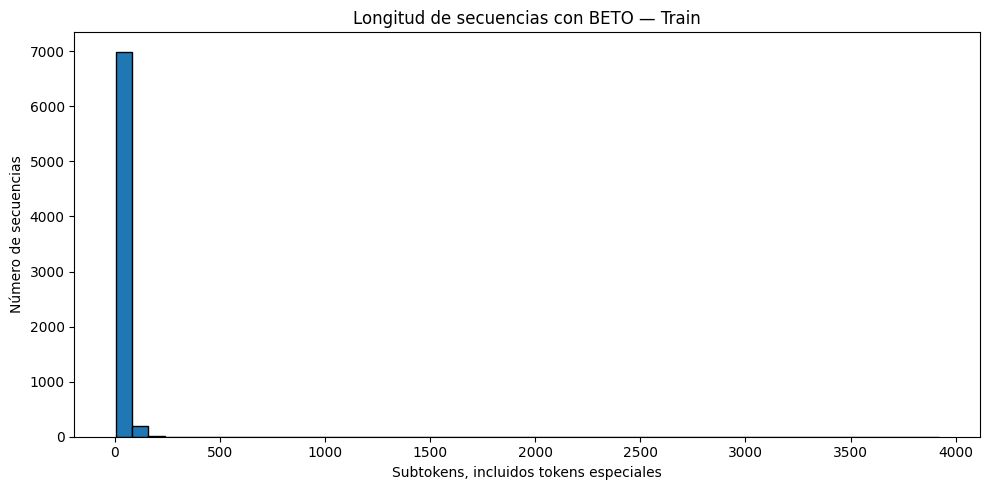

In [ ]:
MODEL_NER_ID = "dccuchile/bert-base-spanish-wwm-cased"
tokenizer_ner = AutoTokenizer.from_pretrained(MODEL_NER_ID, use_fast=True)

#tokenizar Train sin truncamiento para medir longitudes
longitudes_beto = []
train_ner = dataset_ner_preparado["train"]

for inicio in range(0, len(train_ner), 128):
    lote = train_ner[inicio:inicio + 128]["tokens"]
    codificacion = tokenizer_ner(lote, is_split_into_words=True, truncation=False, padding=False, return_length=True)
    longitudes_beto.extend(codificacion["length"])

longitudes_beto = np.array(longitudes_beto)
print("LONGITUDES CON BETO — TRAIN")
print(f"Media: {longitudes_beto.mean():.2f}")
print(f"Mediana: {np.median(longitudes_beto):.0f}")
print(f"P90: {np.percentile(longitudes_beto, 90):.0f}")
print(f"P95: {np.percentile(longitudes_beto, 95):.0f}")
print(f"P99: {np.percentile(longitudes_beto, 99):.0f}")
print(f"Maximo: {longitudes_beto.max()}")

for limite in [128, 256, 512]:
    porcentaje = np.mean(longitudes_beto > limite) * 100
    print(f"Secuencias que superan {limite} subtokens: {porcentaje:.2f}%")

plt.figure(figsize=(10, 5))
plt.hist(longitudes_beto, bins=50, edgecolor="black")
plt.title("Longitud de secuencias con BETO — Train")
plt.xlabel("Subtokens, incluidos tokens especiales")
plt.ylabel("Número de secuencias")
plt.tight_layout()
plt.show()

### Resultados del preprocesamiento y tokenización

Tras el nuevo particionado, el conjunto de entrenamiento contiene 7.200 secuencias, se aplicó el tokenizador de BETO cased para analizar las longitudes de entrada. Se obtuvo una longitud media de **44,83 subtokens**, una mediana de 45 y un percentil 99 de 95, solamente el 0,39 % de las secuencias supera los 128 subtokens, mientras que el 0,08 % supera los 256

Se identificó un valor extremo de 3.920 subtokens, superior al límite de 512 posiciones del modelo. Por ello, es necesario controlar la longitud máxima durante el entrenamiento

Se comparará el impacto de utilizar 128 y 256 subtokens, considerando la pérdida de anotaciones NER causada por el truncamiento

### Análisis del truncamiento

Se analiza cuánta información anotada se perdería al limitar las entradas a 128 o 256 subtokens, para ello, se calcula cuántos tokens originales pertenecientes a entidades nombradas quedarían completamente excluidos después del truncamiento.

Este análisis permite comparar el impacto de ambas longitudes. Sin embargo, no mide directamente entidades completas ni detecta todos los casos en los que una palabra queda parcialmente truncada.

In [ ]:
# perdida de anotaciones con longitudes 128 y 256
resultados_truncamiento = []
for limite in [128, 256]:
    entidades_totales = 0
    entidades_perdidas = 0
    secuencias_afectadas = 0
    for ejemplo in dataset_ner_preparado["train"]:
        encoding = tokenizer_ner(ejemplo["tokens"], is_split_into_words=True, truncation=True, max_length=limite)

        #indices de palabras originales que siguen presentes
        palabras_conservadas = {
            i for i in encoding.word_ids()
            if i is not None
        }

        etiquetas = ejemplo["ner_tags"]
        entidades_totales += sum(tag != 0 for tag in etiquetas) #contar tokens etiquetados como parte de una entidad
        perdidas = sum(tag != 0 and i not in palabras_conservadas for i, tag in enumerate(etiquetas))
        entidades_perdidas += perdidas
        secuencias_afectadas += (perdidas > 0)

    resultados_truncamiento.append({
        "Max length": limite,
        "Tokens de entidad perdidos": entidades_perdidas,
        "Tokens de entidad totales": entidades_totales,
        "Pérdida (%)": round(100 * entidades_perdidas / entidades_totales, 4),
        "Secuencias con entidades afectadas":secuencias_afectadas
    })

display(pd.DataFrame(resultados_truncamiento))

,Max length,Tokens de entidad perdidos,Tokens de entidad totales,Pérdida (%),Secuencias con entidades afectadas
0,128,451,32838,1.3734,26
1,256,235,32838,0.7156,6


Se compararon dos longitudes máximas de entrada: 128 y 256 subtokens.

Con 128 subtokens se perderían 451 tokens originales pertenecientes a entidades (1,37 %), afectando a 26 secuencias. Al aumentar a 256, la pérdida disminuye a 235 tokens (0,72 %), distribuidos en seis secuencias, se seleccionó MAX_LENGTH_NER = 256 como compromiso entre conservar información relevante y controlar el costo computacional. Se utilizará padding dinámico para ajustar la longitud de cada lote.

Aunque esta configuración reduce la pérdida de información, no elimina completamente el truncamiento de las secuencias excepcionalmente largas.

In [ ]:
MAX_LENGTH_NER = 256
label_names_ner = dataset_ner_preparado["train"].features["ner_tags"].feature.names

def tokenizar_y_alinear_ner(batch):
    codificacion = tokenizer_ner(batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH_NER, padding=False)
    etiquetas_alineadas = []
    for i, etiquetas_originales in enumerate(batch["ner_tags"]):
        word_ids = codificacion.word_ids(batch_index=i)
        etiquetas = []
        palabra_anterior = None

        for palabra_actual in word_ids:
            if palabra_actual is None:
                etiquetas.append(-100)

            elif palabra_actual != palabra_anterior:
                etiquetas.append(etiquetas_originales[palabra_actual])
            else:
                etiquetas.append(-100)

            palabra_anterior = palabra_actual
        etiquetas_alineadas.append(etiquetas)

    codificacion["labels"] = etiquetas_alineadas
    return codificacion

dataset_ner_tokenizado = dataset_ner_preparado.map(tokenizar_y_alinear_ner, batched=True, remove_columns=dataset_ner_preparado["train"].column_names, desc="Tokenizando y alineando etiquetas NER")
print(dataset_ner_tokenizado)

print("\nAlineaciOn y longitudes verificadas")


Tokenizando y alineando etiquetas NER:   0%|          | 0/7200 [00:00<?, ? examples/s]

Tokenizando y alineando etiquetas NER:   0%|          | 0/3028 [00:00<?, ? examples/s]

Tokenizando y alineando etiquetas NER:   0%|          | 0/1527 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 7200
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3028
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 1527
    })
})

AlineaciOn y longitudes verificadas


### Preparar metricas NER

In [ ]:
import seqeval.metrics as ner_metrics
from seqeval.scheme import IOB2
from transformers import DataCollatorForTokenClassification
#padding diamico
data_collator_ner = DataCollatorForTokenClassification(tokenizer=tokenizer_ner,padding=True)

#mmetricas de reconocimiento de entidades
def compute_metrics_ner(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)
    etiquetas_reales = []
    etiquetas_predichas = []

    for pred_seq, label_seq in zip(predictions, labels):
        mascara = label_seq != -100
        etiquetas_reales.append([label_names_ner[int(tag)] for tag in label_seq[mascara]])
        etiquetas_predichas.append([label_names_ner[int(tag)] for tag in pred_seq[mascara]])

    return {
        "precision": ner_metrics.precision_score(etiquetas_reales, etiquetas_predichas, mode="strict", scheme=IOB2),
        "recall": ner_metrics.recall_score(etiquetas_reales, etiquetas_predichas, mode="strict", scheme=IOB2),
        "f1": ner_metrics.f1_score(etiquetas_reales, etiquetas_predichas, mode="strict", scheme=IOB2)
    }

# PRUEBA DE FUNCIONAMIENTO ANTES DEL ENTRENAMIENTO
#simular una entidad PER de dos tokens
o = label_names_ner.index("O")
b_per = label_names_ner.index("B-PER")
i_per = label_names_ner.index("I-PER")

labels_prueba = np.array([[-100, b_per, i_per, o, -100]])

logits_prueba = np.zeros((1, 5, len(label_names_ner)), dtype=np.float32)
for posicion, etiqueta in enumerate(labels_prueba[0]):
    if etiqueta != -100:
        logits_prueba[0, posicion, etiqueta] = 10.0

metricas_prueba = compute_metrics_ner((logits_prueba, labels_prueba))

assert np.isclose(metricas_prueba["precision"], 1.0)
assert np.isclose(metricas_prueba["recall"], 1.0)
assert np.isclose(metricas_prueba["f1"], 1.0)

print("Prueba de metricas NER superada.")
print(metricas_prueba)

Prueba de metricas NER superada.
{'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}


## Busqueda de Hiperparametros

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
NER_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/NER")
NER_EXPERIMENTOS = NER_DIR / "experimentos"
NER_EXPERIMENTOS.mkdir(parents=True, exist_ok=True)

print("Resultados en:", NER_EXPERIMENTOS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados en: /content/drive/MyDrive/Proyecto_02_NLP/NER/experimentos


In [ ]:
LEARNING_RATES_NER = [2e-5, 3e-5, 5e-5]
WEIGHT_DECAYS_NER = [0.0, 0.05]
EPOCHS_NER = 3
BATCH_SIZE_NER = 16
SEED_NER = 42
RESULTADOS_NER_PATH = NER_EXPERIMENTOS / "resultados_ner.csv"
id2label_ner = dict(enumerate(label_names_ner))
label2id_ner = {
    etiqueta: indice
    for indice, etiqueta in id2label_ner.items()
}

if RESULTADOS_NER_PATH.exists():
    resultados_ner = pd.read_csv(RESULTADOS_NER_PATH).to_dict("records")
else:
    resultados_ner = []

combinaciones = list(product(LEARNING_RATES_NER, WEIGHT_DECAYS_NER))
for numero, (lr, wd) in enumerate(combinaciones, start=1):
    run_id = f"lr_{lr:.0e}_wd_{wd:.2f}"

    registros_previos = [r for r in resultados_ner if r["run_id"] == run_id]

    if len(registros_previos) == EPOCHS_NER:
        print(f"Omitiendo experimento completado: {run_id}")
        continue

    print(f"\nEXPERIMENTO {numero}/{len(combinaciones)}")
    print(f"Learning rate: {lr} | Weight decay: {wd}")

    set_seed(SEED_NER)

    modelo_ner = AutoModelForTokenClassification.from_pretrained(MODEL_NER_ID, num_labels=len(label_names_ner), id2label=id2label_ner, label2id=label2id_ner)
    args_ner = TrainingArguments(output_dir=f"/content/ner_{run_id}", learning_rate=lr, weight_decay=wd, num_train_epochs=EPOCHS_NER, per_device_train_batch_size=BATCH_SIZE_NER, per_device_eval_batch_size=32, optim="adamw_torch", lr_scheduler_type="linear", warmup_steps=0.1, eval_strategy="epoch", logging_strategy="epoch", save_strategy="no", fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(), seed=SEED_NER, data_seed=SEED_NER, report_to="none")
    entrenador_ner = Trainer(model=modelo_ner, args=args_ner, train_dataset=dataset_ner_tokenizado["train"], eval_dataset=dataset_ner_tokenizado["validation"], processing_class=tokenizer_ner, data_collator=data_collator_ner, compute_metrics=compute_metrics_ner)
    entrenamiento_ner = entrenador_ner.train()
    nuevos_resultados = []

    for registro in entrenador_ner.state.log_history:
        if "eval_f1" not in registro:
            continue

        nuevos_resultados.append({
            "run_id": run_id,
            "learning_rate": lr,
            "weight_decay": wd,
            "epoca": int(round(registro["epoch"])),
            "val_loss": registro["eval_loss"],
            "precision": registro["eval_precision"],
            "recall": registro["eval_recall"],
            "f1": registro["eval_f1"],
            "tiempo_total_s":entrenamiento_ner.metrics["train_runtime"]
        })

    if len(nuevos_resultados) != EPOCHS_NER:
        raise RuntimeError(f"Evaluaciones incompletas para {run_id}")

    resultados_ner = [r for r in resultados_ner if r["run_id"] != run_id] + nuevos_resultados
    pd.DataFrame(resultados_ner).to_csv(RESULTADOS_NER_PATH, index=False)
    display(pd.DataFrame(nuevos_resultados))

    del entrenador_ner, modelo_ner, entrenamiento_ner
    gc.collect()
    torch.cuda.empty_cache()

resultados_ner_df = pd.DataFrame(resultados_ner)

mejores_ner = (resultados_ner_df.sort_values(["f1", "val_loss"], ascending=[False, True]).drop_duplicates("run_id").reset_index(drop=True))

print("\nMEJORES CONFIGURACIONES NER")
display(mejores_ner)

mejores_ner.to_csv(NER_EXPERIMENTOS / "mejores_configuraciones_ner.csv", index=False)


EXPERIMENTO 1/6
Learning rate: 2e-05 | Weight decay: 0.0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.270949,0.058183,0.871969,0.873791,0.872879
2,0.042931,0.052922,0.890666,0.887640,0.889151
3,0.026300,0.051192,0.898247,0.897309,0.897778


,run_id,learning_rate,weight_decay,epoca,val_loss,precision,recall,f1,tiempo_total_s
0,lr_2e-05_wd_0.00,0.00002,0.0,1,0.058183,0.871969,0.873791,0.872879,572.9247
1,lr_2e-05_wd_0.00,0.00002,0.0,2,0.052922,0.890666,0.887640,0.889151,572.9247
2,lr_2e-05_wd_0.00,0.00002,0.0,3,0.051192,0.898247,0.897309,0.897778,572.9247



EXPERIMENTO 2/6
Learning rate: 2e-05 | Weight decay: 0.05


... (22 outputs left out)

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.204962,0.057795,0.868048,0.864646,0.866344
2,0.037097,0.051399,0.892697,0.884766,0.888714
3,0.018665,0.050254,0.901863,0.898093,0.899974


,run_id,learning_rate,weight_decay,epoca,val_loss,precision,recall,f1,tiempo_total_s
0,lr_5e-05_wd_0.05,0.00005,0.05,1,0.057795,0.868048,0.864646,0.866344,578.187
1,lr_5e-05_wd_0.05,0.00005,0.05,2,0.051399,0.892697,0.884766,0.888714,578.187
2,lr_5e-05_wd_0.05,0.00005,0.05,3,0.050254,0.901863,0.898093,0.899974,578.187



MEJORES CONFIGURACIONES NER


,run_id,learning_rate,weight_decay,epoca,val_loss,precision,recall,f1,tiempo_total_s
0,lr_3e-05_wd_0.00,0.00003,0.00,3,0.049331,0.903141,0.901489,0.902315,573.8345
1,lr_3e-05_wd_0.05,0.00003,0.05,3,0.049275,0.902382,0.900967,0.901674,579.6040
2,lr_5e-05_wd_0.00,0.00005,0.00,3,0.049815,0.902938,0.899399,0.901165,573.8906
3,lr_5e-05_wd_0.05,0.00005,0.05,3,0.050254,0.901863,0.898093,0.899974,578.1870
4,lr_2e-05_wd_0.00,0.00002,0.00,3,0.051192,0.898247,0.897309,0.897778,572.9247
5,lr_2e-05_wd_0.05,0.00002,0.05,3,0.051235,0.897309,0.897309,0.897309,578.9320


### Resultados de la búsqueda de hiperparámetros — NER

Se evaluaron seis combinaciones de learning rate y weight decay durante tres épocas cada una, utilizando BETO cased para reconocimiento de entidades nombradas.

Se emplearon 7.200 secuencias de entrenamiento y 3.028 de validación. La comparación se realizó mediante precisión, recall y F1 a nivel de entidad completa, utilizando evaluación estricta bajo el esquema IOB2.

### Comparación de experimentos

MEJORES RESULTADOS POR CONFIGURACION


,run_id,learning_rate,weight_decay,epoca,val_loss,precision,recall,f1,tiempo_total_s
0,lr_3e-05_wd_0.00,0.00003,0.00,3,0.049331,0.903141,0.901489,0.902315,573.8345
1,lr_3e-05_wd_0.05,0.00003,0.05,3,0.049275,0.902382,0.900967,0.901674,579.6040
2,lr_5e-05_wd_0.00,0.00005,0.00,3,0.049815,0.902938,0.899399,0.901165,573.8906
3,lr_5e-05_wd_0.05,0.00005,0.05,3,0.050254,0.901863,0.898093,0.899974,578.1870
4,lr_2e-05_wd_0.00,0.00002,0.00,3,0.051192,0.898247,0.897309,0.897778,572.9247
5,lr_2e-05_wd_0.05,0.00002,0.05,3,0.051235,0.897309,0.897309,0.897309,578.9320


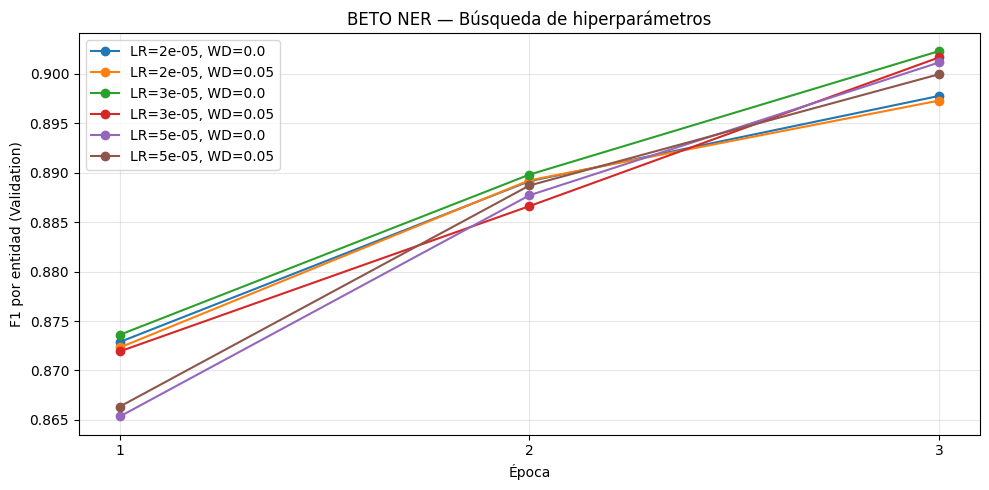

In [ ]:
resultados_ner_df = pd.read_csv(NER_EXPERIMENTOS / "resultados_ner.csv")

# mejor epoca de cada configuracion
mejores_ner = (resultados_ner_df.sort_values(["f1", "val_loss"],ascending=[False, True]).drop_duplicates("run_id").reset_index(drop=True))

print("MEJORES RESULTADOS POR CONFIGURACION")
display(mejores_ner)

#evolucion del F1 durante las tres epocas
plt.figure(figsize=(10, 5))

for (lr, wd), grupo in resultados_ner_df.groupby(["learning_rate", "weight_decay"]):
    grupo = grupo.sort_values("epoca")
    plt.plot(grupo["epoca"], grupo["f1"], marker="o", label=f"LR={lr:.0e}, WD={wd}" )

plt.title("BETO NER — Búsqueda de hiperparámetros")
plt.xlabel("Época")
plt.ylabel("F1 por entidad (Validation)")
plt.xticks([1, 2, 3])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretación de los resultados

La mejor configuración experimental fue **learning rate = 3e-5 y weight decay = 0,0**, alcanzando un F1 de **0,9023**, precisión de 0,9031 y recall de 0,9015 en la tercera época

Las seis configuraciones mejoraron progresivamente su F1 durante las tres épocas evaluadas. Por tanto, no se observó todavía un estancamiento claro del rendimiento en validación

Las diferencias entre las mejores configuraciones fueron pequeñas, por lo que no es posible establecer una superioridad estadística con una única ejecución por combinación

Para el entrenamiento definitivo se utilizarán los hiperparámetros seleccionados, ampliando el número máximo de épocas e incorporando parada temprana y recuperación del mejor checkpoint según F1 de validación

**Conservar split en Drive**

In [ ]:
from pathlib import Path

NER_SPLIT_DIR = NER_DIR / "dataset_split_agrupado"
if not NER_SPLIT_DIR.exists():
    dataset_ner_preparado.save_to_disk(str(NER_SPLIT_DIR))
    print("Split guardado en Google Drive")
else:
    print("El split ya existe, no se sobrescribio")

print("Ruta:", NER_SPLIT_DIR)

Saving the dataset (0/1 shards):   0%|          | 0/7200 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3028 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1527 [00:00<?, ? examples/s]

Split guardado en Google Drive
Ruta: /content/drive/MyDrive/Proyecto_02_NLP/NER/dataset_split_agrupado


## Entrenamiento

In [ ]:
import torch
import pandas as pd
from transformers import AutoModelForTokenClassification, Trainer, TrainingArguments, EarlyStoppingCallback, set_seed
from transformers.trainer_utils import get_last_checkpoint

BEST_LR_NER = 3e-5
BEST_WD_NER = 0.0
MAX_EPOCHS_NER = 8
BATCH_SIZE_NER = 16
NER_CHECKPOINT_DIR = NER_DIR / "checkpoints"
NER_MODELO_FINAL = NER_DIR / "modelo_final"

if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU antes de entrenar")

if not NER_DIR.exists():
    raise RuntimeError("La carpeta NER no esta disponible en Drive")

NER_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
NER_EXPERIMENTOS.mkdir(parents=True, exist_ok=True)
if (NER_MODELO_FINAL / "config.json").exists():
    raise RuntimeError("Ya existe un modelo final guardado, revisalo antes de volver a entrenar")

set_seed(SEED_NER)
id2label_ner = dict(enumerate(label_names_ner))
label2id_ner = {nombre: idx for idx, nombre in id2label_ner.items()}
modelo_ner_final = AutoModelForTokenClassification.from_pretrained(MODEL_NER_ID, num_labels=len(label_names_ner), id2label=id2label_ner, label2id=label2id_ner)

args_ner_final = TrainingArguments(output_dir=str(NER_CHECKPOINT_DIR), learning_rate=BEST_LR_NER, weight_decay=BEST_WD_NER,
                                   num_train_epochs=MAX_EPOCHS_NER, per_device_train_batch_size=BATCH_SIZE_NER,
                                   per_device_eval_batch_size=32, optim="adamw_torch", lr_scheduler_type="linear",
                                   warmup_steps=0.1, eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
                                   save_total_limit=2, load_best_model_at_end=True, metric_for_best_model="f1",
                                   greater_is_better=True, fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(),
                                   seed=SEED_NER, data_seed=SEED_NER, report_to="none" )

trainer_ner_final = Trainer(model=modelo_ner_final, args=args_ner_final, train_dataset=dataset_ner_tokenizado["train"],
                            eval_dataset=dataset_ner_tokenizado["validation"], processing_class=tokenizer_ner,
                            data_collator=data_collator_ner, compute_metrics=compute_metrics_ner,
                            callbacks=[EarlyStoppingCallback(early_stopping_patience=2, early_stopping_threshold=0.001)] )

ultimo_checkpoint_ner = get_last_checkpoint(str(NER_CHECKPOINT_DIR))
print("Reanudando desde:", ultimo_checkpoint_ner if ultimo_checkpoint_ner else "inicio")
resultado_ner_final = trainer_ner_final.train(resume_from_checkpoint=ultimo_checkpoint_ner)

# guardar el mejor modelo y el historial de entrenamiento
trainer_ner_final.save_model(str(NER_MODELO_FINAL))
tokenizer_ner.save_pretrained(str(NER_MODELO_FINAL))
pd.DataFrame(trainer_ner_final.state.log_history).to_csv(NER_EXPERIMENTOS / "historial_final_ner.csv", index=False)
print("\nEntrenamiento NER finalizado")
print("Mejor checkpoint:", trainer_ner_final.state.best_model_checkpoint)
print("Mejor F1:", trainer_ner_final.state.best_metric)
print("Modelo guardado en:", NER_MODELO_FINAL)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Reanudando desde: inicio


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.330551,0.062692,0.863885,0.865691,0.864787
2,0.047048,0.054805,0.872557,0.874837,0.873695
3,0.027074,0.049560,0.895176,0.897047,0.896111
4,0.016355,0.058770,0.905789,0.899399,0.902583
5,0.010361,0.060636,0.895452,0.895218,0.895335
6,0.007664,0.063097,0.903083,0.903319,0.903201


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Entrenamiento NER finalizado
Mejor checkpoint: /content/drive/MyDrive/Proyecto_02_NLP/NER/checkpoints/checkpoint-2700
Mejor F1: 0.9032005225342913
Modelo guardado en: /content/drive/MyDrive/Proyecto_02_NLP/NER/modelo_final


In [ ]:
# Liberar la GPU despues de guardar el modelo final
from google.colab import runtime

assert (NER_MODELO_FINAL / "config.json").is_file()
assert any((NER_MODELO_FINAL / nombre).is_file() for nombre in ["model.safetensors", "pytorch_model.bin"])
assert (NER_EXPERIMENTOS / "historial_final_ner.csv").is_file()

print("Modelo e historial guardados en Drive")
print("Desconectando Colab")

runtime.unassign()

Modelo e historial guardados en Drive
Desconectando Colab


## Evaluación sobre test

In [ ]:
%pip install -q datasets transformers accelerate seqeval

import torch
from pathlib import Path
from google.colab import drive
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification

drive.mount("/content/drive")
NER_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/NER")
NER_MODELO_FINAL = NER_DIR / "modelo_final"
NER_SPLIT_DIR = NER_DIR / "dataset_split_agrupado"
NER_EXPERIMENTOS = NER_DIR / "experimentos"

assert (NER_MODELO_FINAL / "config.json").is_file(), "No se encontro el modelo final"
assert NER_SPLIT_DIR.exists(), "No se encontro el split guardado"

dataset_ner_preparado = load_from_disk(str(NER_SPLIT_DIR))
tokenizer_ner = AutoTokenizer.from_pretrained(str(NER_MODELO_FINAL), use_fast=True)
modelo_ner_eval = AutoModelForTokenClassification.from_pretrained(str(NER_MODELO_FINAL))
label_names_ner = dataset_ner_preparado["test"].features["ner_tags"].feature.names
assert label_names_ner == [modelo_ner_eval.config.id2label[i] for i in range(len(label_names_ner))]

print("Modelo cargado desde Drive")
print("Secuencias Test:", len(dataset_ner_preparado["test"]))
print("Dispositivo:", "GPU" if torch.cuda.is_available() else "CPU")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


Loading weights:   0%|          | 0/199 [00:02<?, ?it/s]

Modelo cargado desde Drive
Secuencias Test: 1527
Dispositivo: GPU


**Evaluar resultados**

In [ ]:
import json
import numpy as np
import seqeval.metrics as ner_metrics
from seqeval.scheme import IOB2
from sklearn.metrics import accuracy_score
from transformers import Trainer, TrainingArguments, DataCollatorForTokenClassification

MAX_LENGTH_NER = 256
def tokenizar_test_ner(batch):
    encoding = tokenizer_ner(batch["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH_NER)
    labels = []
    for i, etiquetas_originales in enumerate(batch["ner_tags"]):
        word_ids = encoding.word_ids(batch_index=i)
        anterior = None
        etiquetas = []

        for actual in word_ids:
            etiqueta = etiquetas_originales[actual] if actual is not None and actual != anterior else -100
            etiquetas.append(etiqueta)
            anterior = actual

        labels.append(etiquetas)

    encoding["labels"] = labels
    return encoding

dataset_test_ner = dataset_ner_preparado["test"].map(tokenizar_test_ner, batched=True, remove_columns=dataset_ner_preparado["test"].column_names)
args_eval_ner = TrainingArguments(output_dir="/content/ner_eval", per_device_eval_batch_size=32 if torch.cuda.is_available() else 8, report_to="none")
trainer_eval_ner = Trainer(model=modelo_ner_eval, args=args_eval_ner, processing_class=tokenizer_ner, data_collator=DataCollatorForTokenClassification(tokenizer_ner, padding=True))
resultado_test_ner = trainer_eval_ner.predict(dataset_test_ner)
logits = resultado_test_ner.predictions
if isinstance(logits, tuple):
    logits = logits[0]

predicciones = np.argmax(logits, axis=-1)
etiquetas_reales, etiquetas_predichas = [], []
for pred, real in zip(predicciones, resultado_test_ner.label_ids):
    mascara = real != -100
    etiquetas_reales.append([label_names_ner[int(i)] for i in real[mascara]])
    etiquetas_predichas.append([label_names_ner[int(i)] for i in pred[mascara]])

y_true = [tag for secuencia in etiquetas_reales for tag in secuencia]
y_pred = [tag for secuencia in etiquetas_predichas for tag in secuencia]
detalle_ner = ner_metrics.classification_report(etiquetas_reales, etiquetas_predichas, mode="strict", scheme=IOB2, output_dict=True, zero_division=0)
reporte_ner = ner_metrics.classification_report(etiquetas_reales, etiquetas_predichas, mode="strict", scheme=IOB2, digits=4, zero_division=0)

metricas_test_ner = {
    "precision": float(detalle_ner["micro avg"]["precision"]),
    "recall": float(detalle_ner["micro avg"]["recall"]),
    "f1": float(detalle_ner["micro avg"]["f1-score"]),
    "f1_macro": float(detalle_ner["macro avg"]["f1-score"]),
    "f1_weighted": float(detalle_ner["weighted avg"]["f1-score"]),
    "accuracy_token": float(accuracy_score(y_true, y_pred)),
    "loss": float(resultado_test_ner.metrics["test_loss"]),
    "secuencias_test": len(etiquetas_reales),
    "tokens_evaluados": len(y_true),
    "secuencias_exactas": sum(real == pred for real, pred in zip(etiquetas_reales, etiquetas_predichas))
}

NER_EXPERIMENTOS.mkdir(parents=True, exist_ok=True)

with open(NER_EXPERIMENTOS / "metricas_test_ner.json", "w", encoding="utf-8") as f:
    json.dump(metricas_test_ner, f, indent=2)

(NER_EXPERIMENTOS / "reporte_test_ner.txt").write_text(reporte_ner, encoding="utf-8")
print("METRICAS FINALES NER")
for nombre, valor in metricas_test_ner.items():
    print(f"{nombre}: {valor}")

print("\nREPORTE POR ENTIDAD")
print(reporte_ner)
print("\nResultados guardados en Drive")

Map:   0%|          | 0/1527 [00:00<?, ? examples/s]

METRICAS FINALES NER
precision: 0.8956769350245923
recall: 0.8975356679636836
f1: 0.8966053381705106
f1_macro: 0.8749674588545967
f1_weighted: 0.8966176835554186
accuracy_token: 0.9855026905083304
loss: 0.06450189650058746
secuencias_test: 1527
tokens_evaluados: 54079
secuencias_exactas: 1213

REPORTE POR ENTIDAD
              precision    recall  f1-score   support

         LOC     0.8765    0.8912    0.8838       956
        MISC     0.7434    0.7417    0.7425       453
         ORG     0.9052    0.9008    0.9030      1462
         PER     0.9705    0.9705    0.9705       984

   micro avg     0.8957    0.8975    0.8966      3855
   macro avg     0.8739    0.8761    0.8750      3855
weighted avg     0.8957    0.8975    0.8966      3855


Resultados guardados en Drive


### Análisis de resultados

Se evaluó el modelo BETO cased sobre 1.527 secuencias de Test, obteniendo una precisión de 0,8957, un recall de 0,8975 y un F1 de 0,8966 a nivel de entidad completa.

A continuación, se analiza el desempeño por categoría, la cantidad de entidades evaluadas y los principales errores de predicción

METRICAS POR ENTIDAD COMPLETA


,Categoria,Precision,Recall,F1,Entidades
0,PER,0.9705,0.9705,0.9705,984
1,ORG,0.9052,0.9008,0.9030,1462
2,LOC,0.8765,0.8912,0.8838,956
3,MISC,0.7434,0.7417,0.7425,453



METRICAS POR TOKEN BIO


,Etiqueta,Precision,Recall,F1,Tokens
0,O,0.9966,0.9971,0.9968,47172
1,B-PER,0.9756,0.9756,0.9756,984
2,I-PER,0.9803,0.9803,0.9803,864
3,B-ORG,0.9230,0.9186,0.9208,1462
4,I-ORG,0.8838,0.8955,0.8896,1053
5,B-LOC,0.8868,0.9017,0.8942,956
6,I-LOC,0.8428,0.8405,0.8417,370
7,B-MISC,0.8142,0.8124,0.8133,453
8,I-MISC,0.8705,0.8170,0.8429,765


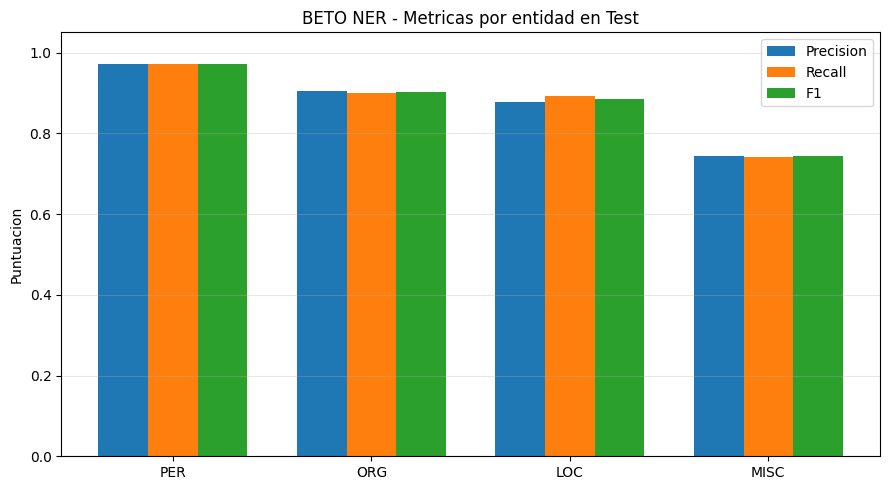

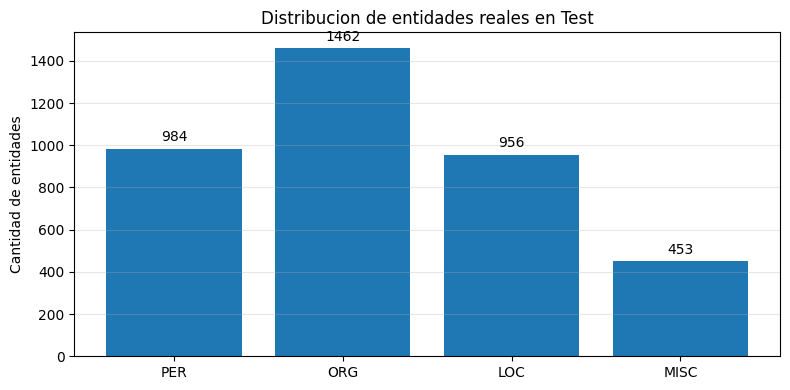

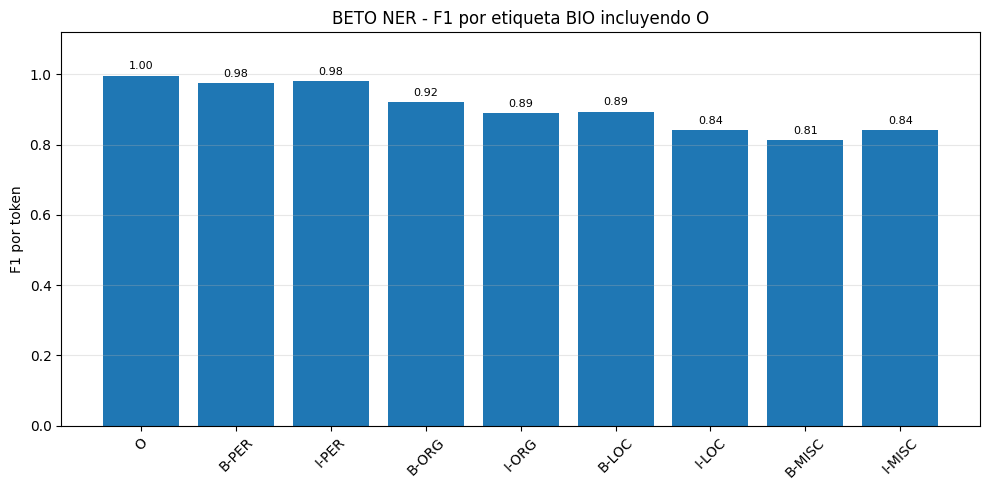

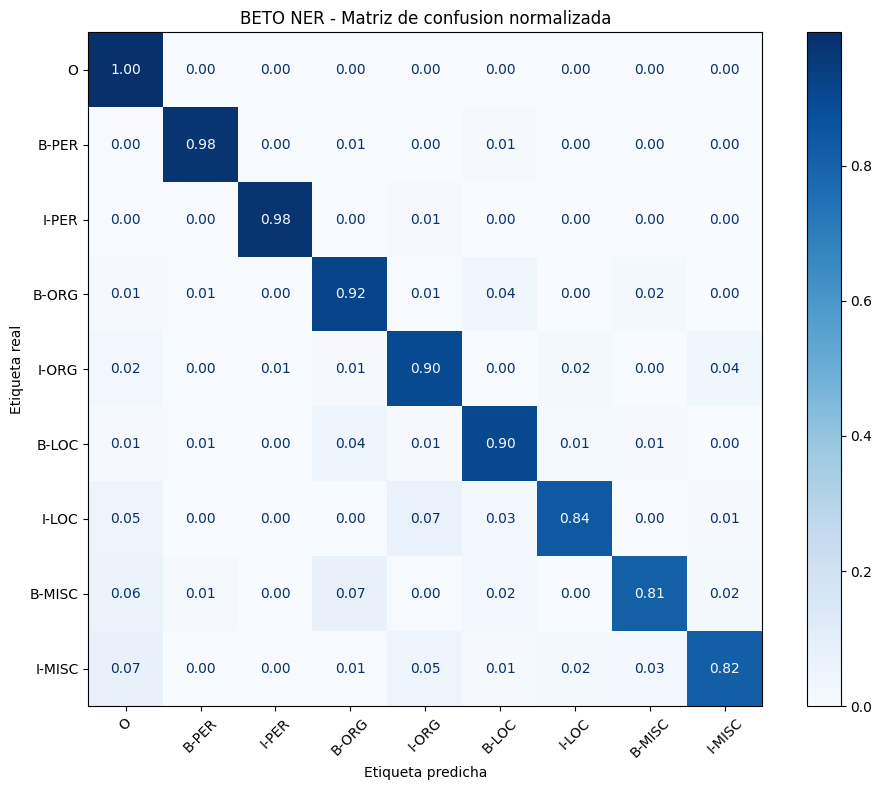

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report as reporte_tokens
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

categorias = ["PER", "ORG", "LOC", "MISC"]
etiquetas_bio = list(label_names_ner)

# Metricas sobre entidades completas
tabla_metricas_ner = pd.DataFrame([
    {"Categoria": c, "Precision": detalle_ner[c]["precision"], "Recall": detalle_ner[c]["recall"],
     "F1": detalle_ner[c]["f1-score"], "Entidades": int(detalle_ner[c]["support"])}
    for c in categorias
])

# Metricas por token incluyendo O
detalle_tokens = reporte_tokens(y_true, y_pred, labels=etiquetas_bio, output_dict=True, zero_division=0)

tabla_etiquetas_bio = pd.DataFrame([
    {"Etiqueta": tag, "Precision": detalle_tokens[tag]["precision"], "Recall": detalle_tokens[tag]["recall"],
     "F1": detalle_tokens[tag]["f1-score"], "Tokens": int(detalle_tokens[tag]["support"])}
    for tag in etiquetas_bio
])

print("METRICAS POR ENTIDAD COMPLETA")
display(tabla_metricas_ner.round(4))

print("\nMETRICAS POR TOKEN BIO")
display(tabla_etiquetas_bio.round(4))

tabla_metricas_ner.to_csv(NER_EXPERIMENTOS / "metricas_por_categoria_ner.csv", index=False)
tabla_etiquetas_bio.to_csv(NER_EXPERIMENTOS / "metricas_por_etiqueta_bio_ner.csv", index=False)

# Precision, recall y F1 por entidad
x = np.arange(len(categorias))
ancho = 0.25
fig, ax = plt.subplots(figsize=(9, 5))

for desplazamiento, metrica in zip([-1, 0, 1], ["Precision", "Recall", "F1"]):
    ax.bar(x + desplazamiento * ancho, tabla_metricas_ner[metrica], ancho, label=metrica)

ax.set_xticks(x, categorias)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Puntuacion")
ax.set_title("BETO NER - Metricas por entidad en Test")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(NER_EXPERIMENTOS / "metricas_por_categoria_ner.png", dpi=160)
plt.show()

# Distribucion de entidades reales
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(tabla_metricas_ner["Categoria"], tabla_metricas_ner["Entidades"])
ax.bar_label(barras, padding=3)
ax.set_ylabel("Cantidad de entidades")
ax.set_title("Distribucion de entidades reales en Test")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(NER_EXPERIMENTOS / "distribucion_entidades_test_ner.png", dpi=160)
plt.show()

# F1 de las nueve etiquetas BIO
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(tabla_etiquetas_bio["Etiqueta"], tabla_etiquetas_bio["F1"])
ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=8)
ax.set_ylim(0, 1.12)
ax.set_ylabel("F1 por token")
ax.set_title("BETO NER - F1 por etiqueta BIO incluyendo O")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(NER_EXPERIMENTOS / "f1_etiquetas_bio_ner.png", dpi=160)
plt.show()

# Matriz de confusion de las nueve etiquetas
matriz_ner = confusion_matrix(y_true, y_pred, labels=etiquetas_bio)
matriz_ner_norm = confusion_matrix(y_true, y_pred, labels=etiquetas_bio, normalize="true")

pd.DataFrame(matriz_ner, index=etiquetas_bio, columns=etiquetas_bio).to_csv(NER_EXPERIMENTOS / "matriz_confusion_ner.csv")
pd.DataFrame(matriz_ner_norm, index=etiquetas_bio, columns=etiquetas_bio).to_csv(NER_EXPERIMENTOS / "matriz_confusion_ner_normalizada.csv")

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_ner_norm, display_labels=etiquetas_bio)
disp.plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("BETO NER - Matriz de confusion normalizada")
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta real")
fig.tight_layout()
fig.savefig(NER_EXPERIMENTOS / "matriz_confusion_ner.png", dpi=160)
plt.show()

**Analisis de errores**

In [ ]:
import json
from seqeval.scheme import Entities, IOB2

errores_ner = []
errores_entidades_ner = []
tp_entidades = fp_entidades = fn_entidades = 0
entidades_adicionales = 0
spans_reales = Entities(etiquetas_reales, IOB2).entities
spans_predichos = Entities(etiquetas_predichas, IOB2).entities

with open(NER_EXPERIMENTOS / "predicciones_test_ner.jsonl", "w", encoding="utf-8") as archivo:
    for i, (reales, predichas) in enumerate(zip(etiquetas_reales, etiquetas_predichas)):
        tokens = dataset_ner_preparado["test"][i]["tokens"]
        archivo.write(json.dumps({"secuencia": i, "tokens": tokens, "real": reales, "predicha": predichas}, ensure_ascii=False) + "\n")

        gold, pred = set(spans_reales[i]), set(spans_predichos[i])
        tp_entidades += len(gold & pred)
        fp_entidades += len(pred - gold)
        fn_entidades += len(gold - pred)

        entidades_adicionales += sum(
            not any(p.start < g.end and g.start < p.end for g in gold)
            for p in pred - gold
        )

        if reales == predichas:
            continue

        encoding = tokenizer_ner(tokens, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH_NER)
        labels = dataset_test_ner[i]["labels"]
        word_ids = [wid for wid, tag in zip(encoding.word_ids(), labels) if tag != -100]

        assert len(word_ids) == len(reales) == len(predichas)

        # Errores por token original
        for j, (real, predicha) in enumerate(zip(reales, predichas)):
            if real == predicha:
                continue

            inicio, fin = max(0, j - 4), min(len(reales), j + 5)
            contexto = " ".join(tokens[word_ids[k]] for k in range(inicio, fin))
            errores_ner.append({
                "Secuencia": i, "Palabra": tokens[word_ids[j]], "Etiqueta real": real,
                "Prediccion": predicha, "Contexto": contexto
            })

        # Entidades reales que no fueron reconocidas correctamente
        for entidad in gold - pred:
            mismo_span = [p for p in pred if p.start == entidad.start and p.end == entidad.end]
            solapadas = [p for p in pred if p.start < entidad.end and entidad.start < p.end]

            if mismo_span:
                tipo_error = "Tipo incorrecto"
            elif solapadas:
                tipo_error = "Limites o tipo incorrecto"
            else:
                tipo_error = "Entidad omitida"

            texto_entidad = " ".join(tokens[word_ids[k]] for k in range(entidad.start, entidad.end))
            contexto_inicio = max(0, entidad.start - 5)
            contexto_fin = min(len(word_ids), entidad.end + 5)
            contexto = " ".join(tokens[word_ids[k]] for k in range(contexto_inicio, contexto_fin))

            predicciones_relacionadas = [
                f"{p.tag}: {' '.join(tokens[word_ids[k]] for k in range(p.start, p.end))}"
                for p in solapadas
            ]

            errores_entidades_ner.append({
                "Secuencia": i, "Entidad real": texto_entidad, "Categoria real": entidad.tag,
                "Tipo de error": tipo_error, "Predicciones relacionadas": " | ".join(predicciones_relacionadas),
                "Contexto": contexto
            })

assert np.isclose(tp_entidades / (tp_entidades + fp_entidades), metricas_test_ner["precision"])
assert np.isclose(tp_entidades / (tp_entidades + fn_entidades), metricas_test_ner["recall"])

tabla_errores_ner = pd.DataFrame(errores_ner)
tabla_errores_entidades = pd.DataFrame(errores_entidades_ner)

tabla_errores_ner.to_csv(NER_EXPERIMENTOS / "errores_test_ner.csv", index=False)
tabla_errores_entidades.to_csv(NER_EXPERIMENTOS / "errores_entidades_test_ner.csv", index=False)

print("RESUMEN DE ERRORES")
print("Secuencias con diferencias:", len({e["Secuencia"] for e in errores_ner}))
print("Tokens con diferencias:", len(errores_ner))
print("Entidades correctas TP:", tp_entidades)
print("Falsos positivos FP:", fp_entidades)
print("Falsos negativos FN:", fn_entidades)
print("Entidades adicionales sin solapamiento:", entidades_adicionales)

print("\nERRORES RELACIONADOS CON O")
print("Entidad real predicha como O:", sum(e["Prediccion"] == "O" and e["Etiqueta real"] != "O" for e in errores_ner))
print("O predicho como entidad:", sum(e["Etiqueta real"] == "O" and e["Prediccion"] != "O" for e in errores_ner))

if not tabla_errores_ner.empty:
    print("\nCONFUSIONES MAS FRECUENTES POR TOKEN")
    confusiones_ner = tabla_errores_ner.groupby(
        ["Etiqueta real", "Prediccion"]
    ).size().reset_index(name="Cantidad").sort_values("Cantidad", ascending=False)
    display(confusiones_ner.head(15))

    print("\nEJEMPLOS DE ERRORES POR TOKEN")
    muestra = tabla_errores_ner.drop_duplicates("Secuencia")
    display(muestra.sample(n=min(12, len(muestra)), random_state=42))

if not tabla_errores_entidades.empty:
    print("\nTIPOS DE ERROR POR ENTIDAD REAL")
    tabla_tipos_error = tabla_errores_entidades.groupby(
        ["Categoria real", "Tipo de error"]
    ).size().unstack(fill_value=0)
    display(tabla_tipos_error)

    print("\nEJEMPLOS DE ENTIDADES INCORRECTAS")
    display(tabla_errores_entidades.sample(n=min(12, len(tabla_errores_entidades)), random_state=42))
    tabla_tipos_error.to_csv(NER_EXPERIMENTOS / "tipos_error_entidad_ner.csv")

print("\nAnalisis de errores guardado en Drive")

RESUMEN DE ERRORES
Secuencias con diferencias: 314
Tokens con diferencias: 784
Entidades correctas TP: 3460
Falsos positivos FP: 403
Falsos negativos FN: 395
Entidades adicionales sin solapamiento: 39

ERRORES RELACIONADOS CON O
Entidad real predicha como O: 162
O predicho como entidad: 136

CONFUSIONES MAS FRECUENTES POR TOKEN


,Etiqueta real,Prediccion,Cantidad
40,I-MISC,O,56
14,B-ORG,B-LOC,54
45,I-ORG,I-MISC,41
1,B-LOC,B-ORG,39
38,I-MISC,I-ORG,38
9,B-MISC,B-ORG,32
59,O,I-MISC,31
60,O,I-ORG,30
13,B-MISC,O,27
47,I-ORG,O,26



EJEMPLOS DE ERRORES POR TOKEN


,Secuencia,Palabra,Etiqueta real,Prediccion,Contexto
331,677,Ceuta,B-ORG,B-LOC,los defensas Caracol ( Ceuta ) y el francés
79,158,Alava,B-ORG,B-LOC,"El diputado general de Alava mostró su "" preoc..."
569,1118,Desayuno,B-MISC,O,Desayuno Cardiosaludable de la Fundación
142,301,de,O,I-MISC,"las poesías del Cancionero de García Lorca , """
640,1291,Barcelona,B-ORG,B-LOC,"dos primeros partidos en Barcelona , no dio op..."
527,1011,ANCIANA,O,B-ORG,DADA DE ALTA LA ANCIANA PRESUNTAMENTE AGREDIDA...
54,104,"""",O,B-MISC,"Manresa tendrá lugar una "" Conferencia.Web "" q..."
17,37,Lasa,B-PER,B-LOC,"por los asesinados de Lasa y Zabala , según"
614,1224,de,I-MISC,O,El departamento de Salud de Estados Unidos dif...
575,1128,edición,I-MISC,O,Junta inaugura la VI edición de la Feria de



TIPOS DE ERROR POR ENTIDAD REAL


Tipo de error,Entidad omitida,Limites o tipo incorrecto,Tipo incorrecto
Categoria real,,,
LOC,6,52,46
MISC,14,63,40
ORG,10,57,78
PER,3,12,14



EJEMPLOS DE ENTIDADES INCORRECTAS


,Secuencia,Entidad real,Categoria real,Tipo de error,Predicciones relacionadas,Contexto
78,314,Ligmamo,LOC,Tipo incorrecto,MISC: Ligmamo,CICLISMO. GIRO DE ITALIA Ligmamo - Sabbiadoro ...
371,1440,José María Aznar,PER,Limites o tipo incorrecto,ORG: Gobierno de José,que calificaba al Gobierno de José María Aznar...
248,958,Comunidad Autónoma,LOC,Entidad omitida,,de la entidad en esta Comunidad Autónoma que c...
55,229,TEDAX,ORG,Tipo incorrecto,MISC: TEDAX,Desactivación de Artefactos Explosivos ( TEDAX...
390,1496,Vallehermoso,LOC,Tipo incorrecto,ORG: Vallehermoso,"el 0,04 por ciento y Vallehermoso el 1,38 por ..."
223,902,CHI,ORG,Tipo incorrecto,LOC: CHI,) - Nicolás Massú ( CHI ) Double : composición se
42,167,Adega,ORG,Tipo incorrecto,PER: Adega,"la subvención al eucalipto , Adega dice que es..."
234,904,""" Punto 1.9 """,MISC,Limites o tipo incorrecto,MISC: Punto 1.9,"se integra en el proyecto "" Punto 1.9 "" con la..."
316,1240,La Cenicienta,MISC,Limites o tipo incorrecto,MISC: La Cenicienta ',"inaugurará con su ballet ' La Cenicienta ' , l..."
116,494,Nueva York,LOC,Limites o tipo incorrecto,MISC: Nueva,"la de los niños , Nueva York , Jesús , paisajes o"



Analisis de errores guardado en Drive


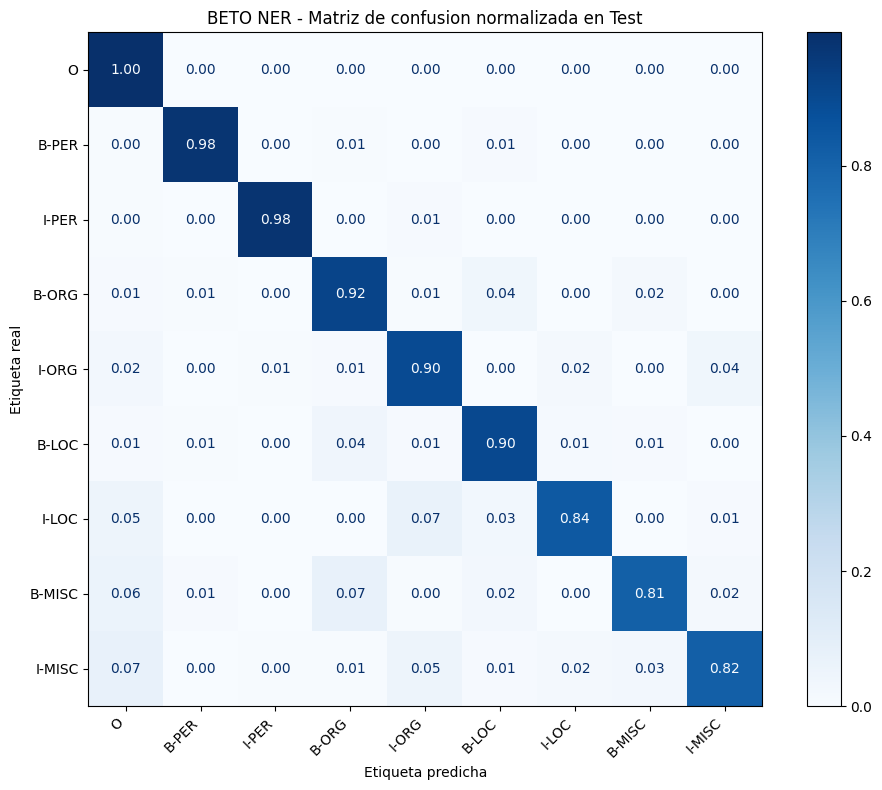

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#recuperar etiquetas reales y predichas por token
y_true = [etiqueta for secuencia in etiquetas_reales for etiqueta in secuencia]
y_pred = [etiqueta for secuencia in etiquetas_predichas for etiqueta in secuencia]

assert len(y_true) == len(y_pred)

matriz_ner = confusion_matrix(y_true, y_pred, labels=label_names_ner)
matriz_ner_norm = matriz_ner / np.maximum(matriz_ner.sum(axis=1, keepdims=True), 1)#normalizar por etiqueta real

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_ner_norm, display_labels=label_names_ner)
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=True)
ax.set_title("BETO NER - Matriz de confusion normalizada en Test")
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig.savefig(NER_EXPERIMENTOS / "matriz_confusion_ner.png", dpi=160)
plt.show()

### Conclusiones

El modelo BETO cased obtuvo un **F1 micro de 0,8966** y un **F1 macro de 0,8750** sobre el conjunto Test, evidenciando un buen desempeño general en el reconocimiento de entidades nombradas,m la categoría `PER` presentó el mejor rendimiento, con un F1 de 0,9705, seguida de `ORG` (0,9030) y `LOC` (0,8838). La categoría `MISC` obtuvo el resultado más bajo (0,7425), mostrando mayores dificultades para reconocer entidades heterogéneas.

En el análisis por token, BETO alcanzó una accuracy de 0,9855. Sin embargo, esta métrica debe interpretarse considerando el predominio de la etiqueta `O`, que representa aproximadamente el 87,23 % de los tokens evaluados. Por ello, el F1 estricto por entidad constituye el indicador principal del experimento

Se identificaron 395 falsos negativos a nivel de entidad: 178 asociados a categorías incorrectas, 184 a límites o categorías incorrectas y 33 a entidades completamente omitidas. Esto evidencia que una proporción importante de los errores ocurre al determinar la categoría o extensión exacta de una entidad, más que por su ausencia total en las predicciones.

Las matrices de confusión mostraron errores recurrentes entre organizaciones y lugares, así como dificultades para identificar componentes de entidades misceláneas. Estas observaciones resaltan la importancia del contexto lingüístico y de los límites de anotación en tareas NER.

Finalmente, el F1 obtenido en Test (0,8966) fue ligeramente inferior al de Validation (0,9032), sin evidenciar por sí solo un sobreajuste significativo. Los resultados deben interpretarse considerando la existencia de posibles inconsistencias de anotación, el truncamiento de secuencias largas y el uso de particiones personalizadas que impide la comparación directa con el benchmark oficial.

# 3. Sequence-to-Sequence — Traducción automática chino-español

## Descripción del problema y dataset

**Dominio y utilidad:** traducción automática de documentos del chino mandarín al español. Se trabaja con textos principalmente institucionales, donde es importante conservar el significado y utilizar terminología adecuada.

**Dataset:** UN Parallel Corpus, disponible en `Helsinki-NLP/un_pc`, configuración `es-zh`. Contiene textos paralelos en chino y español procedentes de documentos de Naciones Unidas.

Se seleccionó inicialmente una muestra de **175.992 pares de traducción**. Después de eliminar duplicados exactos y registros que excedían el límite de tokenización, se conservaron **159.474 pares**, divididos en Train, Validation y Test mediante agrupamiento para evitar coincidencias textuales entre particiones.

**Datos de entrada:** texto en chino (`chino`).

**Variable de salida:** traducción de referencia en español (`espanol`). A diferencia de los problemas anteriores, la salida es una secuencia de longitud variable.

**Tipo de problema:** *Sequence-to-Sequence*, específicamente traducción automática supervisada.

**Arquitectura:** M2M100-418M (`facebook/m2m100_418M`), Transformer multilingüe con arquitectura encoder-decoder. El encoder representa el texto de entrada y el decoder genera autoregresivamente la traducción en español.

**Estrategia de aprendizaje:** transfer learning mediante fine-tuning supervisado del modelo preentrenado. Para el entrenamiento definitivo se utilizaron 20.000 pares de Train y 1.000 de Validation.

**Evaluación:** SacreBLEU y chrF++, comparando el modelo original y el ajustado sobre los mismos 1.000 ejemplos seleccionados de Test, además de realizar una inspección cualitativa de las traducciones.

## Preparar entorno

In [ ]:
%pip install -q datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display
import unicodedata
from pathlib import Path
from transformers import AutoTokenizer
from sklearn.model_selection import GroupShuffleSplit
from datasets import DatasetDict
import json
import shutil
import pandas as pd
from itertools import product
from pathlib import Path
from transformers import M2M100ForConditionalGeneration, DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed

In [ ]:
SEED_MT = 42
DATASET_MT_ID = "Helsinki-NLP/un_pc"
CONFIG_MT = "es-zh"
MODEL_MT_ID = "facebook/m2m100_418M"
N_MUESTRA_MT = 175992 # un 1% aprox

np.random.seed(SEED_MT)

print("Entorno preparado para Sequence-to-Sequence")

## Cargar dataset

In [ ]:
stream_mt = load_dataset(DATASET_MT_ID, CONFIG_MT, split="train", streaming=True)
muestra_mt = list(stream_mt.shuffle(seed=SEED_MT, buffer_size=10000).take(N_MUESTRA_MT))
dataset_mt = Dataset.from_list(muestra_mt)
df_mt = pd.DataFrame(dataset_mt["translation"])
df_mt = df_mt.rename(columns={"zh": "chino", "es": "espanol"})

print("Pares cargados:", len(df_mt))
print("Columnas:", df_mt.columns.tolist())
display(df_mt.head(8))

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

Pares cargados: 175992
Columnas: ['espanol', 'chino']


,espanol,chino
0,18) Si bien toma nota de la información relati...,(18). 委员会注意到特别为被拘留者和遭受暴力侵害的儿童提供治疗和重新融入社会的服务的有关...
1,"El 6 de octubre de 2006, el abogado respondió ...",2006年10月6日，律师答复说，1997年1月17日，欧洲防止酷刑和不人道或有辱人格的待遇...
2,21) El Comité invita al Estado parte a que rat...,(21) 委员会请缔约国批准其尚未加入的联合国主要人权条约：《保护所有人免遭强迫失踪国际公约...
3,"Reunido el 9 de mayo de 2008,",于2008年5月9日举行会议，
4,El Estado parte cuestiona también la validez d...,缔约国还对据称由刚果民主共和国公安部签发的临时逮捕证和搜查证的有效性提出疑问，并指出，申诉人...
5,También dispone que se instituya al Subcomité ...,它设立了小组委员会，作为具有全球赦免的国际防范机制，并要求缔约国在国内一级设立、指定或保持一...
6,b) Adopte medidas eficaces para mejorar aún má...,采取有效措施，进一步改善包括监狱及警局短期拘留室在内的拘留设施的生活条件；和
7,"Entre otras cosas, la Comisión debería tener f...",这个委员会应有权调查严重侵犯人权的行为，对受害者给予赔偿，同时禁止对于实施酷刑者给予赦免。


## EDA

CALIDAD DEL DATASET
Pares: 175992
Chino vacio: 0
Espanol vacio: 0
Pares duplicados: 16262
Textos chinos repetidos: 19251
Textos espanoles repetidos: 19665

ESTADISTICAS DE LONGITUD


,zh_caracteres,es_palabras,es_caracteres
count,175992.00,175992.00,175992.00
mean,43.60,27.72,174.70
std,37.63,22.21,142.64
min,1.00,1.00,1.00
50%,37.00,24.00,152.00
90%,84.00,55.00,343.00
95%,104.00,67.00,420.00
99%,160.00,100.00,636.00
max,909.00,444.00,2893.00



EJEMPLOS ALEATORIOS


,chino,espanol
112052,巴林实现千年发展目标方面工作的一个重要支柱仍然是投资于具有实用性、切合需要而且高质量的现代教...,Un pilar primordial del enfoque de Bahrein con...
100242,175．基金秘书/首席执行干事为基金秘书处工作人员编制和组织机构进行的整个审查提交了说明和报告。,El Secretario y Director General presentó la n...
36485,为132名人员(51名军事人员、66名联合国警察和15名文职人员)开办了9期培训课程；向设在...,Mediante la organización de 9 sesiones de capa...
69711,1. 比值的演变,1. Evolución del margen
99589,对于捐助者和受援国核准的项目，将为每一捐助者单独设立信托基金；,Se establecen fondos fiduciarios separados par...
41125,递延负债 -- -- 信托基金详见如下所列(单位：千美元)：,A continuación se presenta información detalla...
23126,P-5,P-5
162880,11月17-21日,17 a 21 de noviembre


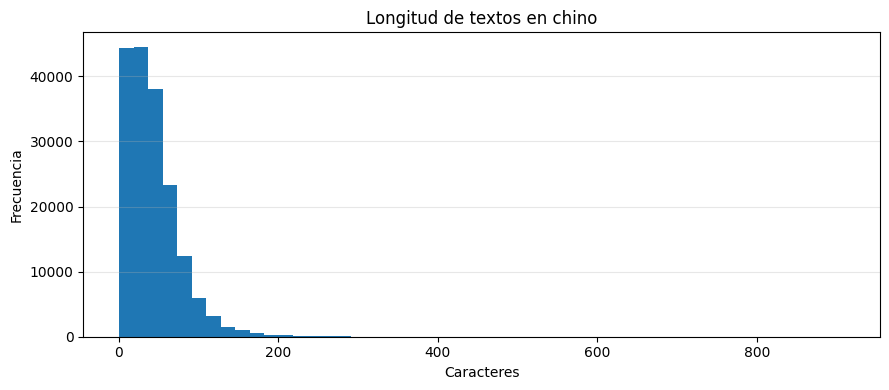

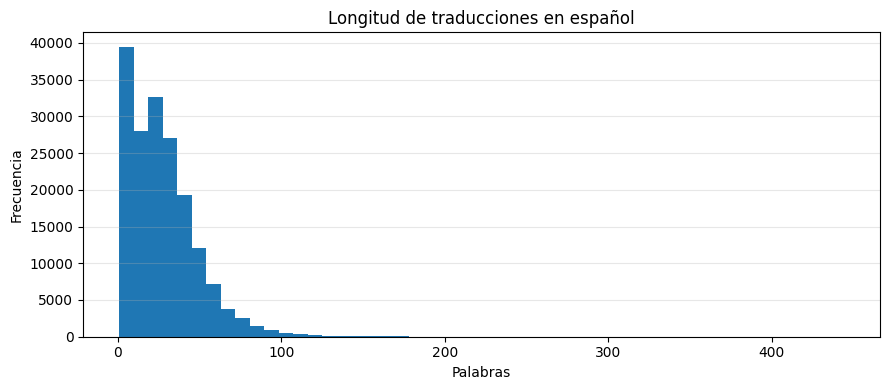

In [ ]:
df_mt["chino"] = df_mt["chino"].fillna("").astype(str)
df_mt["espanol"] = df_mt["espanol"].fillna("").astype(str)
df_mt["zh_caracteres"] = df_mt["chino"].str.len()
df_mt["es_palabras"] = df_mt["espanol"].str.split().str.len()
df_mt["es_caracteres"] = df_mt["espanol"].str.len()
print("CALIDAD DEL DATASET")
print("Pares:", len(df_mt))
print("Chino vacio:", df_mt["chino"].str.strip().eq("").sum())
print("Espanol vacio:", df_mt["espanol"].str.strip().eq("").sum())
print("Pares duplicados:", df_mt.duplicated(["chino", "espanol"]).sum())
print("Textos chinos repetidos:", df_mt.duplicated("chino").sum())
print("Textos espanoles repetidos:", df_mt.duplicated("espanol").sum())

print("\nESTADISTICAS DE LONGITUD")
display(df_mt[["zh_caracteres", "es_palabras", "es_caracteres"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

print("\nEJEMPLOS ALEATORIOS")
display(df_mt[["chino", "espanol"]].sample(n=min(8, len(df_mt)), random_state=SEED_MT))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df_mt["zh_caracteres"], bins=50)
ax.set(title="Longitud de textos en chino", xlabel="Caracteres", ylabel="Frecuencia")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df_mt["es_palabras"], bins=50)
ax.set(title="Longitud de traducciones en español", xlabel="Palabras", ylabel="Frecuencia")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Se analizaron 175.992 pares de traducción chino-español, sin encontrar textos vacíos. Se identificaron 16.262 pares duplicados exactos (9,24 %), la mediana de longitud fue de 37 caracteres para el chino y 24 palabras para el español. El percentil 99 alcanzó 160 caracteres y 100 palabras, respectivamente.

Las distribuciones presentan asimetría positiva y valores extremos. Además, los ejemplos muestran un predominio de textos institucionales y jurídicos, lo que podría limitar la generalización a otros dominios

## Analisis de calidad

Se examinarán los duplicados exactos, los textos con múltiples traducciones y los registros con características atípicas, el propósito es identificar posibles inconsistencias de alineación y problemas de calidad antes de definir los criterios de preprocesamiento, sin asumir que todas las repeticiones o diferencias constituyen errores.

In [ ]:
def normalizar_texto_mt(texto):
    return " ".join(unicodedata.normalize("NFC", texto).split())
pd.set_option("display.max_colwidth", None)
df_auditoria_mt = df_mt[["chino", "espanol"]].copy()
df_auditoria_mt["zh_key"] = df_auditoria_mt["chino"].map(normalizar_texto_mt)
df_auditoria_mt["es_key"] = df_auditoria_mt["espanol"].map(normalizar_texto_mt)
duplicados_mt = df_auditoria_mt.duplicated(["zh_key", "es_key"]).sum()

#cntidad de traducciones distintas para cada texto
traducciones_por_chino = df_auditoria_mt.groupby("zh_key")["es_key"].nunique()
traducciones_por_espanol = df_auditoria_mt.groupby("es_key")["zh_key"].nunique()
chino_multiple = traducciones_por_chino[traducciones_por_chino > 1]
espanol_multiple = traducciones_por_espanol[traducciones_por_espanol > 1]

print("ANALISIS DE DUPLICADOS")
print("Pares duplicados normalizados:", duplicados_mt)
print("Pares unicos:", len(df_auditoria_mt) - duplicados_mt)
print("Textos chinos con varias traducciones:", len(chino_multiple))
print("Textos espanoles con varias traducciones:", len(espanol_multiple))
print("Registros con chino de traduccion multiple:", df_auditoria_mt["zh_key"].isin(chino_multiple.index).sum())
print("Registros con espanol de traduccion multiple:", df_auditoria_mt["es_key"].isin(espanol_multiple.index).sum())

print("\nEJEMPLOS DE TEXTOS CHINOS CON DIFERENTES TRADUCCIONES")

for texto in chino_multiple.sort_values(ascending=False).head(5).index:
    ejemplos = df_auditoria_mt[df_auditoria_mt["zh_key"] == texto].drop_duplicates("es_key").head(3)
    print("\nChino:", texto[:200])
    display(exemplos[["espanol"]] if False else ejemplos[["espanol"]].assign(espanol=lambda x: x["espanol"].str.slice(0, 250)))

ANALISIS DE DUPLICADOS
Pares duplicados normalizados: 16262
Pares unicos: 159730
Textos chinos con varias traducciones: 2569
Textos espanoles con varias traducciones: 2175
Registros con chino de traduccion multiple: 10177
Registros con espanol de traduccion multiple: 12522

EJEMPLOS DE TEXTOS CHINOS CON DIFERENTES TRADUCCIONES

Chino: 欺诈和推定欺诈案件


,espanol
39315,Casos de fraude y de presunción de fraude
43890,Casos de fraude y de presunción de fraude Agradecimientos
51251,Casos de fraude o de presunción de fraude Agradecimientos



Chino: 其他


,espanol
17498,Otros
38913,Otros gastos
44621,Otros donantes



Chino: 联合国大会主席


,espanol
41999,Presidente de la Asamblea General de las Naciones Unidas
44295,Dirección de Gestión Presidente de la Junta de Auditores
45126,"Presidente de la Asamblea General Excelentísimo Señor,"



Chino: 3. 在审议该项目时，委员会面前有下列文件：


,espanol
3927,"Para continuar su examen del tema, la Comisión tuvo ante sí los siguientes documentos:"
68944,"Para su examen del tema, la Quinta Comisión tuvo ante sí los siguientes documentos:"
70476,"Para su examen del tema, la Comisión tuvo ante sí los siguientes documentos:"



Chino: 未执行


,espanol
18414,No aplicadas
39793,Sin aplicar
46132,No aplicada


## Casos atipicos y relacion entre longitudes

REGISTROS PARA REVISION
Sin caracteres chinos Han: 4916
Sin letras del alfabeto latino en espanol: 8
Textos muy cortos: 11215
Textos por encima del percentil 99: 2281

EJEMPLOS SIN CARACTERES HAN


,chino,espanol,zh_caracteres,es_palabras
58,CAT/C/GEO/CO/3/Add.1,CAT/C/GEO/CO/3/Add.1,20,1
110,"262/2005, Losizkaja","V. L., Nº 262/2005",19,4
212,"Tapia Páez, 39/1996","Tapia Páez, No. 39/1996",19,4
260,"Tharina, 226/2003","Tharina, No. 226/2003",17,3
265,CAT/C/LVA/CO/2,CAT/C/LVA/CO/2,14,1
485,"Halimi-Nedibi Quani, 8/1991","Caso Halimi-Nedibi Quani, Nº 8/1991",27,5
507,"Arana, 63/1997","Arana, Nº 63/1997",14,3
541,CAT/C/ISL/CO/3,CAT/C/ISL/CO/3,14,1



EJEMPLOS MUY CORTOS


,chino,espanol,zh_caracteres,es_palabras
174051,智利,Chile,2,1
107617,图七,Gráfico VII,2,2
54652,章次,Capítulo,2,1
49259,共计,Total,2,1
100795,合计,Total,2,1
86136,610(XXX),610 (XXX),8,2
67080,伊拉克,Iraq,3,1
94250,页次,Página,2,1



EJEMPLOS DE TEXTOS LARGOS


,chino,espanol,zh_caracteres,es_palabras
126248,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、中非共和国、乍得、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",909,266
165061,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、中非共和国、乍得、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",901,263
136058,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯、捷克共和,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",897,263
146345,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、佛得角、中非共和国、乍得、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",896,263
159577,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、乍得、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯、捷,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",894,258
134899,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、乍得、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯、捷,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",886,257
162527,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯、捷克共和,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",878,258
140829,阿富汗、阿尔巴尼亚、阿尔及利亚、安道尔、安哥拉、安提瓜和巴布达、阿根廷、亚美尼亚、澳大利亚、奥地利、阿塞拜疆、巴哈马、巴林、孟加拉国、巴巴多斯、白俄罗斯、比利时、伯利兹、贝宁、不丹、玻利维亚、波斯尼亚和黑塞哥维那、博茨瓦纳、巴西、文莱达鲁萨兰国、保加利亚、布基纳法索、布隆迪、柬埔寨、喀麦隆、加拿大、佛得角、智利、中国、哥伦比亚、科摩罗、刚果、哥斯达黎加、科特迪瓦、克罗地亚、古巴、塞浦路斯、捷克共和,"Afganistán, Albania, Argelia, Andorra, Angola, Antigua y Barbuda, Argentina, Armenia, Australia, Austria, Azerbaiyán, Bahamas, Bahrein, Bangladesh, Barbados, Belarús, Bélgica, Belice, Benin, Bhután, Bolivia, Bosnia y Herzegovina, Botswana, Brasil, Br",876,255


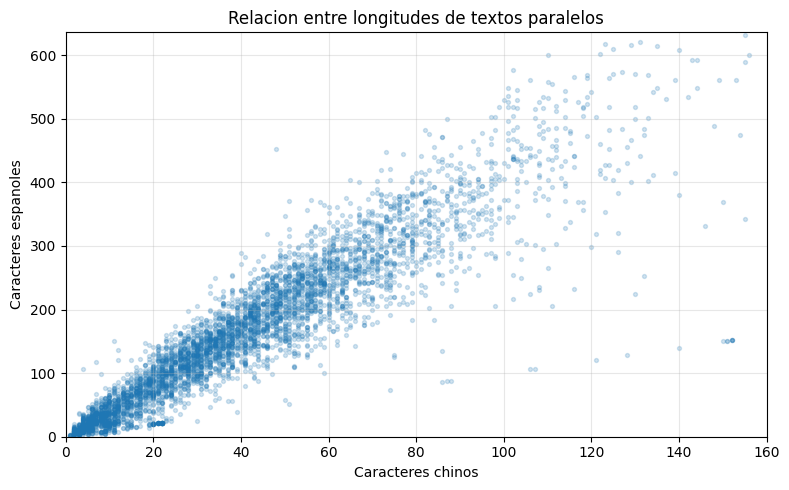

In [ ]:
#identificar registros que merecen revision
sin_han_mt = ~df_mt["chino"].str.contains(r"[\u3400-\u9fff]", regex=True)
sin_letras_es_mt = ~df_mt["espanol"].str.contains(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]", regex=True)
cortos_mt = (df_mt["zh_caracteres"] <= 3) | (df_mt["es_palabras"] <= 2)
largos_mt = (df_mt["zh_caracteres"] > df_mt["zh_caracteres"].quantile(0.99)) | (df_mt["es_palabras"] > df_mt["es_palabras"].quantile(0.99))

print("REGISTROS PARA REVISION")
print("Sin caracteres chinos Han:", sin_han_mt.sum())
print("Sin letras del alfabeto latino en espanol:", sin_letras_es_mt.sum())
print("Textos muy cortos:", cortos_mt.sum())
print("Textos por encima del percentil 99:", largos_mt.sum())

columnas_mt = ["chino", "espanol", "zh_caracteres", "es_palabras"]
pd.set_option("display.max_colwidth", None)
print("\nEJEMPLOS SIN CARACTERES HAN")
display(df_mt.loc[sin_han_mt, columnas_mt].head(8))

print("\nEJEMPLOS MUY CORTOS")
display(df_mt.loc[cortos_mt, columnas_mt].sample(n=min(8, cortos_mt.sum()), random_state=SEED_MT))

print("\nEJEMPLOS DE TEXTOS LARGOS")
ejemplos_largos_mt = df_mt.loc[largos_mt, columnas_mt].nlargest(8, "zh_caracteres").copy()
ejemplos_largos_mt["chino"] = ejemplos_largos_mt["chino"].str.slice(0, 200)
ejemplos_largos_mt["espanol"] = ejemplos_largos_mt["espanol"].str.slice(0, 250)
display(ejemplos_largos_mt)

# relacion entre caracteres chinos y espanoles
muestra_grafico_mt = df_mt.sample(n=min(5000, len(df_mt)), random_state=SEED_MT)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(muestra_grafico_mt["zh_caracteres"], muestra_grafico_mt["es_caracteres"], s=8, alpha=0.2)
ax.set_xlim(0, df_mt["zh_caracteres"].quantile(0.99))
ax.set_ylim(0, df_mt["es_caracteres"].quantile(0.99))
ax.set(title="Relacion entre longitudes de textos paralelos", xlabel="Caracteres chinos", ylabel="Caracteres espanoles")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se identificaron 16.262 pares duplicados exactos y múltiples correspondencias entre textos chinos y españoles., algunos casos representan variaciones legítimas de traducción, mientras que otros sugieren problemas de alineación documental, también se encontraron 4.916 registros sin caracteres Han, 11.215 textos muy cortos y 2.281 registros con longitudes superiores al percentil 99 en al menos uno de los idiomas.

El análisis de dispersión mostró una asociación positiva entre las longitudes de los textos paralelos, aunque algunos valores atípicos requieren revisión

Estos hallazgos justifican un preprocesamiento orientado a reducir redundancias y posibles errores de alineación, conservando los datos originales como referencia

### Decisiones a partir del EDA

Se conservará el corpus original y se preparará una versión de trabajo eliminando los pares exactamente duplicados y los registros vacíos. se mantendrán las traducciones alternativas y los textos cortos, ya que no constituyen necesariamente errores. Los casos sospechosos de desalineación se documentarán sin corregirlos automáticamente

Las longitudes máximas se definirán mediante el tokenizador de M2M100. Posteriormente se crearán particiones independientes, controlando la repetición de textos para reducir fugas de información.

## Preprocesamiento

### Preparar corpus
Se excluye pares vacíos y elimina duplicados exactos después de normalizar Unicode y espacios. No elimina traducciones alternativas ni aplica filtros arbitrarios de longitud.

In [ ]:
def normalizar_mt(texto):
    return " ".join(unicodedata.normalize("NFC", texto).split())

df_mt_preparado = df_mt[["chino", "espanol"]].copy()
df_mt_preparado["zh_key"] = df_mt_preparado["chino"].map(normalizar_mt)
df_mt_preparado["es_key"] = df_mt_preparado["espanol"].map(normalizar_mt)
vacios = (df_mt_preparado["zh_key"] == "") | (df_mt_preparado["es_key"] == "")
duplicados = df_mt_preparado.loc[~vacios].duplicated(["zh_key", "es_key"])
df_mt_preparado = df_mt_preparado.loc[~vacios].drop_duplicates(["zh_key", "es_key"]).reset_index(drop=True)

assert not df_mt_preparado.duplicated(["zh_key", "es_key"]).any()
assert not (df_mt_preparado[["zh_key", "es_key"]] == "").any().any()

print("Registros originales:", len(df_mt))
print("Registros vacios excluidos:", vacios.sum())
print("Pares duplicados excluidos:", duplicados.sum())
print("Pares preparados:", len(df_mt_preparado))

display(df_mt_preparado[["chino", "espanol"]].sample(5, random_state=SEED_MT))

Registros originales: 175992
Registros vacios excluidos: 0
Pares duplicados excluidos: 16262
Pares preparados: 159730


,chino,espanol
29755,(a) 撤消有争议的判决；,a) La revocación de la decisión impugnada;
48830,168. 审计委员会注意到，尽管申购者几乎总是返回供应商履约表现评价表，但该文件被归入有关的供应商信息档案存档，并未得到利用；供应商履约表现评价未能完成。,"La Junta observó que aunque los solicitantes casi siempre devolvían los formularios de calificación de la actuación de los proveedores, esos documentos se archivaban en el expediente de información sobre los proveedores y no se utilizaban; por tanto, no se completaba la calificación de la actuación de los proveedores."
38452,在发展、和平与安全方面为两性平等建立 能力和加强问责,"Fomento de la capacidad y mejoramiento de la rendición de cuentas sobre la igualdad entre los géneros en el desarrollo, la paz y la seguridad"
87116,37. 该区域所有国家在争取知识经济方面都取得了进展。,37. Todos los países de la región progresaron con miras al establecimiento de una economía basada en los conocimientos.
24679,3.35 hrs to 3.40 hrs,3.35 hrs to 3.40 hrs


### Identificar grupos para evitar fugas de información

In [ ]:
zh_ids, zh_unicos = pd.factorize(df_mt_preparado["zh_key"])
es_ids, es_unicos = pd.factorize(df_mt_preparado["es_key"])
n_zh = len(zh_unicos)
n_nodos = n_zh + len(es_unicos)
grafo_mt = csr_matrix((np.ones(len(df_mt_preparado), dtype=np.int8), (zh_ids, es_ids + n_zh)), shape=(n_nodos, n_nodos))
n_grupos, componentes = connected_components(grafo_mt, directed=False)
df_mt_preparado["grupo_mt"] = componentes[zh_ids]

assert df_mt_preparado.groupby("zh_key")["grupo_mt"].nunique().max() == 1
assert df_mt_preparado.groupby("es_key")["grupo_mt"].nunique().max() == 1

tam_grupos_mt = df_mt_preparado.groupby("grupo_mt").size()
print("Grupos independientes:", n_grupos)
print("Grupo mas grande:", tam_grupos_mt.max())
print("Grupos con mas de un par:", (tam_grupos_mt > 1).sum())
print("Pares en grupos multiples:", tam_grupos_mt[tam_grupos_mt > 1].sum())
display(tam_grupos_mt.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

Grupos independientes: 153390
Grupo mas grande: 53
Grupos con mas de un par: 3701
Pares en grupos multiples: 10041


,0
count,153390.00
mean,1.04
std,0.44
min,1.00
50%,1.00
90%,1.00
95%,1.00
99%,2.00
max,53.00


### Guardar corpus en drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
MT_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT")
MT_DIR.mkdir(parents=True, exist_ok=True)
RUTA_CORPUS_MT = MT_DIR / "corpus_zh_es_preparado.parquet"
df_mt_preparado.to_parquet(RUTA_CORPUS_MT, index=False)

print("Corpus preparado guardado en Drive")
print("Ruta:", RUTA_CORPUS_MT)
print("Registros guardados:", len(df_mt_preparado))

Mounted at /content/drive
Corpus preparado guardado en Drive
Ruta: /content/drive/MyDrive/Proyecto_02_NLP/MT/corpus_zh_es_preparado.parquet
Registros guardados: 159730


### Longitudes reales con el tokenizador M2M100

In [ ]:
%pip install -q sentencepiece

In [ ]:
MODEL_MT_ID = "facebook/m2m100_418M"
tokenizer_mt = AutoTokenizer.from_pretrained(MODEL_MT_ID, src_lang="zh", tgt_lang="es")

longitudes_zh = []
longitudes_es = []
BATCH_TOKEN_MT = 256

for inicio in range(0, len(df_mt_preparado), BATCH_TOKEN_MT):
    lote = df_mt_preparado.iloc[inicio:inicio + BATCH_TOKEN_MT]
    codificacion = tokenizer_mt(lote["chino"].tolist(), text_target=lote["espanol"].tolist(), truncation=False, padding=False)
    longitudes_zh.extend(len(ids) for ids in codificacion["input_ids"])
    longitudes_es.extend(len(ids) for ids in codificacion["labels"])

df_mt_preparado["tokens_zh"] = longitudes_zh
df_mt_preparado["tokens_es"] = longitudes_es

print("LONGITUDES TOKENIZADAS")
display(df_mt_preparado[["tokens_zh", "tokens_es"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

for limite in [128, 256, 512]:
    afectados_zh = (df_mt_preparado["tokens_zh"] > limite).mean() * 100
    afectados_es = (df_mt_preparado["tokens_es"] > limite).mean() * 100
    print(f"Longitud {limite} | Chino: {afectados_zh:.2f}% | Espanol: {afectados_es:.2f}%")

print("Token de destino español:", tokenizer_mt.get_lang_id("es"))

config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/3.71M [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 2.42MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

LONGITUDES TOKENIZADAS


,tokens_zh,tokens_es
count,159730.00,159730.00
mean,35.99,45.45
std,29.24,34.09
min,3.00,3.00
50%,31.00,40.00
90%,64.00,83.00
95%,78.00,102.00
99%,119.00,155.00
max,863.00,735.00


Longitud 128 | Chino: 0.74% | Espanol: 2.03%
Longitud 256 | Chino: 0.10% | Espanol: 0.15%
Longitud 512 | Chino: 0.05% | Espanol: 0.04%
Token de destino español: 128023


### Resultados del preprocesamiento y tokenización

Tras eliminar 16.262 duplicados exactos, se conservaron 159.730 pares chino-español. Se identificaron 153.390 grupos independientes para controlar solapamientos entre particiones.

La tokenización con M2M100 mostró medianas de 31 tokens en chino y 40 en español. Solo el 0,10 % y 0,15 % de los textos, respectivamente, superan los 256 tokens.

Se seleccionó una longitud máxima de 256 tokens para ambos idiomas. Los pares que superen este límite se excluirán del experimento para evitar el truncamiento de las traducciones.

### Filtrar pares que exceden 256 tokens

In [ ]:
MAX_SOURCE_MT = 256
MAX_TARGET_MT = 256

fuera_limite = (df_mt_preparado["tokens_zh"] > MAX_SOURCE_MT) | (df_mt_preparado["tokens_es"] > MAX_TARGET_MT)
df_mt_modelo = df_mt_preparado.loc[~fuera_limite].reset_index(drop=True).copy()

assert len(df_mt_modelo) > 0
assert df_mt_modelo["tokens_zh"].max() <= MAX_SOURCE_MT
assert df_mt_modelo["tokens_es"].max() <= MAX_TARGET_MT

print("Pares preparados:", len(df_mt_preparado))
print("Pares excluidos por longitud:", int(fuera_limite.sum()))
print("Porcentaje excluido:", round(100 * fuera_limite.mean(), 3))
print("Pares disponibles:", len(df_mt_modelo))

Pares preparados: 159730
Pares excluidos por longitud: 256
Porcentaje excluido: 0.16
Pares disponibles: 159474


### Crear train, val y test

In [ ]:
indices_mt = np.arange(len(df_mt_modelo))
grupos_mt = df_mt_modelo["grupo_mt"].to_numpy()

# separar 70% de grupos para Train
split_mt = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED_MT)
idx_train, idx_resto = next(split_mt.split(indices_mt, groups=grupos_mt))

# Dividir el resto entre Validation y Test
split_resto_mt = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED_MT + 1)
idx_val_rel, idx_test_rel = next(split_resto_mt.split(idx_resto, groups=grupos_mt[idx_resto]))

particiones_mt = {
    "train": df_mt_modelo.iloc[idx_train].copy(),
    "validation": df_mt_modelo.iloc[idx_resto[idx_val_rel]].copy(),
    "test": df_mt_modelo.iloc[idx_resto[idx_test_rel]].copy()
}

# bverificar que no existan textos compartidos entre particiones
for columna in ["grupo_mt", "zh_key", "es_key"]:
    conjuntos = {split: set(df[columna]) for split, df in particiones_mt.items()}
    assert conjuntos["train"].isdisjoint(conjuntos["validation"])
    assert conjuntos["train"].isdisjoint(conjuntos["test"])
    assert conjuntos["validation"].isdisjoint(conjuntos["test"])

dataset_mt_splits = DatasetDict({
    split: Dataset.from_pandas(df[["chino", "espanol", "grupo_mt"]].reset_index(drop=True), preserve_index=False)
    for split, df in particiones_mt.items()
})

assert sum(len(ds) for ds in dataset_mt_splits.values()) == len(df_mt_modelo)

print("PARTICIONES DEFINITIVAS")
print(dataset_mt_splits)

for split, ds in dataset_mt_splits.items():
    print(f"{split}: {len(ds)} registros ({100 * len(ds) / len(df_mt_modelo):.2f}%)")

PARTICIONES DEFINITIVAS
DatasetDict({
    train: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 111703
    })
    validation: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23795
    })
    test: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23976
    })
})
train: 111703 registros (70.04%)
validation: 23795 registros (14.92%)
test: 23976 registros (15.03%)


### Particiones en Drive

In [ ]:
from datasets import load_from_disk

RUTA_SPLITS_MT = MT_DIR / "dataset_zh_es_70_15_15"

if RUTA_SPLITS_MT.exists():
    raise FileExistsError("El split ya existe en Drive, verifica antes de sobrescribir")

dataset_mt_splits.save_to_disk(str(RUTA_SPLITS_MT))

print("Particiones guardadas en Drive")
print("Ruta:", RUTA_SPLITS_MT)
print(dataset_mt_splits)

Saving the dataset (0/1 shards):   0%|          | 0/111703 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/23795 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/23976 [00:00<?, ? examples/s]

Particiones guardadas en Drive
Ruta: /content/drive/MyDrive/Proyecto_02_NLP/MT/dataset_zh_es_70_15_15
DatasetDict({
    train: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 111703
    })
    validation: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23795
    })
    test: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23976
    })
})


Se excluyeron 256 pares (0,16 %) por superar los 256 tokens en alguno de los idiomas, conservando 159.474 pares disponibles, el corpus se dividió mediante agrupamiento de textos en proporciones objetivo de 70 % para Train, 15 % para Validation y 15 % para Test, evitando coincidencias textuales exactas entre particiones.

Para la búsqueda de hiperparámetros se utilizará un subconjunto de entrenamiento. El fine-tuning definitivo podrá aprovechar el conjunto Train completo

## Preparar el entorno para evaluar M2M100

In [ ]:
%pip install -q transformers datasets accelerate sentencepiece sacrebleu
import torch
import json
import pandas as pd
from pathlib import Path
import numpy as np
from datasets import load_from_disk
from transformers import M2M100Tokenizer, M2M100ForConditionalGeneration
from sacrebleu.metrics import BLEU, CHRF
import shutil

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
SEED_MT = 42
MODEL_MT_ID = "facebook/m2m100_418M"
MT_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT")
MT_RESULTADOS = MT_DIR / "resultados"
MT_RESULTADOS.mkdir(parents=True, exist_ok=True)
RUTA_SPLITS_MT = MT_DIR / "dataset_zh_es_70_15_15"
assert RUTA_SPLITS_MT.exists(), "No se encontro el nuevo split en Drive"
dataset_mt_splits = load_from_disk(str(RUTA_SPLITS_MT))

if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU antes de evaluar M2M100")

tokenizer_mt = M2M100Tokenizer.from_pretrained(MODEL_MT_ID, src_lang="zh", tgt_lang="es")
modelo_base_mt = M2M100ForConditionalGeneration.from_pretrained(MODEL_MT_ID).to("cuda")
modelo_base_mt.eval()
print("GPU:", torch.cuda.get_device_name(0))
print("Modelo:", MODEL_MT_ID)
print("Particiones:", dataset_mt_splits)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

GPU: Tesla T4
Modelo: facebook/m2m100_418M
Particiones: DatasetDict({
    train: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 111703
    })
    validation: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23795
    })
    test: Dataset({
        features: ['chino', 'espanol', 'grupo_mt'],
        num_rows: 23976
    })
})


## Evaluacion base

In [ ]:
from IPython.display import display

N_BASE_MT = 200
BATCH_EVAL_MT = 4
MAX_SOURCE_MT = 256
MAX_NEW_TOKENS_MT = 256
NUM_BEAMS_MT = 2
assert len(dataset_mt_splits["validation"]) >= N_BASE_MT
dataset_base_mt = dataset_mt_splits["validation"].shuffle(seed=SEED_MT).select(range(N_BASE_MT))
traducciones_base_mt = []
referencias_base_mt = dataset_base_mt["espanol"]

for inicio in range(0, N_BASE_MT, BATCH_EVAL_MT):
    lote = dataset_base_mt[inicio:inicio + BATCH_EVAL_MT]
    entradas = tokenizer_mt(lote["chino"], return_tensors="pt", padding=True, truncation=True, max_length=MAX_SOURCE_MT).to("cuda")

    with torch.inference_mode():
        salidas = modelo_base_mt.generate(**entradas, forced_bos_token_id=tokenizer_mt.get_lang_id("es"), max_new_tokens=MAX_NEW_TOKENS_MT, num_beams=NUM_BEAMS_MT, do_sample=False)

    traducciones_base_mt.extend(tokenizer_mt.batch_decode(salidas, skip_special_tokens=True))

assert len(traducciones_base_mt) == len(referencias_base_mt) == N_BASE_MT

bleu_mt = BLEU(tokenize="13a")
chrf_mt = CHRF(word_order=2)

metricas_base_mt = {
    "modelo": MODEL_MT_ID,
    "split": "validation",
    "ejemplos": N_BASE_MT,
    "sacrebleu": float(bleu_mt.corpus_score(traducciones_base_mt, [referencias_base_mt]).score),
    "chrfpp": float(chrf_mt.corpus_score(traducciones_base_mt, [referencias_base_mt]).score),
    "num_beams": NUM_BEAMS_MT,
    "max_new_tokens": MAX_NEW_TOKENS_MT
}

tabla_base_mt = pd.DataFrame({
    "Chino": dataset_base_mt["chino"],
    "Referencia": referencias_base_mt,
    "Traduccion M2M100": traducciones_base_mt
})

tabla_base_mt.to_csv(MT_RESULTADOS / "traducciones_base_validation.csv", index=False)

with open(MT_RESULTADOS / "metricas_base_validation.json", "w", encoding="utf-8") as f:
    json.dump(metricas_base_mt, f, indent=2)

print("EVALUACION BASE M2M100")
print("SacreBLEU:", round(metricas_base_mt["sacrebleu"], 4))
print("chrF++:", round(metricas_base_mt["chrfpp"], 4))
print("Traducciones evaluadas:", N_BASE_MT)
print("Resultados guardados en Drive")

display(tabla_base_mt.sample(5, random_state=SEED_MT).style.set_properties(**{"white-space": "normal", "overflow-wrap": "anywhere", "max-width": "400px", "text-align": "left"}))

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

EVALUACION BASE M2M100
SacreBLEU: 23.7854
chrF++: 50.0217
Traducciones evaluadas: 200
Resultados guardados en Drive


,Chino,Referencia,Traduccion M2M100
95,45. 人居署同意委员会关于立即确定用于支付服务终了和离职后健康保险负债的具体资金来源的建议。,El ONU-Hábitat estuvo de acuerdo con la recomendación de la Junta de que estableciera con prontitud un mecanismo de financiación específico para las obligaciones en concepto de terminación del servicio y seguro médico después de la separación del servicio.,La Agencia de Residencias de la Humanidad acepta las recomendaciones de la Comisión sobre la determinación inmediata de las fuentes de fondos específicas para la finalización del servicio de pago y la salida del trabajo de la obligación de seguro de salud.
15,联合国原子辐射影响问题科学委员会，第五十七届会议[大会第913(X)号决议],"Comité Científico de las Naciones Unidas para el Estudio de los Efectos de las Radiaciones Atómicas, 57° período de sesiones [resolución 913 (X) de la Asamblea General]","Comité Científico de las Naciones Unidas sobre los Impactos de la Radiografía Atómica, 57a reunión [Resolución 913(X) de la Asamblea General]"
30,埃及,Egipto,Egipto
158,欧洲联盟委员会人道主义援助办事处,Oficina de Ayuda Humanitaria de la Comisión Europea,Oficina de Asistencia Humanitaria de la Comisión Europea
128,关岛有现代化的数字电话系统，包括蜂窝移动电话服务和本地连通因特网。,"Cuenta con un moderno sistema de telefonía digital, incluido un servicio de telefonía celular móvil, y proporciona acceso a Internet.","Guam cuenta con sistemas de teléfonos digitales modernos, incluidos los servicios de teléfonos móviles y la conexión local a Internet."


## Busqueda de hiperparametros


El modelo M2M100-418M obtuvo un SacreBLEU de 23,7854 y un chrF++ de 50,0217 sobre 200 ejemplos de Validation, sin fine-tuning.

Para optimizar el entrenamiento se evaluarán seis combinaciones de learning rate (1e-5, 2e-5 y 3e-5) y weight decay (0 y 0,01), durante tres épocas cada una.



In [ ]:
import gc
import json
import inspect
import numpy as np
import pandas as pd
import torch
from itertools import product
from transformers import (M2M100ForConditionalGeneration, DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)

SEED_MT = 42
N_BUSQUEDA_MT = 2000
N_VAL_BUSQUEDA_MT = 300

assert torch.cuda.is_available(), "Activa la GPU T4"
assert len(dataset_mt_splits["train"]) > 100000, "Carga el split definitivo 70/15/15"
assert len(dataset_mt_splits["validation"]) >= N_VAL_BUSQUEDA_MT

train_busqueda_mt = dataset_mt_splits["train"].shuffle(seed=SEED_MT).select(range(N_BUSQUEDA_MT))
val_busqueda_mt = dataset_mt_splits["validation"].shuffle(seed=SEED_MT).select(range(N_VAL_BUSQUEDA_MT))

def tokenizar_entrenamiento_mt(lote):
    return tokenizer_mt(lote["chino"], text_target=lote["espanol"], truncation=False)

train_tokens_mt = train_busqueda_mt.map(tokenizar_entrenamiento_mt, batched=True, remove_columns=train_busqueda_mt.column_names)
val_tokens_mt = val_busqueda_mt.map(tokenizar_entrenamiento_mt, batched=True, remove_columns=val_busqueda_mt.column_names)

for datos in [train_tokens_mt, val_tokens_mt]:
    assert max(map(len, datos["input_ids"])) <= 256
    assert max(map(len, datos["labels"])) <= 256

parametros_mt = inspect.signature(Seq2SeqTrainingArguments).parameters
ARG_EVAL_MT = "eval_strategy" if "eval_strategy" in parametros_mt else "evaluation_strategy"
assert ARG_EVAL_MT in parametros_mt, "Version de Transformers no compatible"

if "modelo_base_mt" in globals():
    del modelo_base_mt

if "entradas" in globals():
    del entradas

if "salidas" in globals():
    del salidas

gc.collect()
torch.cuda.empty_cache()

print("Train para busqueda:", len(train_tokens_mt))
print("Validation para busqueda:", len(val_tokens_mt))
print("GPU:", torch.cuda.get_device_name(0))

Train para busqueda: 2000
Validation para busqueda: 300
GPU: Tesla T4


In [ ]:
import gc
import numpy as np
import torch
from sacrebleu.metrics import BLEU, CHRF

#liberar objetos de la busqueda interrumpida
for nombre in ["trainer_exp_mt", "modelo_exp_mt", "collator_exp_mt"]:
    if nombre in globals():
        del globals()[nombre]

gc.collect()
torch.cuda.empty_cache()

bleu_busqueda_mt = BLEU(tokenize="13a")
chrf_busqueda_mt = CHRF(word_order=2)

def calcular_metricas_mt(eval_pred):
    predicciones, etiquetas = eval_pred
    if isinstance(predicciones, tuple):
        predicciones = predicciones[0]

    predicciones = np.where(predicciones != -100, predicciones, tokenizer_mt.pad_token_id)
    etiquetas = np.where(etiquetas != -100, etiquetas, tokenizer_mt.pad_token_id)
    textos_predichos = [t.strip() for t in tokenizer_mt.batch_decode(predicciones, skip_special_tokens=True)]
    textos_referencia = [t.strip() for t in tokenizer_mt.batch_decode(etiquetas, skip_special_tokens=True)]
    sacrebleu = bleu_busqueda_mt.corpus_score(textos_predichos, [textos_referencia]).score
    chrfpp = chrf_busqueda_mt.corpus_score(textos_predichos, [textos_referencia]).score

    return {"sacrebleu": round(float(sacrebleu), 4), "chrfpp": round(float(chrfpp), 4)}

print("Metricas configuradas: SacreBLEU, chrF++ y eval_loss")
print("Metrica principal: SacreBLEU")
print("Validation:", len(val_tokens_mt))

Metricas configuradas: SacreBLEU, chrF++ y eval_loss
Metrica principal: SacreBLEU
Validation: 300


**Eejcutar busqueda**

In [ ]:
LRS_MT = [1e-5, 2e-5, 3e-5]
WDS_MT = [0.0, 0.01]
EPOCAS_BUSQUEDA_MT = 3
CONFIGURACIONES_MT = list(product(LRS_MT, WDS_MT))

RUTA_BUSQUEDA_MT = MT_RESULTADOS / "busqueda_m2m100_sacrebleu_v4"
RUTA_BUSQUEDA_MT.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Activa la GPU"
assert len(train_tokens_mt) == 2000
assert len(val_tokens_mt) == 300

resultados_busqueda_mt = []
historial_busqueda_mt = []

for numero, (lr, wd) in enumerate(CONFIGURACIONES_MT, start=1):
    nombre_mt = f"lr_{lr:.0e}_wd_{wd:.2f}"
    archivo_mt = RUTA_BUSQUEDA_MT / f"{nombre_mt}.json"
    directorio_exp_mt = Path(f"/content/m2m100_busqueda_{nombre_mt}")

    if archivo_mt.exists():
        with open(archivo_mt, encoding="utf-8") as f:
            registro_mt = json.load(f)
        print("Experimento recuperado:", nombre_mt)
    else:
        print(f"\nEXPERIMENTO {numero}/{len(CONFIGURACIONES_MT)} | LR={lr} | WD={wd}")
        set_seed(SEED_MT)

        modelo_exp_mt = M2M100ForConditionalGeneration.from_pretrained(MODEL_MT_ID)
        modelo_exp_mt.config.use_cache = False
        modelo_exp_mt.generation_config.forced_bos_token_id = tokenizer_mt.get_lang_id("es")
        modelo_exp_mt.generation_config.max_new_tokens = None
        collator_exp_mt = DataCollatorForSeq2Seq(tokenizer=tokenizer_mt, model=modelo_exp_mt, padding=True, pad_to_multiple_of=8)
        args_exp_mt = Seq2SeqTrainingArguments(output_dir=str(directorio_exp_mt), num_train_epochs=EPOCAS_BUSQUEDA_MT, per_device_train_batch_size=1,
                                               per_device_eval_batch_size=2, gradient_accumulation_steps=4, learning_rate=lr, weight_decay=wd,
                                               lr_scheduler_type="linear", warmup_steps=75, fp16=True, gradient_checkpointing=True, optim="adafactor",
                                               max_grad_norm=1.0, predict_with_generate=True, generation_max_length=257, generation_num_beams=2,
                                               save_strategy="epoch", save_total_limit=1, load_best_model_at_end=True,
                                               metric_for_best_model="eval_sacrebleu", greater_is_better=True, eval_accumulation_steps=2,
                                               logging_strategy="epoch", report_to="none", seed=SEED_MT, **{ARG_EVAL_MT: "epoch"})

        trainer_exp_mt = Seq2SeqTrainer(model=modelo_exp_mt, args=args_exp_mt, train_dataset=train_tokens_mt, eval_dataset=val_tokens_mt,
                                        data_collator=collator_exp_mt, compute_metrics=calcular_metricas_mt)

        resultado_train_mt = trainer_exp_mt.train()

        evaluaciones_mt = [r for r in trainer_exp_mt.state.log_history if "eval_sacrebleu" in r]

        assert len(evaluaciones_mt) == EPOCAS_BUSQUEDA_MT
        assert all(np.isfinite(r["eval_sacrebleu"]) for r in evaluaciones_mt)

        mejor_mt = max(evaluaciones_mt, key=lambda r: r["eval_sacrebleu"])

        registro_mt = {
            "learning_rate": lr,
            "weight_decay": wd,
            "mejor_epoca": int(round(mejor_mt["epoch"])),
            "mejor_sacrebleu": float(mejor_mt["eval_sacrebleu"]),
            "chrfpp_mejor_epoca": float(mejor_mt["eval_chrfpp"]),
            "eval_loss_mejor_epoca": float(mejor_mt["eval_loss"]),
            "train_seconds": float(resultado_train_mt.metrics["train_runtime"]),
            "historial": [
                {
                    "epoca": float(r["epoch"]),
                    "sacrebleu": float(r["eval_sacrebleu"]),
                    "chrfpp": float(r["eval_chrfpp"]),
                    "eval_loss": float(r["eval_loss"])
                }
                for r in evaluaciones_mt
            ]
        }

        with open(archivo_mt, "w", encoding="utf-8") as f:
            json.dump(registro_mt, f, indent=2)

        print("Mejor epoca:", registro_mt["mejor_epoca"])
        print("SacreBLEU:", registro_mt["mejor_sacrebleu"])
        print("chrF++:", registro_mt["chrfpp_mejor_epoca"])

        del trainer_exp_mt, modelo_exp_mt, collator_exp_mt
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(directorio_exp_mt, ignore_errors=True)

    resultados_busqueda_mt.append({
        k: v for k, v in registro_mt.items() if k != "historial"
    })

    for punto in registro_mt["historial"]:
        historial_busqueda_mt.append({
            "learning_rate": lr,
            "weight_decay": wd,
            **punto
        })

    pd.DataFrame(resultados_busqueda_mt).to_csv(RUTA_BUSQUEDA_MT / "resumen_parcial.csv", index=False)

df_busqueda_mt = pd.DataFrame(resultados_busqueda_mt).sort_values("mejor_sacrebleu", ascending=False).reset_index(drop=True)

df_historial_mt = pd.DataFrame(historial_busqueda_mt)
df_busqueda_mt.to_csv(RUTA_BUSQUEDA_MT / "resultados_finales.csv", index=False)
df_historial_mt.to_csv(RUTA_BUSQUEDA_MT / "historial_epocas.csv", index=False)

print("\nRESULTADOS DE BUSQUEDA")
display(df_busqueda_mt)
print("Mejor learning rate:", df_busqueda_mt.iloc[0]["learning_rate"])
print("Mejor weight decay:", df_busqueda_mt.iloc[0]["weight_decay"])
print("Mejor SacreBLEU:", df_busqueda_mt.iloc[0]["mejor_sacrebleu"])

Experimento recuperado: lr_1e-05_wd_0.00
Experimento recuperado: lr_1e-05_wd_0.01
Experimento recuperado: lr_2e-05_wd_0.00
Experimento recuperado: lr_2e-05_wd_0.01
Experimento recuperado: lr_3e-05_wd_0.00

EXPERIMENTO 6/6 | LR=3e-05 | WD=0.01


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Sacrebleu,Chrfpp
1,6.342441,1.412691,28.579700,53.431500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Sacrebleu,Chrfpp
1,6.342441,1.412691,28.579700,53.431500
2,4.128157,1.336893,31.062500,55.084900
3,2.928885,1.344916,31.709800,55.344300


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Mejor epoca: 3
SacreBLEU: 31.7098
chrF++: 55.3443

RESULTADOS DE BUSQUEDA


,learning_rate,weight_decay,mejor_epoca,mejor_sacrebleu,chrfpp_mejor_epoca,eval_loss_mejor_epoca,train_seconds
0,0.00003,0.00,3,32.3512,56.1076,1.350598,2471.9543
1,0.00002,0.01,3,32.2717,56.3629,1.323953,2385.8173
2,0.00002,0.00,3,31.8622,55.9800,1.325743,2278.2535
3,0.00003,0.01,3,31.7098,55.3443,1.344916,2496.1020
4,0.00001,0.01,3,31.6809,55.9302,1.316257,2393.7449
5,0.00001,0.00,3,31.6379,56.0598,1.316974,2463.6416


Mejor learning rate: 3e-05
Mejor weight decay: 0.0
Mejor SacreBLEU: 32.3512


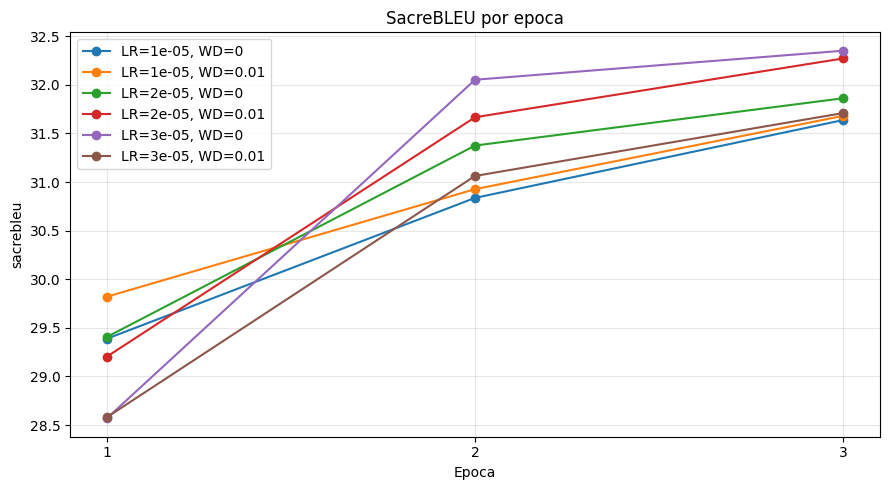

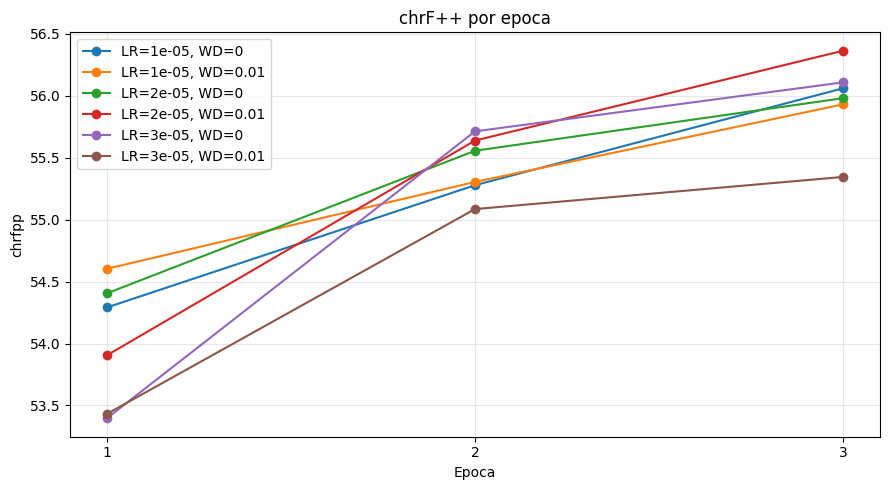

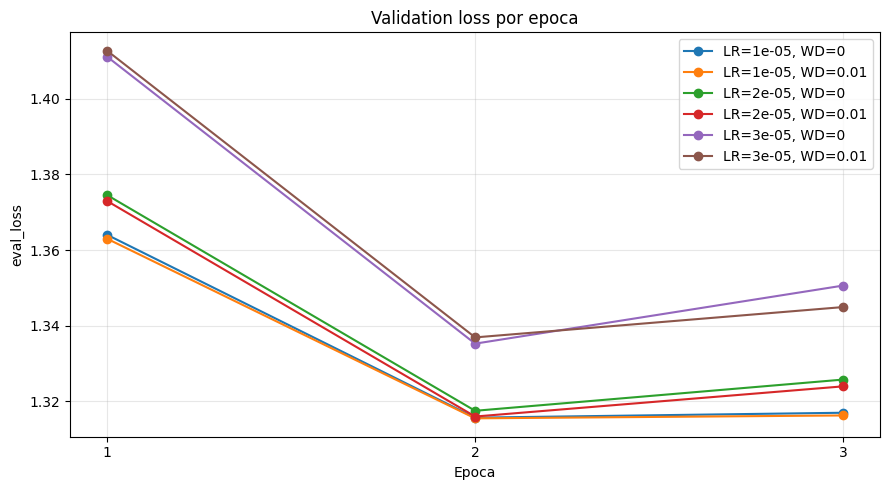

In [ ]:
import matplotlib.pyplot as plt

for metrica, titulo in [("sacrebleu", "SacreBLEU por epoca"), ("chrfpp", "chrF++ por epoca"), ("eval_loss", "Validation loss por epoca")]:
    fig, ax = plt.subplots(figsize=(9, 5))

    for (lr, wd), grupo in df_historial_mt.groupby(["learning_rate", "weight_decay"]):
        grupo = grupo.sort_values("epoca")
        ax.plot(grupo["epoca"], grupo[metrica], marker="o", label=f"LR={lr:g}, WD={wd:g}")

    ax.set(title=titulo, xlabel="Epoca", ylabel=metrica)
    ax.set_xticks([1, 2, 3])
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUTA_BUSQUEDA_MT / f"curvas_{metrica}.png", dpi=150, bbox_inches="tight")
    plt.show()

Se evaluaron seis combinaciones de learning rate y weight decay durante tres épocas, utilizando SacreBLEU como métrica principal de selección, la mejor configuración obtuvo **32,3512 SacreBLEU y 56,1076 chrF++**, con learning rate de **3e-5**, weight decay de **0** y mejor resultado en la tercera época.

Todas las configuraciones mejoraron sus métricas generativas durante las tres épocas. La diferencia entre las dos mejores combinaciones fue pequeña (0,0795 puntos SacreBLEU), por lo que la selección debe interpretarse como provisional.

Para el fine-tuning definitivo se utilizará la configuración seleccionada, con evaluación generativa, early stopping y checkpoints persistentes.

## Fine Tunning definitivo

In [1]:
%pip install -q transformers datasets accelerate sentencepiece sacrebleu

import gc
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from pathlib import Path
from google.colab import drive
from datasets import load_from_disk
from sacrebleu.metrics import BLEU, CHRF
from transformers import (M2M100Tokenizer, M2M100ForConditionalGeneration, DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments, EarlyStoppingCallback, set_seed)

In [2]:
drive.mount("/content/drive")

SEED_MT = 42
MODEL_MT_ID = "facebook/m2m100_418M"
MT_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT")
MT_RESULTADOS = MT_DIR / "resultados"
RUTA_SPLITS_MT = MT_DIR / "dataset_zh_es_70_15_15"
RUTA_ENTRENAMIENTO_MT = MT_DIR / "entrenamiento_final_20k"
RUTA_CHECKPOINTS_MT = RUTA_ENTRENAMIENTO_MT / "checkpoints"
RUTA_MODELO_MT = MT_DIR / "modelo_final_zh_es_20k"

MT_RESULTADOS.mkdir(parents=True, exist_ok=True)
dataset_mt_splits = load_from_disk(str(RUTA_SPLITS_MT))
tokenizer_mt = M2M100Tokenizer.from_pretrained(MODEL_MT_ID, src_lang="zh", tgt_lang="es")
N_TRAIN_FINAL_MT = 20000
N_VAL_FINAL_MT = 1000

train_final_mt = dataset_mt_splits["train"].shuffle(seed=SEED_MT).select(range(N_TRAIN_FINAL_MT))
val_final_mt = dataset_mt_splits["validation"].shuffle(seed=SEED_MT).select(range(N_VAL_FINAL_MT))

def tokenizar_final_mt(lote):
    return tokenizer_mt(lote["chino"], text_target=lote["espanol"], truncation=False)

train_tokens_final_mt = train_final_mt.map(tokenizar_final_mt, batched=True, batch_size=128, remove_columns=train_final_mt.column_names)
val_tokens_final_mt = val_final_mt.map(tokenizar_final_mt, batched=True, batch_size=128, remove_columns=val_final_mt.column_names)

for datos in [train_tokens_final_mt, val_tokens_final_mt]:
    assert max(map(len, datos["input_ids"])) <= 256
    assert max(map(len, datos["labels"])) <= 256

print("GPU:", torch.cuda.get_device_name(0))
print("Transformers:", transformers.__version__)
print("Train definitivo:", len(train_tokens_final_mt))
print("Validation:", len(val_tokens_final_mt))
print("Test reservado:", len(dataset_mt_splits["test"]))

Mounted at /content/drive


tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/3.71M [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 2.42MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

GPU: Tesla T4
Transformers: 5.22.1
Train definitivo: 20000
Validation: 1000
Test reservado: 23976


### Métricas

In [3]:
bleu_final_mt = BLEU(tokenize="13a")
chrf_final_mt = CHRF(word_order=2)

def calcular_metricas_final_mt(eval_pred):
    predicciones = eval_pred.predictions
    etiquetas = eval_pred.label_ids

    if isinstance(predicciones, tuple):
        predicciones = predicciones[0]

    predicciones = np.where(predicciones == -100, tokenizer_mt.pad_token_id, predicciones)
    etiquetas = np.where(etiquetas == -100, tokenizer_mt.pad_token_id, etiquetas)

    textos_pred = [texto.strip() for texto in tokenizer_mt.batch_decode(predicciones, skip_special_tokens=True)]
    textos_ref = [texto.strip() for texto in tokenizer_mt.batch_decode(etiquetas, skip_special_tokens=True)]

    return {
        "sacrebleu": float(bleu_final_mt.corpus_score(textos_pred, [textos_ref]).score),
        "chrfpp": float(chrf_final_mt.corpus_score(textos_pred, [textos_ref]).score)
    }

print("Metricas configuradas: SacreBLEU y chrF++")
print("Metrica principal: SacreBLEU")
print("Idioma destino:", tokenizer_mt.get_lang_id("es"))

Metricas configuradas: SacreBLEU y chrF++
Metrica principal: SacreBLEU
Idioma destino: 128023


## Configurar modelo y entrenamiento

In [4]:
set_seed(SEED_MT)

RUTA_ENTRENAMIENTO_MT.mkdir(parents=True, exist_ok=True)
RUTA_CHECKPOINTS_MT.mkdir(parents=True, exist_ok=True)

CONFIG_FINAL_MT = {
    "modelo": MODEL_MT_ID,
    "transformers_version": transformers.__version__,
    "seed": SEED_MT,
    "train_fingerprint": train_final_mt._fingerprint,
    "validation_fingerprint": val_final_mt._fingerprint,
    "train_size": N_TRAIN_FINAL_MT,
    "validation_size": N_VAL_FINAL_MT,
    "learning_rate": 3e-5,
    "weight_decay": 0.0,
    "num_train_epochs": 6,
    "batch_size": 1,
    "gradient_accumulation_steps": 4,
    "warmup_steps": 1500,
    "eval_save_steps": 2500,
    "generation_max_length": 257,
    "generation_num_beams": 2
}

RUTA_CONFIG_FINAL_MT = RUTA_ENTRENAMIENTO_MT / "configuracion.json"

if RUTA_CONFIG_FINAL_MT.exists():
    with open(RUTA_CONFIG_FINAL_MT, encoding="utf-8") as f:
        config_guardada_mt = json.load(f)
    assert config_guardada_mt == CONFIG_FINAL_MT, "La configuracion no coincide con la guardada"
else:
    assert not list(RUTA_CHECKPOINTS_MT.glob("checkpoint-*")), "Existen checkpoints sin configuracion"
    with open(RUTA_CONFIG_FINAL_MT, "w", encoding="utf-8") as f:
        json.dump(CONFIG_FINAL_MT, f, indent=2)

#liberar modelos y entrenadores anteriores
for nombre in ["trainer_exp_mt", "modelo_exp_mt", "collator_exp_mt", "trainer_final_mt", "modelo_final_mt", "collator_final_mt", "modelo_base_mt", "entradas", "salidas"]:
    if nombre in globals():
        del globals()[nombre]

gc.collect()
torch.cuda.empty_cache()

modelo_final_mt = M2M100ForConditionalGeneration.from_pretrained(MODEL_MT_ID)
modelo_final_mt.config.use_cache = False
modelo_final_mt.generation_config.forced_bos_token_id = tokenizer_mt.get_lang_id("es")
modelo_final_mt.generation_config.max_new_tokens = None
modelo_final_mt.generation_config.max_length = 257
modelo_final_mt.generation_config.num_beams = 2
modelo_final_mt.generation_config.do_sample = False

collator_final_mt = DataCollatorForSeq2Seq(tokenizer=tokenizer_mt, model=modelo_final_mt, padding=True, pad_to_multiple_of=8)
parametros_args_mt = inspect.signature(Seq2SeqTrainingArguments).parameters
ARG_EVAL_MT = "eval_strategy" if "eval_strategy" in parametros_args_mt else "evaluation_strategy"
assert ARG_EVAL_MT in parametros_args_mt

opciones_extra_mt = {ARG_EVAL_MT: "steps"}

if "restore_callback_states_from_checkpoint" in parametros_args_mt:
    opciones_extra_mt["restore_callback_states_from_checkpoint"] = True

args_final_mt = Seq2SeqTrainingArguments(output_dir=str(RUTA_CHECKPOINTS_MT), num_train_epochs=6, per_device_train_batch_size=1,
                                         per_device_eval_batch_size=2, gradient_accumulation_steps=4, learning_rate=3e-5,
                                         warmup_steps=1500, fp16=True, gradient_checkpointing=True, optim="adafactor",
                                         predict_with_generate=True, generation_max_length=257, generation_num_beams=2,
                                         eval_steps=2500, save_steps=2500, save_total_limit=3, load_best_model_at_end=True,
                                         metric_for_best_model="eval_sacrebleu", eval_accumulation_steps=2,
                                         logging_steps=250, data_seed=SEED_MT, **opciones_extra_mt)

trainer_final_mt = Seq2SeqTrainer(model=modelo_final_mt, args=args_final_mt, train_dataset=train_tokens_final_mt,
                                 eval_dataset=val_tokens_final_mt, data_collator=collator_final_mt,
                                 compute_metrics=calcular_metricas_final_mt,
                                 callbacks=[EarlyStoppingCallback(early_stopping_patience=4)])
print("CONFIGURACION FINAL")
print("Learning rate:", args_final_mt.learning_rate)
print("Weight decay:", args_final_mt.weight_decay)
print("Epocas maximas:", args_final_mt.num_train_epochs)
print("Metrica principal:", args_final_mt.metric_for_best_model)
print("Evaluacion y guardado cada:", args_final_mt.eval_steps, "pasos")
print("Checkpoints:", RUTA_CHECKPOINTS_MT)

config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.94GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.94GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

CONFIGURACION FINAL
Learning rate: 3e-05
Weight decay: 0.0
Epocas maximas: 6
Metrica principal: eval_sacrebleu
Evaluacion y guardado cada: 2500 pasos
Checkpoints: /content/drive/MyDrive/Proyecto_02_NLP/MT/entrenamiento_final_20k/checkpoints


## Ejecutar o reanudar Fine Tunning

In [5]:
assert not (RUTA_MODELO_MT / "entrenamiento_completado.json").exists(), "El entrenamiento definitivo ya fue completado"

def checkpoint_valido_mt(ruta):
    necesarios = ["trainer_state.json", "optimizer.pt", "scheduler.pt"]
    if not all((ruta / nombre).is_file() for nombre in necesarios):
        return False

    pesos = list(ruta.glob("*.safetensors")) + list(ruta.glob("pytorch_model*.bin"))
    return len(pesos) > 0

candidatos_mt = [ruta for ruta in RUTA_CHECKPOINTS_MT.glob("checkpoint-*") if ruta.is_dir() and ruta.name.split("-")[-1].isdigit()]
candidatos_mt.sort(key=lambda ruta: int(ruta.name.split("-")[-1]), reverse=True)
ultimo_checkpoint_mt = next((str(ruta) for ruta in candidatos_mt if checkpoint_valido_mt(ruta)), None)

if candidatos_mt and ultimo_checkpoint_mt is None:
    raise RuntimeError("Se encontraron checkpoints, pero ninguno tiene los archivos necesarios")

if ultimo_checkpoint_mt is None:
    print("Iniciando fine-tuning desde M2M100 original")
else:
    print("Reanudando entrenamiento desde:", ultimo_checkpoint_mt)

resultado_final_mt = trainer_final_mt.train(resume_from_checkpoint=ultimo_checkpoint_mt)

assert trainer_final_mt.state.best_model_checkpoint is not None
assert np.isfinite(trainer_final_mt.state.best_metric)

print("\nENTRENAMIENTO FINALIZADO")
print("Pasos:", trainer_final_mt.state.global_step)
print("Mejor SacreBLEU:", round(trainer_final_mt.state.best_metric, 4))
print("Mejor checkpoint:", trainer_final_mt.state.best_model_checkpoint)

#evaluar el mejor modelo cargado al finalizar
metricas_validation_mt = trainer_final_mt.evaluate()

print("\nMETRICAS DEL MEJOR MODELO EN VALIDATION")
print("SacreBLEU:", round(metricas_validation_mt["eval_sacrebleu"], 4))
print("chrF++:", round(metricas_validation_mt["eval_chrfpp"], 4))
print("Validation loss:", round(metricas_validation_mt["eval_loss"], 4))

#guardar el modelo seleccionado y el historial
RUTA_MODELO_MT.mkdir(parents=True, exist_ok=True)
trainer_final_mt.model.config.use_cache = True
trainer_final_mt.save_model(str(RUTA_MODELO_MT))
tokenizer_mt.save_pretrained(str(RUTA_MODELO_MT))

df_historial_final_mt = pd.DataFrame(trainer_final_mt.state.log_history)
df_historial_final_mt.to_csv(RUTA_ENTRENAMIENTO_MT / "historial_entrenamiento.csv", index=False)

resumen_final_mt = {
    "modelo": MODEL_MT_ID,
    "learning_rate": 3e-5,
    "weight_decay": 0.0,
    "train_size": N_TRAIN_FINAL_MT,
    "validation_size": N_VAL_FINAL_MT,
    "pasos": trainer_final_mt.state.global_step,
    "mejor_checkpoint": trainer_final_mt.state.best_model_checkpoint,
    "mejor_sacrebleu": float(trainer_final_mt.state.best_metric),
    "sacrebleu_validation": float(metricas_validation_mt["eval_sacrebleu"]),
    "chrfpp_validation": float(metricas_validation_mt["eval_chrfpp"]),
    "eval_loss_validation": float(metricas_validation_mt["eval_loss"])
}

with open(RUTA_ENTRENAMIENTO_MT / "resumen_final.json", "w", encoding="utf-8") as f:
    json.dump(resumen_final_mt, f, indent=2)

print("\nModelo guardado:", RUTA_MODELO_MT)
print("Historial guardado:", RUTA_ENTRENAMIENTO_MT)

Reanudando entrenamiento desde: /content/drive/MyDrive/Proyecto_02_NLP/MT/entrenamiento_final_20k/checkpoints/checkpoint-12500


[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Step,Training Loss,Validation Loss,Sacrebleu,Chrfpp
15000,3.113240,1.124648,37.900958,60.314263
17500,2.396970,1.129333,39.092445,61.079185
20000,2.318275,1.126384,39.044474,61.019337
22500,1.901118,1.139068,39.185892,61.334317
25000,1.846014,1.133780,39.977810,61.763245
27500,1.547879,1.150908,40.225378,61.797598
30000,1.545438,1.147784,39.935122,61.730391


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Training Loss,Validation Loss,Step,Sacrebleu,Chrfpp
1.545438,1.150908,30000,40.225378,61.797598



METRICAS DEL MEJOR MODELO EN VALIDATION
SacreBLEU: 40.2254
chrF++: 61.7976
Validation loss: 1.1509


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modelo guardado: /content/drive/MyDrive/Proyecto_02_NLP/MT/modelo_final_zh_es_20k
Historial guardado: /content/drive/MyDrive/Proyecto_02_NLP/MT/entrenamiento_final_20k


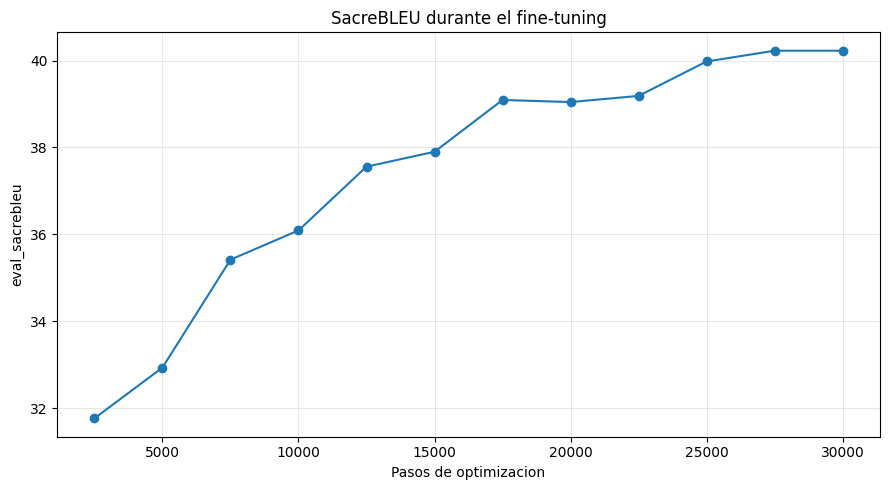

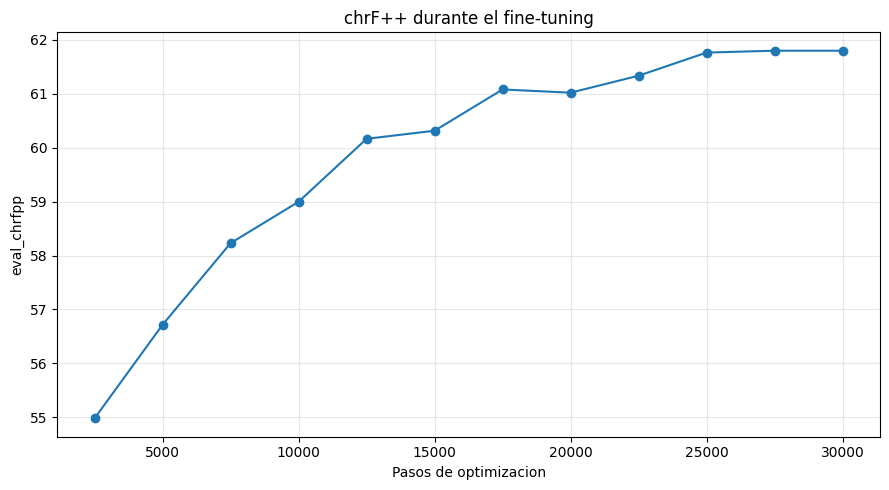

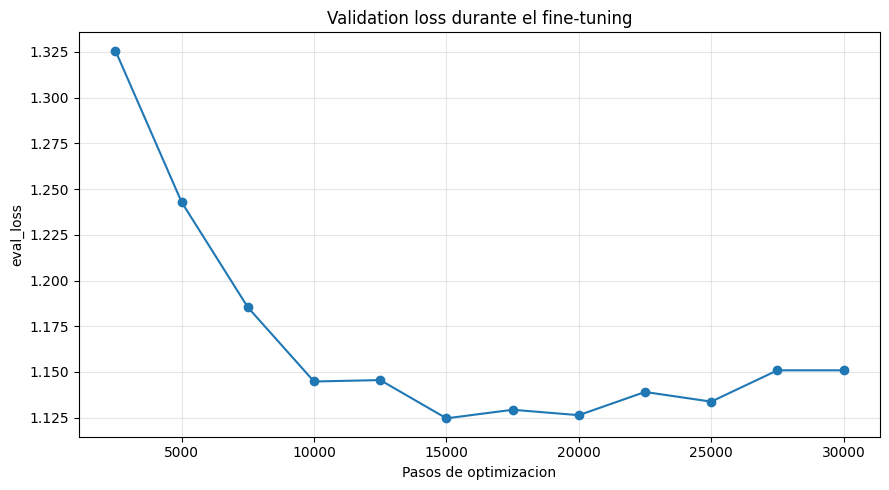

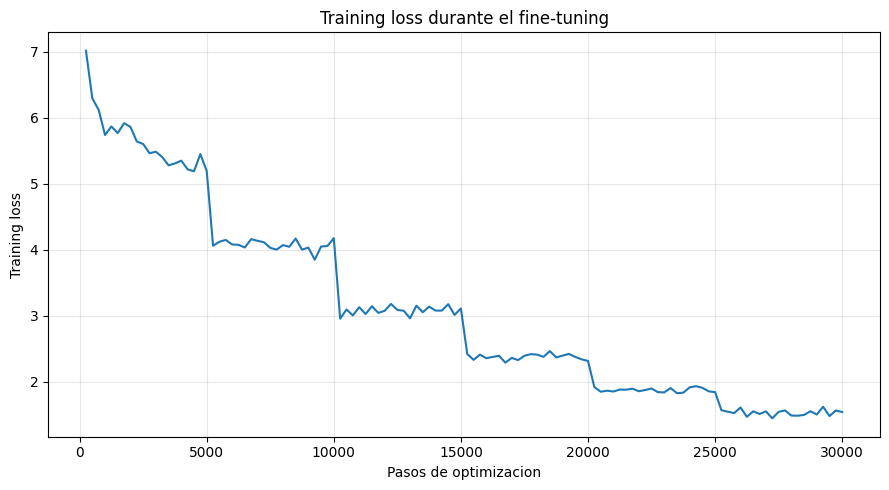

In [6]:
RUTA_HISTORIAL_MT = RUTA_ENTRENAMIENTO_MT / "historial_entrenamiento.csv"

df_historial_final_mt = pd.read_csv(RUTA_HISTORIAL_MT)
df_eval_final_mt = df_historial_final_mt.dropna(subset=["eval_sacrebleu"]).drop_duplicates("step", keep="last")
df_train_loss_mt = df_historial_final_mt.dropna(subset=["loss"])

for columna, titulo in [("eval_sacrebleu", "SacreBLEU durante el fine-tuning"), ("eval_chrfpp", "chrF++ durante el fine-tuning"), ("eval_loss", "Validation loss durante el fine-tuning")]:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(df_eval_final_mt["step"], df_eval_final_mt[columna], marker="o")
    ax.set(title=titulo, xlabel="Pasos de optimizacion", ylabel=columna)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUTA_ENTRENAMIENTO_MT / f"{columna}.png", dpi=150, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_train_loss_mt["step"], df_train_loss_mt["loss"])
ax.set(title="Training loss durante el fine-tuning", xlabel="Pasos de optimizacion", ylabel="Training loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUTA_ENTRENAMIENTO_MT / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

### Verificar modelo guardado

In [7]:
assert (RUTA_ENTRENAMIENTO_MT / "resumen_final.json").exists(), "El entrenamiento no ha finalizado"

for nombre in ["trainer_final_mt", "modelo_final_mt", "collator_final_mt"]:
    if nombre in globals():
        del globals()[nombre]

gc.collect()
torch.cuda.empty_cache()
tokenizer_verificacion_mt = M2M100Tokenizer.from_pretrained(str(RUTA_MODELO_MT), src_lang="zh", tgt_lang="es")
modelo_verificacion_mt = M2M100ForConditionalGeneration.from_pretrained(str(RUTA_MODELO_MT)).to("cuda")
modelo_verificacion_mt.eval()
texto_mt = val_final_mt[0]["chino"]
referencia_mt = val_final_mt[0]["espanol"]
entradas_mt = tokenizer_verificacion_mt(texto_mt, return_tensors="pt").to("cuda")

with torch.inference_mode():
    salida_mt = modelo_verificacion_mt.generate(**entradas_mt, forced_bos_token_id=tokenizer_verificacion_mt.get_lang_id("es"), max_new_tokens=256, num_beams=2, do_sample=False)

traduccion_mt = tokenizer_verificacion_mt.batch_decode(salida_mt, skip_special_tokens=True)[0]

assert traduccion_mt.strip(), "El modelo genero una traduccion vacia"

print("CHINO:", texto_mt)
print("\nREFERENCIA:", referencia_mt)
print("\nTRADUCCION DEL MODELO:", traduccion_mt)
print("\nModelo recuperado correctamente desde Drive")

with open(RUTA_MODELO_MT / "entrenamiento_completado.json", "w", encoding="utf-8") as f:
    json.dump({"verificado": True, "modelo": MODEL_MT_ID}, f, indent=2)

del modelo_verificacion_mt, entradas_mt, salida_mt
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=257) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


CHINO: 2005年12月31日终了的两年期的可比数字如下：收入和行政支出总额分别为118 671 000美元和115 939 000美元；因此，收支相抵盈余额为2 732 000美元。

REFERENCIA: Las cifras correspondientes en el bienio terminado el 31 de diciembre de 2005 fueron: ingresos y gastos administrativos por un total de 118.671.000 dólares y 115.939.000 dólares, respectivamente; en consecuencia, el exceso de los ingresos respecto de los gastos fue de 2.732.000 dólares.

TRADUCCION DEL MODELO: Las cifras comparativas correspondientes al bienio terminado el 31 de diciembre de 2005 son las siguientes: los ingresos y los gastos administrativos ascendieron a 118.671.000 dólares y 115.939.000 dólares, respectivamente; por lo tanto, el saldo de los ingresos respecto de los gastos ascendía a 2.732.000 dólares.

Modelo recuperado correctamente desde Drive


## Evaluación final sobre test

In [1]:
%pip install -q transformers datasets sentencepiece sacrebleu
import gc
import json
import torch
import pandas as pd
from pathlib import Path
from google.colab import drive
from datasets import load_from_disk
from transformers import M2M100Tokenizer, M2M100ForConditionalGeneration
from sacrebleu.metrics import BLEU, CHRF
import numpy as np


MT_RESULTADOS = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT/resultados")

df_resultados_test_mt = pd.read_csv(MT_RESULTADOS / "comparacion_modelos_test.csv")
df_comparacion_mt = pd.read_csv(MT_RESULTADOS / "traducciones_comparadas_test.csv")

assert len(df_comparacion_mt) == 1000
assert set(df_resultados_test_mt["modelo"]) == {"Base", "Fine-tuned"}

print("Resultados de Test cargados")
display(df_resultados_test_mt.round(4))

drive.mount("/content/drive")

SEED_MT = 42
MODEL_MT_ID = "facebook/m2m100_418M"
MT_DIR = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT")
MT_RESULTADOS = MT_DIR / "resultados"
RUTA_MODELO_MT = MT_DIR / "modelo_final_zh_es_20k"
RUTA_SPLITS_MT = MT_DIR / "dataset_zh_es_70_15_15"

assert torch.cuda.is_available(), "Activa la GPU"
assert (RUTA_MODELO_MT / "entrenamiento_completado.json").exists()

dataset_mt_splits = load_from_disk(str(RUTA_SPLITS_MT))
N_TEST_MT = 1000
BATCH_TEST_MT = 2

test_muestra_mt = dataset_mt_splits["test"].shuffle(seed=SEED_MT).select(range(N_TEST_MT))
df_test_mt = test_muestra_mt.to_pandas()[["chino", "espanol"]].reset_index(drop=True)

tokenizer_mt = M2M100Tokenizer.from_pretrained(MODEL_MT_ID, src_lang="zh", tgt_lang="es")

print("Test disponible:", len(dataset_mt_splits["test"]))
print("Test seleccionado:", len(df_test_mt))
print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive


tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/3.71M [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 2.42MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

Test disponible: 23976
Test seleccionado: 1000
GPU: Tesla T4


### Comparar base y fine tuned

In [2]:
modelos_test_mt = {
    "Base": MODEL_MT_ID,
    "Fine-tuned": str(RUTA_MODELO_MT)
}

predicciones_test_mt = {}

for nombre, ruta_modelo in modelos_test_mt.items():
    archivo = MT_RESULTADOS / f"predicciones_{nombre.lower().replace('-', '_')}_test_1000.csv"

    if archivo.exists():
        datos = pd.read_csv(archivo)
        assert datos[["chino", "espanol"]].equals(df_test_mt)
        predicciones_test_mt[nombre] = datos["traduccion"].fillna("").tolist()
        print("Predicciones recuperadas:", nombre)
        continue

    print("\nEvaluando:", nombre)
    modelo = M2M100ForConditionalGeneration.from_pretrained(ruta_modelo).to("cuda")
    modelo.eval()
    modelo.generation_config.max_new_tokens = None

    traducciones = []

    for inicio in range(0, N_TEST_MT, BATCH_TEST_MT):
        lote = df_test_mt.iloc[inicio:inicio + BATCH_TEST_MT]
        entradas = tokenizer_mt(lote["chino"].tolist(), return_tensors="pt", padding=True, truncation=True, max_length=256).to("cuda")

        with torch.inference_mode():
            salidas = modelo.generate(**entradas, forced_bos_token_id=tokenizer_mt.get_lang_id("es"), max_length=257, num_beams=2, do_sample=False)

        traducciones.extend(tokenizer_mt.batch_decode(salidas, skip_special_tokens=True))

    assert len(traducciones) == N_TEST_MT
    predicciones_test_mt[nombre] = traducciones
    df_guardar = df_test_mt.copy()
    df_guardar["traduccion"] = traducciones
    df_guardar.to_csv(archivo, index=False)

    del modelo
    gc.collect()
    torch.cuda.empty_cache()
    print("Predicciones guardadas:", archivo)

bleu_test_mt = BLEU(tokenize="13a")
chrf_test_mt = CHRF(word_order=2)

resultados_test_mt = []

for nombre, predicciones in predicciones_test_mt.items():
    referencias = df_test_mt["espanol"].tolist()
    resultados_test_mt.append({
        "modelo": nombre,
        "ejemplos": N_TEST_MT,
        "sacrebleu": bleu_test_mt.corpus_score(predicciones, [referencias]).score,
        "chrfpp": chrf_test_mt.corpus_score(predicciones, [referencias]).score
    })

df_resultados_test_mt = pd.DataFrame(resultados_test_mt)
df_resultados_test_mt.to_csv(MT_RESULTADOS / "comparacion_modelos_test.csv", index=False)
print("\nCOMPARACION FINAL SOBRE TEST")
display(df_resultados_test_mt.round(4))


Evaluando: Base


config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.94GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.94GB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

Predicciones guardadas: /content/drive/MyDrive/Proyecto_02_NLP/MT/resultados/predicciones_base_test_1000.csv

Evaluando: Fine-tuned


Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

Predicciones guardadas: /content/drive/MyDrive/Proyecto_02_NLP/MT/resultados/predicciones_fine_tuned_test_1000.csv

COMPARACION FINAL SOBRE TEST


,modelo,ejemplos,sacrebleu,chrfpp
0,Base,1000,24.9684,50.1046
1,Fine-tuned,1000,41.0292,62.1839


### Ejemplos comparativos

In [3]:
df_comparacion_mt = df_test_mt.copy()
df_comparacion_mt["M2M100 original"] = predicciones_test_mt["Base"]
df_comparacion_mt["M2M100 ajustado"] = predicciones_test_mt["Fine-tuned"]

display(df_comparacion_mt.sample(10, random_state=SEED_MT).style.set_properties(
    **{"white-space": "normal", "overflow-wrap": "anywhere", "max-width": "400px", "text-align": "left"}
))

df_comparacion_mt.to_csv(MT_RESULTADOS / "traducciones_comparadas_test.csv", index=False)

,chino,espanol,M2M100 original,M2M100 ajustado
521,这相当于450个临时人员工作日，用于支持因为订正2009年审判时间表而增加的工作量。,Con ello se financiarán los 450 días de trabajo de personal temporario que se necesitan para hacer frente al volumen de trabajo adicional que se desprende del calendario revisado de juicios para 2009.,Esto equivale a 450 días de trabajo temporales para apoyar el aumento de la cantidad de trabajo debido a la planificación del calendario de la sentencia de 2009.,Esto representaba 450 días de trabajo temporarios para apoyar el aumento del volumen de trabajo debido al calendario revisado de juicios para 2009.
737,2.2 申诉人声称，白俄罗斯当局于1998年10月发给他一本外国护照，要他前往乌克兰。,"El autor de la queja pretende que, en octubre de 1998, las autoridades de Belarús le suministraron un pasaporte extranjero y le pidieron que se fuese a Ucrania.",2.2 El demandante sostiene que las autoridades bielorrusas le enviaron un pasaporte extranjero en octubre de 1998 para pedirle que viaje a Ucrania.,2.2 El autor de la queja alega que en octubre de 1998 las autoridades de Belarús le expidieron un pasaporte extranjero para que viajara a Ucrania.
740,(b) 占用和拥有面积的成本(即营运费用＋设备维护费/可用面积)；,"b) El costo del espacio ocupado y en propiedad (por ejemplo, costos de funcionamiento + costos de mantenimiento del equipo/área utilizable);","(b) los costos de ocupación y posesión de la superficie (es decir, los costos de operación + los costos de mantenimiento del equipo / la superficie disponible);","b) Gastos en concepto de ocupación y tenencia de tierras (es decir, gastos de funcionamiento + gastos de mantenimiento de equipo/terreno disponible);"
660,由此导致同苏丹南方和北方的当地警察、司法部、总检察长办公室、苏丹解放军和苏丹武装部队以及县专员共享关于严重侵权行为的资料，并通过关于保护平民的义务的会议向民族团结政府和苏丹南方政府的当地行政官员、苏丹解放军和苏丹武装部队军事指挥官、苏丹北方和南方警察部门及达尔富尔其他武装团体进行宣传,"Como consecuencia de ello, se compartió información sobre las violaciones graves con la policía local del Sudán Septentrional y Meridional, los Ministerios de Justicia, la Oficina del Fiscal General, el Ejército de Liberación del Pueblo Sudanés y las Fuerzas Armadas Sudanesas, así como los comisionados de los condados, y se organizaron reuniones para concienciar sobre la obligación de proteger a la población civil a los funcionarios de las administraciones locales, el Gobierno de Unidad Nacional y el Gobierno del Sudán Meridional, los comandantes militares del Ejército de Liberación del Pueblo Sudanés y las Fuerzas Armadas Sudanesas, los cuerpos de policía del Sudán Septentrional y Meridional y los otros grupos armados de Darfur","Esto condujo a la compartición de información sobre violaciones graves de derechos con la policía local, el Departamento de Justicia, el Departamento de Procurador General, el Ejército de Liberación de Sudán y las Fuerzas Armadas de Sudán y los Comisionados de la Región de Sudán, y a la difusión a través de las reuniones sobre la obligación de proteger a los civiles a los funcionarios locales del Gobierno de la Unidad Nacional y del Gobierno del Sur, el Ejército de Liberación de Sudán y el Comandante Militar de las Fuerzas Armadas de Sudán, el Departamento de Policía del Norte y del Sur de Sudán y otros grupos armados de Darfur.","Como resultado de ello, se compartieron información sobre violaciones graves cometidas con la policía local del Sudán Meridional y Norte, el Ministerio de Justicia, la Oficina del Fiscal General, el Ejército de Liberación del Sudán y las Fuerzas Armadas del Sudán, así como con los comisionados de los condados, y se comunicaron a funcionarios de administración local del Gobierno de Unidad Nacional y el Gobierno del Sudán Meridional, el comandante militar de las Fuerzas Armadas del Sudán, las unidades de policía del Sudán Norte y del Sur y otros grupos armados de Darfur mediante reuniones sobre las obligaciones de proteger a los civiles"
411,《国家选举法》于2008年7月7日经国民议会通过，于7月14日经总统签署成为法律,La Asamblea Nacional aprobó la Ley electoral nacional el 7 de julio de 2008 y el Presidente la promulgó el 14 de julio de 2008,La Ley Nacional de Elecciones fue aprobada por el

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sacrebleu.metrics import CHRF

MT_RESULTADOS = Path("/content/drive/MyDrive/Proyecto_02_NLP/MT/resultados")

df_resultados_test_mt = pd.read_csv(MT_RESULTADOS / "comparacion_modelos_test.csv")
df_comparacion_mt = pd.read_csv(MT_RESULTADOS / "traducciones_comparadas_test.csv")

assert len(df_comparacion_mt) == 1000
assert set(df_resultados_test_mt["modelo"]) == {"Base", "Fine-tuned"}

print("Resultados de Test cargados")
display(df_resultados_test_mt.round(4))


Resultados de Test cargados


,modelo,ejemplos,sacrebleu,chrfpp
0,Base,1000,24.9684,50.1046
1,Fine-tuned,1000,41.0292,62.1839


### Comparación de métricas

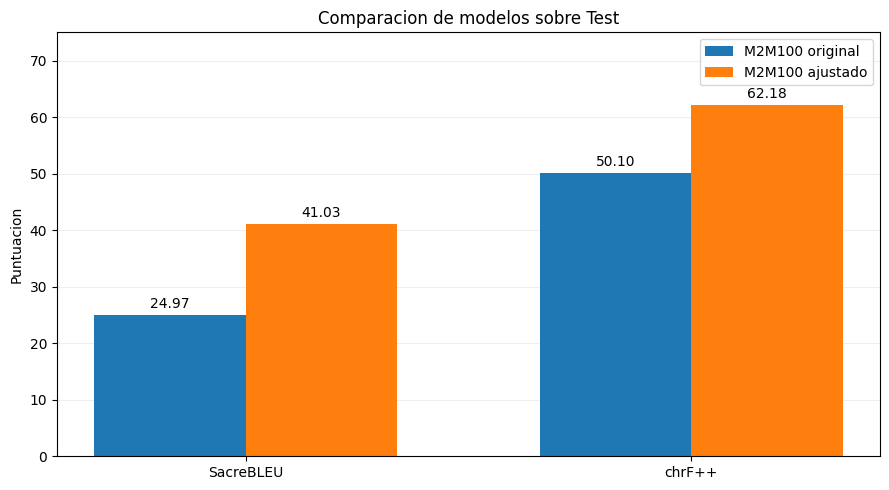

In [8]:
import numpy as np
metricas_mt = ["sacrebleu", "chrfpp"]
etiquetas_mt = ["SacreBLEU", "chrF++"]
resultados_mt = df_resultados_test_mt.set_index("modelo")
base_mt = resultados_mt.loc["Base", metricas_mt].to_numpy(dtype=float)
ajustado_mt = resultados_mt.loc["Fine-tuned", metricas_mt].to_numpy(dtype=float)
x = np.arange(len(metricas_mt))
ancho = 0.34
fig, ax = plt.subplots(figsize=(9, 5))
barras_base = ax.bar(x - ancho / 2, base_mt, ancho, label="M2M100 original")
barras_ajustado = ax.bar(x + ancho / 2, ajustado_mt, ancho, label="M2M100 ajustado")
ax.bar_label(barras_base, fmt="%.2f", padding=3)
ax.bar_label(barras_ajustado, fmt="%.2f", padding=3)

ax.set(title="Comparacion de modelos sobre Test", ylabel="Puntuacion", xticks=x, xticklabels=etiquetas_mt, ylim=(0, 75))
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(MT_RESULTADOS / "comparacion_metricas_test.png", dpi=180, bbox_inches="tight")
plt.show()

### Distribución de mejora por traducción

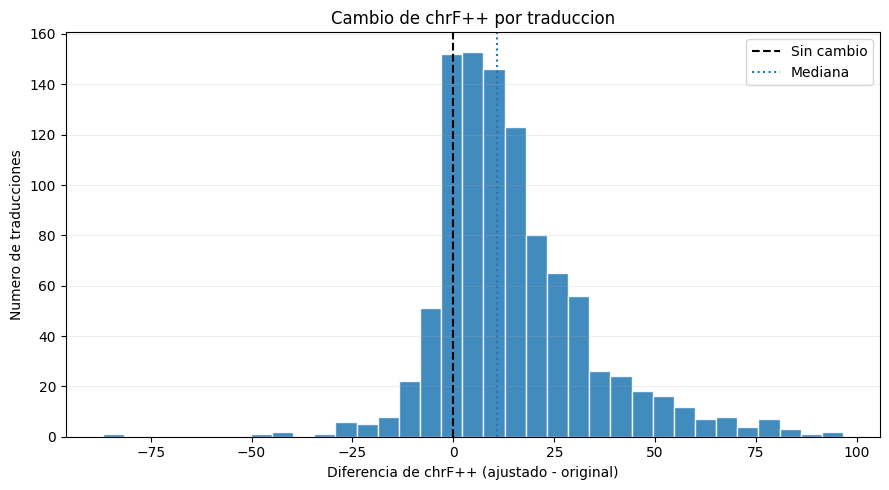

Traducciones que mejoran: 816
Traducciones que empeoran: 159
Traducciones sin cambio: 25
Mediana de la diferencia: 10.9253


In [9]:
metrica_oracion_mt = CHRF(word_order=2)
referencias_mt = df_comparacion_mt["espanol"].fillna("").tolist()
originales_mt = df_comparacion_mt["M2M100 original"].fillna("").tolist()
ajustadas_mt = df_comparacion_mt["M2M100 ajustado"].fillna("").tolist()

scores_original_mt = np.array([metrica_oracion_mt.sentence_score(pred, [ref]).score for pred, ref in zip(originales_mt, referencias_mt)])
scores_ajustado_mt = np.array([metrica_oracion_mt.sentence_score(pred, [ref]).score for pred, ref in zip(ajustadas_mt, referencias_mt)])
diferencias_mt = scores_ajustado_mt - scores_original_mt
mejoran_mt = np.sum(diferencias_mt > 1e-6)
empeoran_mt = np.sum(diferencias_mt < -1e-6)
iguales_mt = len(diferencias_mt) - mejoran_mt - empeoran_mt

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(diferencias_mt, bins=35, edgecolor="white", alpha=0.85)
ax.axvline(0, color="black", linestyle="--", label="Sin cambio")
ax.axvline(np.median(diferencias_mt), linestyle=":", label="Mediana")
ax.set(title="Cambio de chrF++ por traduccion", xlabel="Diferencia de chrF++ (ajustado - original)", ylabel="Numero de traducciones")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(MT_RESULTADOS / "distribucion_mejora_test.png", dpi=180, bbox_inches="tight")
plt.show()

print("Traducciones que mejoran:", mejoran_mt)
print("Traducciones que empeoran:", empeoran_mt)
print("Traducciones sin cambio:", iguales_mt)
print("Mediana de la diferencia:", round(np.median(diferencias_mt), 4))

## Conclusiones

Se realizó el fine-tuning del modelo M2M100-418M para traducción automática chino-español, utilizando 20.000 pares de entrenamiento del corpus UN Parallel Corpus. Se seleccionaron los hiperparámetros mediante SacreBLEU de Validation y se recuperó el mejor checkpoint del entrenamiento definitivo.

En una muestra fija de 1.000 pares de Test, el modelo original obtuvo **24,9684 SacreBLEU y 50,1046 chrF++**, mientras que el modelo ajustado alcanzó **41,0292 SacreBLEU y 62,1839 chrF++**. Esto representa mejoras absolutas de **16,0608 y 12,0793 puntos**, respectivamente.

El análisis individual mediante chrF++ mostró que el modelo ajustado mejoró en **816 traducciones (81,6 %)**, empeoró en 159 (15,9 %) y mantuvo la misma puntuación en 25 (2,5 %). La mediana de las diferencias fue de **+10,9253 puntos**, lo que evidencia una mejora generalizada en la muestra evaluada.

No obstante, persisten errores de traducción y casos donde el fine-tuning reduce la calidad. Además, el corpus utilizado pertenece principalmente al ámbito institucional, por lo que los resultados no garantizan el mismo rendimiento en otros dominios.

En conclusión, el fine-tuning permitió adaptar M2M100 al dominio del corpus y mejorar significativamente sus métricas de traducción. La evaluación conjunta de métricas globales y resultados individuales permitió identificar tanto las mejoras como las limitaciones del modelo.

# Demostración de los modelos entrenados

En esta sección se realizan inferencias utilizando los tres modelos ajustados durante el proyecto, recuperados directamente desde Google Drive

Las pruebas permiten ingresar textos nuevos para clasificación de reseñas y reconocimiento de entidades nombradas

Para traducción chino-español se ofrecen dos modalidades: ingresar una oración manualmente o seleccionar un ejemplo aleatorio del conjunto Test


## Cargar los modelos

In [1]:
%pip install -q transformers datasets sentencepiece ipywidgets

In [2]:
import re
import secrets
from pathlib import Path

import pandas as pd
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output
from datasets import load_from_disk
from google.colab import drive, output
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForTokenClassification, M2M100Tokenizer, M2M100ForConditionalGeneration,)

drive.mount("/content/drive")
output.enable_custom_widget_manager()
RAIZ_DEMO = Path("/content/drive/MyDrive/Proyecto_02_NLP")
RUTA_CLASIFICACION_DEMO = RAIZ_DEMO / "beto_final"
RUTA_NER_DEMO = RAIZ_DEMO / "NER" / "modelo_final"
RUTA_MT_DEMO = RAIZ_DEMO / "MT" / "modelo_final_zh_es_20k"
RUTA_TEST_MT_DEMO = RAIZ_DEMO / "MT" / "dataset_zh_es_70_15_15"
DISPOSITIVO_DEMO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for ruta in (RUTA_CLASIFICACION_DEMO, RUTA_NER_DEMO, RUTA_MT_DEMO):
    assert (ruta / "config.json").is_file(), f"Modelo no encontrado: {ruta}"

assert RUTA_TEST_MT_DEMO.is_dir(), "No se encontro el dataset MT"

print("Dispositivo:", DISPOSITIVO_DEMO)
print("Cargando modelos desde Drive")
tok_clas_de = AutoTokenizer.from_pretrained(str(RUTA_CLASIFICACION_DEMO), use_fast=True)
mod_clas_de = AutoModelForSequenceClassification.from_pretrained(str(RUTA_CLASIFICACION_DEMO)).to(DISPOSITIVO_DEMO).eval()
tok_ner_de = AutoTokenizer.from_pretrained(str(RUTA_NER_DEMO), use_fast=True)
mod_ner_de = AutoModelForTokenClassification.from_pretrained(str(RUTA_NER_DEMO)).to(DISPOSITIVO_DEMO).eval()
tok_mt_de = M2M100Tokenizer.from_pretrained(str(RUTA_MT_DEMO), src_lang="zh", tgt_lang="es")
mod_mt_de = M2M100ForConditionalGeneration.from_pretrained(str(RUTA_MT_DEMO)).to(DISPOSITIVO_DEMO).eval()
mod_mt_de.generation_config.max_new_tokens = None
print("Tres modelos listos para inferencia")

Mounted at /content/drive
Dispositivo: cuda
Cargando modelos desde Drive


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:01<?, ?it/s]

Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

Tres modelos listos para inferencia


## Demostración Sequence Classification

In [4]:
resena_de = widgets.Textarea(value="El producto tiene buena calidad, pero llegó tarde y el empaque estaba dañado", description="Resena:", layout=widgets.Layout(width="95%", height="85px"))
boton_clas_de = widgets.Button(description="Clasificar resena", button_style="primary")
salida_clas_de = widgets.Output()

def ejecutar_clas_de(_):
    with salida_clas_de:
        clear_output(wait=True)

        texto = resena_de.value.strip()
        if not texto:
            print("Ingresa una resena")
            return

        entradas = tok_clas_de(texto, return_tensors="pt", truncation=True, max_length=128).to(DISPOSITIVO_DEMO)
        with torch.inference_mode():
            logits = mod_clas_de(**entradas).logits[0]
            probabilidades = torch.softmax(logits, dim=-1).cpu().numpy()

        clase = int(probabilidades.argmax()) + 1
        print("Calificacion predicha:", clase, "estrellas")

        tabla = pd.DataFrame({
            "Calificacion": [f"{n} estrellas" for n in range(1, 6)],
            "Probabilidad": probabilidades
        })

        display(tabla.style.format({"Probabilidad": "{:.2%}"}))

boton_clas_de.on_click(ejecutar_clas_de)
display(widgets.VBox([widgets.HTML("<h4>1. Clasificacion de resenas</h4>"), resena_de, boton_clas_de, salida_clas_de]))

## Demostración Sequence Labeling

In [5]:
texto_ner_de = widgets.Textarea(value="Gabriel García Márquez nació en Colombia y visitó Madrid para reunirse con representantes de la ONU", description="Texto:", layout=widgets.Layout(width="95%", height="85px"))
boton_ner_de = widgets.Button(description="Detectar entidades", button_style="primary")
salida_ner_de = widgets.Output()

def ejecutar_ner_de(_):
    with salida_ner_de:
        clear_output(wait=True)

        texto = texto_ner_de.value.strip()
        if not texto:
            print("Ingresa una oracion")
            return

        coincidencias = list(re.finditer(r"\w+(?:[-’']\w+)*|[^\w\s]", texto, flags=re.UNICODE))
        palabras = [m.group() for m in coincidencias]
        entradas = tok_ner_de(palabras, is_split_into_words=True, return_tensors="pt", truncation=True, max_length=256)
        word_ids = entradas.word_ids(batch_index=0)
        primera_posicion = {}

        for pos, word_id in enumerate(word_ids):
            if word_id is not None and word_id not in primera_posicion:
                primera_posicion[word_id] = pos

        if len(primera_posicion) != len(palabras):
            print("Texto demasiado largo para NER, usa uno mas corto")
            return

        with torch.inference_mode():
            logits = mod_ner_de(**entradas.to(DISPOSITIVO_DEMO)).logits[0]

        indices = logits.argmax(dim=-1).cpu().tolist()
        etiquetas = [mod_ner_de.config.id2label[indices[primera_posicion[i]]] for i in range(len(palabras))]
        entidades = []
        tipo_actual, inicio = None, None

        for i, etiqueta in enumerate(etiquetas + ["O"]):
            tipo = etiqueta[2:] if etiqueta.startswith(("B-", "I-")) else None
            continuar = (tipo_actual is not None and tipo == tipo_actual and etiqueta.startswith("I-"))

            if tipo_actual is not None and not continuar:
                fragmento = texto[coincidencias[inicio].start():coincidencias[i - 1].end()]
                entidades.append({"Entidad": fragmento, "Tipo": tipo_actual})
                tipo_actual, inicio = None, None

            if tipo is not None and tipo_actual is None:
                tipo_actual, inicio = tipo, i

        if entidades:
            display(pd.DataFrame(entidades))
        else:
            print("No se detectaron entidades")

        display(pd.DataFrame({"Token": palabras, "Etiqueta BIO": etiquetas}))

boton_ner_de.on_click(ejecutar_ner_de)
display(widgets.VBox([widgets.HTML("<h4>2. Reconocimiento de entidades</h4>"), texto_ner_de, boton_ner_de, salida_ner_de]))

## Demostración Sequence To Sequence

In [3]:
test_mt_de = load_from_disk(str(RUTA_TEST_MT_DEMO))["test"]

indices_cortos_mt_de = [i for i, chino in enumerate(test_mt_de["chino"]) if 10 <= len(chino) <= 150]

assert indices_cortos_mt_de, "No se encontraron ejemplos para la demostracion"

modo_mt_de = widgets.RadioButtons(
    options=[("Escribir una frase en chino", "manual"), ("Elegir una frase aleatoria de Test", "aleatorio")],
    value="manual",
    description="Modo:"
)

chino_mt_de = widgets.Textarea(value="联合国致力于维护国际和平与安全。", description="Chino:", layout=widgets.Layout(width="95%", height="85px"))
boton_mt_de = widgets.Button(description="Traducir", button_style="primary")
salida_mt_de = widgets.Output()

def ejecutar_mt_de(_):
    with salida_mt_de:
        clear_output(wait=True)

        if modo_mt_de.value == "aleatorio":
            i = secrets.choice(indices_cortos_mt_de)
            ejemplo = test_mt_de[i]
            chino, referencia = ejemplo["chino"], ejemplo["espanol"]
            print("Ejemplo aleatorio de Test:", i)
        else:
            chino, referencia = chino_mt_de.value.strip(), None

        if not chino:
            print("Ingresa una frase en chino")
            return

        entradas = tok_mt_de(chino, return_tensors="pt", truncation=False)

        if entradas["input_ids"].shape[1] > 256:
            print("Texto demasiado largo para el limite de 256 tokens")
            return

        print("Texto chino:", chino)

        with torch.inference_mode():
            prediccion = mod_mt_de.generate(**entradas.to(DISPOSITIVO_DEMO), forced_bos_token_id=tok_mt_de.get_lang_id("es"), max_length=257, num_beams=2, do_sample=False)

        traduccion = tok_mt_de.batch_decode(prediccion, skip_special_tokens=True)[0]
        print("Traduccion del modelo:", traduccion)
        if referencia is not None:
            print("Referencia del dataset:", referencia)

boton_mt_de.on_click(ejecutar_mt_de)
display(widgets.VBox([widgets.HTML("<h4>3. Traduccion chino a espanol</h4>"), modo_mt_de, chino_mt_de, boton_mt_de, salida_mt_de]))